In [4]:
!pip uninstall pandas-profiling

In [5]:
! pip install https://github.com/pandas-profiling/pandas-profiling/archive/master.zip

  Using cached https://github.com/pandas-profiling/pandas-profiling/archive/master.zip
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [6]:
from __future__ import division

from matplotlib import pyplot as plt
from matplotlib import patches as patches
from copy import deepcopy
from IPython.display import clear_output

import numpy as np
import json
import random

import pandas as pd
from pandas_profiling import ProfileReport
from sklearn.preprocessing import MinMaxScaler

import IPython
from sklearn.cluster import KMeans

/tmp/ipykernel_807/3446913888.py:13: DeprecationWarning: `import pandas_profiling` is going to be deprecated by April 1st. Please use `import ydata_profiling` instead.
  from pandas_profiling import ProfileReport


In [7]:
np.random.seed(10311)
random.seed(10311)

In [8]:
dataset = pd.read_csv("world-data.csv")

In [9]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 35 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Country                                    195 non-null    object 
 1   Density
(P/Km2)                            195 non-null    object 
 2   Abbreviation                               188 non-null    object 
 3   Agricultural Land( %)                      188 non-null    object 
 4   Land Area(Km2)                             194 non-null    object 
 5   Armed Forces size                          171 non-null    object 
 6   Birth Rate                                 189 non-null    float64
 7   Calling Code                               194 non-null    float64
 8   Capital/Major City                         192 non-null    object 
 9   Co2-Emissions                              188 non-null    object 
 10  CPI                       

# Dataset 1

In [10]:
unique_languages = dataset['Official language'].dropna().unique()
print(f"Number of unique official languages: {len(unique_languages)}")
print("Unique official languages:", unique_languages)

Number of unique official languages: 76
Unique official languages: ['Pashto' 'Albanian' 'Arabic' 'Catalan' 'Portuguese' 'English' 'Spanish'
 'Armenian' 'German' 'Azerbaijani language' 'Bengali' 'Russian' 'French'
 'Dzongkha' 'Bosnian' 'Malay' 'Bulgarian' 'Kirundi' 'Khmer language'
 'Standard Chinese' 'Croatian' 'Greek' 'Czech' 'Danish'
 'Modern Standard Arabic' 'Tigrinya' 'Estonian' 'Amharic' 'Fiji Hindi'
 'Swedish' 'Georgian' 'Italian' 'Hungarian' 'Icelandic' 'Hindi'
 'Indonesian' 'Persian' 'Irish' 'Hebrew' 'Jamaican English' 'Swahili'
 'Lao' 'Latvian' 'Lithuanian' 'Luxembourgish' 'Malaysian language'
 'Divehi' 'Maltese' 'Marshallese' 'Romanian' 'Mongolian'
 'Montenegrin language' 'Burmese' 'Nepali' 'Dutch' 'Korean' 'Macedonian'
 'Norwegian' 'Urdu' 'Tok Pisin' 'Polish' 'Samoan' 'Serbian' 'Slovak'
 'Slovene language' 'Afrikaans' 'Tamil' 'Thai' 'Tongan Language' 'Turkish'
 'Turkmen' 'Tuvaluan Language' 'Ukrainian' 'Uzbek' 'Vietnamese' 'Shona']


In [11]:
language_counts = dataset['Official language'].value_counts()
print("Number of countries per unique official language:")
print(language_counts.head(30))

Number of countries per unique official language:
Official language
English                   31
French                    25
Spanish                   19
Arabic                    18
Portuguese                 7
Russian                    4
Swahili                    4
German                     4
Italian                    3
Malay                      2
Persian                    2
Swedish                    2
Korean                     2
Dutch                      2
Romanian                   2
Greek                      2
Modern Standard Arabic     2
Pashto                     1
Albanian                   1
Catalan                    1
Bengali                    1
Azerbaijani language       1
Armenian                   1
Standard Chinese           1
Bulgarian                  1
Khmer language             1
Czech                      1
Croatian                   1
Amharic                    1
Estonian                   1
Name: count, dtype: int64


In [12]:
#lang = dataset["Official language"].astype("string").str.strip()

#lang = lang.fillna("Unknown")

#counts = lang.value_counts()
#keep_langs = counts[counts >= 2].index
#lang = lang.where(lang.isin(keep_langs), "Other")

#lang_ohe = pd.get_dummies(lang, prefix="lang", dtype=float)

#dataset = dataset.drop(columns=["Official language"]).join(lang_ohe)

#print("Idiomas únicos (antes de agrupar):", counts.shape[0])
#print("Idiomas únicos (después de agrupar):", lang.nunique())
#print("Columnas nuevas creadas:", len(lang_ohe.columns))
#print(lang.value_counts().head(15))

In [13]:
# Perform count encoding to Official languages
language_counts = dataset['Official language'].value_counts()
dataset['Official_language_Count_Encoded'] = dataset['Official language'].map(language_counts)

Primero identificamos las key features y descartamos las que nos nos ayudan en el entrenamiento, comenzaremos descartando: Abbreviation, Capital/Major City, Largest City, Currency-Code, Official Language

In [14]:
dataset = dataset.drop('Abbreviation', axis = 1)
dataset = dataset.drop('Capital/Major City', axis = 1)
dataset = dataset.drop('Largest city', axis = 1)
dataset = dataset.drop('Calling Code', axis = 1)
dataset = dataset.drop('Currency-Code', axis = 1)
dataset = dataset.drop(columns=["Official language"])

In [15]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 30 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Country                                    195 non-null    object 
 1   Density
(P/Km2)                            195 non-null    object 
 2   Agricultural Land( %)                      188 non-null    object 
 3   Land Area(Km2)                             194 non-null    object 
 4   Armed Forces size                          171 non-null    object 
 5   Birth Rate                                 189 non-null    float64
 6   Co2-Emissions                              188 non-null    object 
 7   CPI                                        178 non-null    object 
 8   CPI Change (%)                             179 non-null    object 
 9   Fertility Rate                             188 non-null    float64
 10  Forested Area (%)         

In [16]:
null_counts = dataset.isnull().sum()
columns_with_nulls = null_counts[null_counts > 0]

print("Columns with null values and their counts:")
print(columns_with_nulls)

Columns with null values and their counts:
Agricultural Land( %)                         7
Land Area(Km2)                                1
Armed Forces size                            24
Birth Rate                                    6
Co2-Emissions                                 7
CPI                                          17
CPI Change (%)                               16
Fertility Rate                                7
Forested Area (%)                             7
Gasoline Price                               20
GDP                                           2
Gross primary education enrollment (%)        7
Gross tertiary education enrollment (%)      12
Infant mortality                              6
Life expectancy                               8
Maternal mortality ratio                     14
Minimum wage                                 45
Out of pocket health expenditure              7
Physicians per thousand                       7
Population                                   

In [17]:
dataset.head(10)

,Country,Density\n(P/Km2),Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Co2-Emissions,CPI,CPI Change (%),Fertility Rate,...,Physicians per thousand,Population,Population: Labor force participation (%),Tax revenue (%),Total tax rate,Unemployment rate,Urban_population,Latitude,Longitude,Official_language_Count_Encoded
0,Afghanistan,60,58.10%,"652,230","323,000",32.49,"8,672",149.9,2.30%,4.47,...,0.28,"38,041,754",48.90%,9.30%,71.40%,11.12%,"9,797,273",33.939110,67.709953,1.0
1,Albania,105,43.10%,"28,748","9,000",11.78,"4,536",119.05,1.40%,1.62,...,1.20,"2,854,191",55.70%,18.60%,36.60%,12.33%,"1,747,593",41.153332,20.168331,1.0
2,Algeria,18,17.40%,"2,381,741","317,000",24.28,"150,006",151.36,2.00%,3.02,...,1.72,"43,053,054",41.20%,37.20%,66.10%,11.70%,"31,510,100",28.033886,1.659626,18.0
3,Andorra,164,40.00%,468,NaN,7.20,469,NaN,NaN,1.27,...,3.33,"77,142",NaN,NaN,NaN,NaN,"67,873",42.506285,1.521801,1.0
4,Angola,26,47.50%,"1,246,700","117,000",40.73,"34,693",261.73,17.10%,5.52,...,0.21,"31,825,295",77.50%,9.20%,49.10%,6.89%,"21,061,025",-11.202692,17.873887,7.0
5,Antigua and Barbuda,223,20.50%,443,0,15.33,557,113.81,1.20%,1.99,...,2.76,"97,118",NaN,16.50%,43.00%,NaN,"23,800",17.060816,-61.796428,31.0
6,Argentina,17,54.30%,"2,780,400","105,000",17.02,"201,348",232.75,53.50%,2.26,...,3.96,"44,938,712",61.30%,10.10%,106.30%,9.79%,"41,339,571",-38.416097,-63.616672,19.0
7,Armenia,104,58.90%,"29,743","49,000",13.99,"5,156",129.18,1.40%,1.76,...,4.40,"2,957,731",55.60%,20.90%,22.60%,16.99%,"1,869,848",40.069099,45.038189,1.0
8,Australia,3,48.20%,"7,741,220","58,000",12.60,"375,908",119.8,1.60%,1.74,...,3.68,"25,766,605",65.50%,23.00%,47.40%,5.27%,"21,844,756",-25.274398,133.775136,NaN
9,Austria,109,32.40%,"83,871","21,000",9.70,"61,448",118.06,1.50%,1.47,...,5.17,"8,877,067",60.70%,25.40%,51.40%,4.67%,"5,194,416",47.516231,14.550072,4.0


 ahora lo que hacemos es establecer la columna country como index del dataset

In [18]:
dataset = dataset.set_index("Country")

In [19]:
dataset = dataset.rename(index={'S�����������': 'Sao Tome & Principe'})

Ahora mismo muchas variables numéricas están cargadas como object/string porque, aunque representan números, incluyen caracteres no numéricos (por ejemplo %, $, comas o espacios). Antes de convertirlas a tipo numérico necesitamos saber qué símbolos aparecen realmente en el dataset, porque el tratamiento depende del significado: no es lo mismo una coma usada como separador de miles que una coma usada como separador decimal, y un % implica además una conversión (dividir entre 100).

Por eso, en este paso recorremos todas las columnas numéricas en formato texto y extraemos el conjunto de caracteres distintos que acompañan a los dígitos. Además, para cada carácter encontrado imprimimos un ejemplo real del dataset donde aparece, para verificar si:

es un formato esperado (p. ej. . como decimal, , como miles, - como negativo, $ como moneda, % como porcentaje), o

es un problema de formato que requiera una corrección específica.

Con esta inspección evitamos aplicar transformaciones innecesarias o equivocadas y definimos una limpieza mínima y correcta para el parseo numérico.

In [20]:
global_chars = set()
example_for_char = {}

for col in dataset.columns:
    for v in dataset[col].astype(str):
        nd = {ch for ch in v if not ch.isdigit()}
        if nd:
            global_chars |= nd
            for ch in nd:
                if ch not in example_for_char:
                    example_for_char[ch] = (col, v)

print("Non Numeric Characters:")
print(sorted(global_chars))

print("\nExample per character:")
for ch in sorted(example_for_char):
    col, val = example_for_char[ch]
    print(f"{repr(ch)} -> columna: {col} | valor: {val}")

Non Numeric Characters:
[' ', '$', '%', ',', '-', '.', 'a', 'n']

Example per character:
' ' -> columna: Gasoline Price | valor: $0.70 
'$' -> columna: Gasoline Price | valor: $0.70 
'%' -> columna: Agricultural Land( %) | valor: 58.10%
',' -> columna: Density
(P/Km2) | valor: 2,239
'-' -> columna: CPI Change (%) | valor: -0.90%
'.' -> columna: Agricultural Land( %) | valor: 58.10%
'a' -> columna: Agricultural Land( %) | valor: nan
'n' -> columna: Agricultural Land( %) | valor: nan


Una vez tenemos identificados los diferentes caracteres que aparecen y si son errores o no, procedemos a procesarlos y transformar las variables a numéricas para que podamos realizar el entrenamiento del SOM, para ello lo que hemos hecho es eliminar símbolos que no aportan valor numérico: espacios, $ y el separador de miles ,.

Quitamos el símbolo % y, además, dividimos entre 100 para convertirlos a fracción (por ejemplo, 58.10% → 0.581).

Finalmente, convertimos el resultado a tipo numérico (float) para que todas las columnas queden listas para el preprocesado y entrenamiento.

In [21]:
pct_cols = dataset.astype(str).apply(lambda s: s.str.contains('%').any())

dataset = dataset.astype(str).apply(lambda s: pd.to_numeric(
    s.str.replace(' ', '', regex=False)
     .str.replace('$', '', regex=False)
     .str.replace(',', '', regex=False)
     .str.replace('%', '', regex=False),
    errors='coerce'
))


dataset.loc[:, pct_cols] = dataset.loc[:, pct_cols] / 100.0

Hacemos un dataset info para comprobar que no quedan o que no han generado nuevos valores nulos dentro del dataset

In [22]:
null_counts = dataset.isnull().sum()
columns_with_nulls = null_counts[null_counts > 0]

# Sort columns with nulls by their count
sorted_columns_with_nulls = columns_with_nulls.sort_values(ascending=False)

print("Columns with null values, sorted by count, and their ranges:")
for col_name, null_count in sorted_columns_with_nulls.items():
    # Calculate min and max for each column
    min_val = dataset[col_name].min()
    max_val = dataset[col_name].max()
    print(f"- {col_name}: Nulls = {null_count}, Range = [{min_val} - {max_val}]")

Columns with null values, sorted by count, and their ranges:
- Minimum wage: Nulls = 45, Range = [0.01 - 13.59]
- Tax revenue (%): Nulls = 26, Range = [0.0 - 0.37200000000000005]
- Armed Forces size: Nulls = 24, Range = [0.0 - 3031000.0]
- Gasoline Price: Nulls = 20, Range = [0.0 - 2.0]
- Unemployment rate: Nulls = 19, Range = [0.0009 - 0.2818]
- Population: Labor force participation (%): Nulls = 19, Range = [0.38 - 0.868]
- CPI: Nulls = 17, Range = [99.03 - 4583.71]
- CPI Change (%): Nulls = 16, Range = [-0.043 - 2.549]
- Maternal mortality ratio: Nulls = 14, Range = [2.0 - 1150.0]
- Total tax rate: Nulls = 12, Range = [0.08 - 2.1959999999999997]
- Gross tertiary education enrollment (%): Nulls = 12, Range = [0.008 - 1.3659999999999999]
- Life expectancy: Nulls = 8, Range = [52.8 - 85.4]
- Out of pocket health expenditure: Nulls = 7, Range = [0.002 - 0.816]
- Physicians per thousand: Nulls = 7, Range = [0.01 - 8.42]
- Forested Area (%): Nulls = 7, Range = [0.0 - 0.983]
- Gross primary

In [23]:
min_wage_min = dataset['Minimum wage'].min()
min_wage_max = dataset['Minimum wage'].max()

print(f"Minimum wage range: {min_wage_min} - {min_wage_max}")

Minimum wage range: 0.01 - 13.59


In [24]:
median_minimum_wage = dataset['Minimum wage'].median()

In [25]:
dataset['Minimum Wage Yes/NO'] = np.where(dataset['Minimum wage'].notna(), 1, 0)

In [26]:
dataset['Minimum wage'] = dataset['Minimum wage'].fillna(median_minimum_wage)

In [27]:
# 1) Lista de columnas con más de 9 nulos
cols_mas_9_nulos = dataset.columns[dataset.isna().sum() > 9].tolist()
print("Columnas con >9 nulos:", cols_mas_9_nulos)

for col in cols_mas_9_nulos:
    s = pd.to_numeric(dataset[col], errors="coerce")

    if s.notna().sum() == 0:
        print(f"[SKIP] {col}: todos son NaN tras convertir a numérico.")
        continue

    print(f"{col} range: {s.min()} - {s.max()}")

    median_val = s.median()

    # 1 = faltaba el dato (missing), 0 = estaba
    bin_col = f"{col}_missing"
    dataset[bin_col] = s.isna().astype(int)

    dataset[col] = s.fillna(median_val)

Columnas con >9 nulos: ['Armed Forces size', 'CPI', 'CPI Change (%)', 'Gasoline Price', 'Gross tertiary education enrollment (%)', 'Maternal mortality ratio', 'Population: Labor force participation (%)', 'Tax revenue (%)', 'Total tax rate', 'Unemployment rate']
Armed Forces size range: 0.0 - 3031000.0
CPI range: 99.03 - 4583.71
CPI Change (%) range: -0.043 - 2.549
Gasoline Price range: 0.0 - 2.0
Gross tertiary education enrollment (%) range: 0.008 - 1.3659999999999999
Maternal mortality ratio range: 2.0 - 1150.0
Population: Labor force participation (%) range: 0.38 - 0.868
Tax revenue (%) range: 0.0 - 0.37200000000000005
Total tax rate range: 0.08 - 2.1959999999999997
Unemployment rate range: 0.0009 - 0.2818


In [28]:
demo_salud = [
    "Life expectancy", "Physicians per thousand", "Out of pocket health expenditure",
    "Fertility Rate", "Birth Rate", "Infant mortality", "Urban_population"
]
economia = [
    "GDP"
]
medioambiente = [
    "Forested Area", "Co2-Emissions", "Agricultural Land"
]
educacion = [
    "Gross primary education enrollment (%)", "Gross tertiary education enrollment (%)"
]

In [29]:
def existing(cols, df):
    return [c for c in cols if c in df.columns]

demo_salud = existing(demo_salud, dataset)
economia = existing(economia, dataset)
medioambiente = existing(medioambiente, dataset)
educacion = existing(educacion, dataset)

In [30]:
dataset["missing_demo_salud"]   = dataset[demo_salud].isna().sum(axis=1) if demo_salud else 0
dataset["missing_economia"]     = dataset[economia].isna().sum(axis=1) if economia else 0
dataset["missing_medioamb"]     = dataset[medioambiente].isna().sum(axis=1) if medioambiente else 0
dataset["missing_educacion"]    = dataset[educacion].isna().sum(axis=1) if educacion else 0

In [31]:
dataset["missing_demo_salud"] /= len(demo_salud)
dataset["missing_economia"]   /= len(economia)
dataset["missing_medioamb"]   /= len(medioambiente)
dataset["missing_educacion"]  /= len(educacion)

In [32]:
cols_2a9 = dataset.columns[dataset.isna().sum().between(2, 9)].tolist()
print("Columnas con 2-9 nulos:", cols_2a9)

for col in cols_2a9:
    s = pd.to_numeric(dataset[col], errors="coerce")
    dataset[col] = s.fillna(s.median())

Columnas con 2-9 nulos: ['Agricultural Land( %)', 'Birth Rate', 'Co2-Emissions', 'Fertility Rate', 'Forested Area (%)', 'GDP', 'Gross primary education enrollment (%)', 'Infant mortality', 'Life expectancy', 'Out of pocket health expenditure', 'Physicians per thousand', 'Urban_population', 'Official_language_Count_Encoded']


In [33]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 195 entries, Afghanistan to Zimbabwe
Data columns (total 44 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Density
(P/Km2)                                    195 non-null    int64  
 1   Agricultural Land( %)                              195 non-null    float64
 2   Land Area(Km2)                                     194 non-null    float64
 3   Armed Forces size                                  195 non-null    float64
 4   Birth Rate                                         195 non-null    float64
 5   Co2-Emissions                                      195 non-null    float64
 6   CPI                                                195 non-null    float64
 7   CPI Change (%)                                     195 non-null    float64
 8   Fertility Rate                                     195 non-null    float64
 9   

In [34]:
null_counts = dataset.isnull().sum()
columns_with_nulls = null_counts[null_counts > 0]

print("Columns with null values and their counts:")
print(columns_with_nulls)

Columns with null values and their counts:
Land Area(Km2)    1
Population        1
Latitude          1
Longitude         1
dtype: int64


In [35]:
for index, row in dataset[dataset.isnull().any(axis=1)].iterrows():
    null_cols = row[row.isnull()].index.tolist()
    print(f"Country: {index}, Null Columns: {', '.join(null_cols)}")

Country: Palestinian National Authority, Null Columns: Land Area(Km2), Population
Country: Sao Tome & Principe, Null Columns: Latitude, Longitude


In [36]:
print(dataset.iloc[0])

Density\n(P/Km2)                                     6.000000e+01
Agricultural Land( %)                                5.810000e-01
Land Area(Km2)                                       6.522300e+05
Armed Forces size                                    3.230000e+05
Birth Rate                                           3.249000e+01
Co2-Emissions                                        8.672000e+03
CPI                                                  1.499000e+02
CPI Change (%)                                       2.300000e-02
Fertility Rate                                       4.470000e+00
Forested Area (%)                                    2.100000e-02
Gasoline Price                                       7.000000e-01
GDP                                                  1.910135e+10
Gross primary education enrollment (%)               1.040000e+00
Gross tertiary education enrollment (%)              9.700000e-02
Infant mortality                                     4.790000e+01
Life expec

In [37]:
dataset

,Density\n(P/Km2),Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Co2-Emissions,CPI,CPI Change (%),Fertility Rate,Forested Area (%),...,Gross tertiary education enrollment (%)_missing,Maternal mortality ratio_missing,Population: Labor force participation (%)_missing,Tax revenue (%)_missing,Total tax rate_missing,Unemployment rate_missing,missing_demo_salud,missing_economia,missing_medioamb,missing_educacion
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,60,0.581,652230.0,323000.0,32.49,8672.0,149.90,0.023,4.47,0.021,...,0,0,0,0,0,0,0.000000,0.0,0.0,0.0
Albania,105,0.431,28748.0,9000.0,11.78,4536.0,119.05,0.014,1.62,0.281,...,0,0,0,0,0,0,0.000000,0.0,0.0,0.0
Algeria,18,0.174,2381741.0,317000.0,24.28,150006.0,151.36,0.020,3.02,0.008,...,0,0,0,0,0,0,0.000000,0.0,0.0,0.0
Andorra,164,0.400,468.0,31000.0,7.20,469.0,125.34,0.023,1.27,0.340,...,1,1,1,1,1,1,0.142857,0.0,0.0,0.0
Angola,26,0.475,1246700.0,117000.0,40.73,34693.0,261.73,0.171,5.52,0.463,...,0,0,0,0,0,0,0.000000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,32,0.245,912050.0,343000.0,17.88,164175.0,2740.27,2.549,2.27,0.527,...,0,0,0,1,0,0,0.000000,0.0,0.0,0.0
Vietnam,314,0.393,331210.0,522000.0,16.75,192668.0,163.52,0.028,2.05,0.481,...,0,0,0,0,0,0,0.000000,0.0,0.0,0.0
Yemen,56,0.446,527968.0,40000.0,30.45,10609.0,157.58,0.081,3.79,0.010,...,0,0,0,1,0,0,0.000000,0.0,0.0,0.0


In [38]:
print(dataset.iloc[0][['Latitude', 'Longitude']])

Latitude     33.939110
Longitude    67.709953
Name: Afghanistan, dtype: float64


In [39]:
dataset.loc['Sao Tome & Principe', 'Latitude'] = 0.18636
dataset.loc['Sao Tome & Principe', 'Longitude'] = 6.613081

In [40]:
dataset.loc['Palestinian National Authority', 'Land Area(Km2)'] = 6020.0
dataset.loc['Palestinian National Authority', 'Population'] = 5483000.0

In [41]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 195 entries, Afghanistan to Zimbabwe
Data columns (total 44 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Density
(P/Km2)                                    195 non-null    int64  
 1   Agricultural Land( %)                              195 non-null    float64
 2   Land Area(Km2)                                     195 non-null    float64
 3   Armed Forces size                                  195 non-null    float64
 4   Birth Rate                                         195 non-null    float64
 5   Co2-Emissions                                      195 non-null    float64
 6   CPI                                                195 non-null    float64
 7   CPI Change (%)                                     195 non-null    float64
 8   Fertility Rate                                     195 non-null    float64
 9   

In [42]:
#dataset = dataset.drop(['Latitude', 'Longitude'], axis=1)
#dataset = dataset.drop(['Official_language_Count_Encoded'], axis=1)

# NORMALIZACION

In [43]:
min_vals = dataset.min()
max_vals = dataset.max()

dataset_minmax = (dataset - min_vals) / (max_vals - min_vals)

In [44]:
dataset_minmax

,Density\n(P/Km2),Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Co2-Emissions,CPI,CPI Change (%),Fertility Rate,Forested Area (%),...,Gross tertiary education enrollment (%)_missing,Maternal mortality ratio_missing,Population: Labor force participation (%)_missing,Tax revenue (%)_missing,Total tax rate_missing,Unemployment rate_missing,missing_demo_salud,missing_economia,missing_medioamb,missing_educacion
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,0.002202,0.701220,0.038146,0.106565,0.661772,0.000875,0.011343,0.025463,0.588533,0.021363,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
Albania,0.003911,0.518293,0.001681,0.002969,0.146341,0.000457,0.004464,0.021991,0.107926,0.285860,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
Algeria,0.000608,0.204878,0.139297,0.104586,0.457442,0.015162,0.011669,0.024306,0.344013,0.008138,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
Andorra,0.006152,0.480488,0.000027,0.010228,0.032354,0.000046,0.005867,0.025463,0.048904,0.345880,...,1.0,1.0,1.0,1.0,1.0,1.0,0.142857,0.0,0.0,0.0
Angola,0.000911,0.571951,0.072914,0.038601,0.866849,0.003506,0.036279,0.082562,0.765599,0.471007,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,0.001139,0.291463,0.053342,0.113164,0.298158,0.016594,0.588947,1.000000,0.217538,0.536114,...,0.0,0.0,0.0,1.0,0.0,0.0,0.000000,0.0,0.0,0.0
Vietnam,0.011847,0.471951,0.019371,0.172220,0.270035,0.019474,0.014380,0.027392,0.180438,0.489318,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
Yemen,0.002051,0.536585,0.030878,0.013197,0.611000,0.001071,0.013056,0.047840,0.473862,0.010173,...,0.0,0.0,0.0,1.0,0.0,0.0,0.000000,0.0,0.0,0.0


# PENALIZACION

In [45]:
null_counts = dataset.isnull().sum()
columns_with_nulls = null_counts[null_counts > 0]

print("Columns with null values and their counts:")
print(columns_with_nulls)

Columns with null values and their counts:
Series([], dtype: int64)


In [46]:
generated_columns = [col for col in dataset_minmax.columns if '_missing' in col or 'lang_' in col or col.startswith('missing_')]
print(f"Number of generated columns: {len(generated_columns)}")
print(f"Generated columns: {generated_columns}")

Number of generated columns: 14
Generated columns: ['Armed Forces size_missing', 'CPI_missing', 'CPI Change (%)_missing', 'Gasoline Price_missing', 'Gross tertiary education enrollment (%)_missing', 'Maternal mortality ratio_missing', 'Population: Labor force participation (%)_missing', 'Tax revenue (%)_missing', 'Total tax rate_missing', 'Unemployment rate_missing', 'missing_demo_salud', 'missing_economia', 'missing_medioamb', 'missing_educacion']


In [47]:
for col in generated_columns:
    if col in dataset_minmax.columns:
        dataset_minmax[col] = dataset_minmax[col] * 0.3

print("Generated columns multiplied by 0.3 in dataset_minmax.")

Generated columns multiplied by 0.3 in dataset_minmax.


In [48]:
generated_columns = [col for col in dataset_minmax.columns if '_missing' in col or 'lang_' in col or col.startswith('missing_')]
print(f"Number of generated columns: {len(generated_columns)}")
print(f"Generated columns: {generated_columns}")

Number of generated columns: 14
Generated columns: ['Armed Forces size_missing', 'CPI_missing', 'CPI Change (%)_missing', 'Gasoline Price_missing', 'Gross tertiary education enrollment (%)_missing', 'Maternal mortality ratio_missing', 'Population: Labor force participation (%)_missing', 'Tax revenue (%)_missing', 'Total tax rate_missing', 'Unemployment rate_missing', 'missing_demo_salud', 'missing_economia', 'missing_medioamb', 'missing_educacion']


# Creación de Dataset 2

In [49]:
dataset2 = pd.read_csv("world-data.csv")

In [50]:
dataset2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 35 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Country                                    195 non-null    object 
 1   Density
(P/Km2)                            195 non-null    object 
 2   Abbreviation                               188 non-null    object 
 3   Agricultural Land( %)                      188 non-null    object 
 4   Land Area(Km2)                             194 non-null    object 
 5   Armed Forces size                          171 non-null    object 
 6   Birth Rate                                 189 non-null    float64
 7   Calling Code                               194 non-null    float64
 8   Capital/Major City                         192 non-null    object 
 9   Co2-Emissions                              188 non-null    object 
 10  CPI                       

In [51]:
unique_languages = dataset2['Official language'].dropna().unique()
print(f"Number of unique official languages: {len(unique_languages)}")
print("Unique official languages:", unique_languages)

Number of unique official languages: 76
Unique official languages: ['Pashto' 'Albanian' 'Arabic' 'Catalan' 'Portuguese' 'English' 'Spanish'
 'Armenian' 'German' 'Azerbaijani language' 'Bengali' 'Russian' 'French'
 'Dzongkha' 'Bosnian' 'Malay' 'Bulgarian' 'Kirundi' 'Khmer language'
 'Standard Chinese' 'Croatian' 'Greek' 'Czech' 'Danish'
 'Modern Standard Arabic' 'Tigrinya' 'Estonian' 'Amharic' 'Fiji Hindi'
 'Swedish' 'Georgian' 'Italian' 'Hungarian' 'Icelandic' 'Hindi'
 'Indonesian' 'Persian' 'Irish' 'Hebrew' 'Jamaican English' 'Swahili'
 'Lao' 'Latvian' 'Lithuanian' 'Luxembourgish' 'Malaysian language'
 'Divehi' 'Maltese' 'Marshallese' 'Romanian' 'Mongolian'
 'Montenegrin language' 'Burmese' 'Nepali' 'Dutch' 'Korean' 'Macedonian'
 'Norwegian' 'Urdu' 'Tok Pisin' 'Polish' 'Samoan' 'Serbian' 'Slovak'
 'Slovene language' 'Afrikaans' 'Tamil' 'Thai' 'Tongan Language' 'Turkish'
 'Turkmen' 'Tuvaluan Language' 'Ukrainian' 'Uzbek' 'Vietnamese' 'Shona']


In [52]:
language_counts = dataset2['Official language'].value_counts()
print("Number of countries per unique official language:")
print(language_counts.head(30))

Number of countries per unique official language:
Official language
English                   31
French                    25
Spanish                   19
Arabic                    18
Portuguese                 7
Russian                    4
Swahili                    4
German                     4
Italian                    3
Malay                      2
Persian                    2
Swedish                    2
Korean                     2
Dutch                      2
Romanian                   2
Greek                      2
Modern Standard Arabic     2
Pashto                     1
Albanian                   1
Catalan                    1
Bengali                    1
Azerbaijani language       1
Armenian                   1
Standard Chinese           1
Bulgarian                  1
Khmer language             1
Czech                      1
Croatian                   1
Amharic                    1
Estonian                   1
Name: count, dtype: int64


In [53]:
dataset2 = dataset2.drop('Abbreviation', axis = 1)
dataset2 = dataset2.drop('Capital/Major City', axis = 1)
dataset2 = dataset2.drop('Largest city', axis = 1)
dataset2 = dataset2.drop('Calling Code', axis = 1)
dataset2 = dataset2.drop('Currency-Code', axis = 1)
dataset2 = dataset2.drop('Official language', axis = 1)
dataset2 = dataset2.drop('Latitude', axis = 1)
dataset2 = dataset2.drop('Longitude', axis = 1)

In [54]:
null_counts = dataset2.isnull().sum()
columns_with_nulls = null_counts[null_counts > 0]

print("Columns with null values and their counts:")
print(columns_with_nulls)

Columns with null values and their counts:
Agricultural Land( %)                         7
Land Area(Km2)                                1
Armed Forces size                            24
Birth Rate                                    6
Co2-Emissions                                 7
CPI                                          17
CPI Change (%)                               16
Fertility Rate                                7
Forested Area (%)                             7
Gasoline Price                               20
GDP                                           2
Gross primary education enrollment (%)        7
Gross tertiary education enrollment (%)      12
Infant mortality                              6
Life expectancy                               8
Maternal mortality ratio                     14
Minimum wage                                 45
Out of pocket health expenditure              7
Physicians per thousand                       7
Population                                   

In [55]:
dataset2.head(10)

,Country,Density\n(P/Km2),Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Co2-Emissions,CPI,CPI Change (%),Fertility Rate,...,Maternal mortality ratio,Minimum wage,Out of pocket health expenditure,Physicians per thousand,Population,Population: Labor force participation (%),Tax revenue (%),Total tax rate,Unemployment rate,Urban_population
0,Afghanistan,60,58.10%,"652,230","323,000",32.49,"8,672",149.9,2.30%,4.47,...,638.0,$0.43,78.40%,0.28,"38,041,754",48.90%,9.30%,71.40%,11.12%,"9,797,273"
1,Albania,105,43.10%,"28,748","9,000",11.78,"4,536",119.05,1.40%,1.62,...,15.0,$1.12,56.90%,1.20,"2,854,191",55.70%,18.60%,36.60%,12.33%,"1,747,593"
2,Algeria,18,17.40%,"2,381,741","317,000",24.28,"150,006",151.36,2.00%,3.02,...,112.0,$0.95,28.10%,1.72,"43,053,054",41.20%,37.20%,66.10%,11.70%,"31,510,100"
3,Andorra,164,40.00%,468,NaN,7.20,469,NaN,NaN,1.27,...,NaN,$6.63,36.40%,3.33,"77,142",NaN,NaN,NaN,NaN,"67,873"
4,Angola,26,47.50%,"1,246,700","117,000",40.73,"34,693",261.73,17.10%,5.52,...,241.0,$0.71,33.40%,0.21,"31,825,295",77.50%,9.20%,49.10%,6.89%,"21,061,025"
5,Antigua and Barbuda,223,20.50%,443,0,15.33,557,113.81,1.20%,1.99,...,42.0,$3.04,24.30%,2.76,"97,118",NaN,16.50%,43.00%,NaN,"23,800"
6,Argentina,17,54.30%,"2,780,400","105,000",17.02,"201,348",232.75,53.50%,2.26,...,39.0,$3.35,17.60%,3.96,"44,938,712",61.30%,10.10%,106.30%,9.79%,"41,339,571"
7,Armenia,104,58.90%,"29,743","49,000",13.99,"5,156",129.18,1.40%,1.76,...,26.0,$0.66,81.60%,4.40,"2,957,731",55.60%,20.90%,22.60%,16.99%,"1,869,848"
8,Australia,3,48.20%,"7,741,220","58,000",12.60,"375,908",119.8,1.60%,1.74,...,6.0,$13.59,19.60%,3.68,"25,766,605",65.50%,23.00%,47.40%,5.27%,"21,844,756"
9,Austria,109,32.40%,"83,871","21,000",9.70,"61,448",118.06,1.50%,1.47,...,5.0,NaN,17.90%,5.17,"8,877,067",60.70%,25.40%,51.40%,4.67%,"5,194,416"


 ahora lo que hacemos es establecer la columna country como index del dataset2

In [56]:
dataset2 = dataset2.set_index("Country")

In [57]:
dataset2 = dataset2.rename(index={'S�����������': 'Sao Tome & Principe'})

Ahora mismo muchas variables numéricas están cargadas como object/string porque, aunque representan números, incluyen caracteres no numéricos (por ejemplo %, $, comas o espacios). Antes de convertirlas a tipo numérico necesitamos saber qué símbolos aparecen realmente en el dataset2, porque el tratamiento depende del significado: no es lo mismo una coma usada como separador de miles que una coma usada como separador decimal, y un % implica además una conversión (dividir entre 100).

Por eso, en este paso recorremos todas las columnas numéricas en formato texto y extraemos el conjunto de caracteres distintos que acompañan a los dígitos. Además, para cada carácter encontrado imprimimos un ejemplo real del dataset2 donde aparece, para verificar si:

es un formato esperado (p. ej. . como decimal, , como miles, - como negativo, $ como moneda, % como porcentaje), o

es un problema de formato que requiera una corrección específica.

Con esta inspección evitamos aplicar transformaciones innecesarias o equivocadas y definimos una limpieza mínima y correcta para el parseo numérico.

In [58]:
global_chars = set()
example_for_char = {}

for col in dataset2.columns:
    for v in dataset2[col].astype(str):
        nd = {ch for ch in v if not ch.isdigit()}
        if nd:
            global_chars |= nd
            for ch in nd:
                if ch not in example_for_char:
                    example_for_char[ch] = (col, v)

print("Non Numeric Characters:")
print(sorted(global_chars))

print("\nExample per character:")
for ch in sorted(example_for_char):
    col, val = example_for_char[ch]
    print(f"{repr(ch)} -> columna: {col} | valor: {val}")

Non Numeric Characters:
[' ', '$', '%', ',', '-', '.', 'a', 'n']

Example per character:
' ' -> columna: Gasoline Price | valor: $0.70 
'$' -> columna: Gasoline Price | valor: $0.70 
'%' -> columna: Agricultural Land( %) | valor: 58.10%
',' -> columna: Density
(P/Km2) | valor: 2,239
'-' -> columna: CPI Change (%) | valor: -0.90%
'.' -> columna: Agricultural Land( %) | valor: 58.10%
'a' -> columna: Agricultural Land( %) | valor: nan
'n' -> columna: Agricultural Land( %) | valor: nan


Una vez tenemos identificados los diferentes caracteres que aparecen y si son errores o no, procedemos a procesarlos y transformar las variables a numéricas para que podamos realizar el entrenamiento del SOM, para ello lo que hemos hecho es eliminar símbolos que no aportan valor numérico: espacios, $ y el separador de miles ,.

Quitamos el símbolo % y, además, dividimos entre 100 para convertirlos a fracción (por ejemplo, 58.10% → 0.581).

Finalmente, convertimos el resultado a tipo numérico (float) para que todas las columnas queden listas para el preprocesado y entrenamiento.

In [59]:

pct_cols = dataset2.astype(str).apply(lambda s: s.str.contains('%').any())

dataset2 = dataset2.astype(str).apply(lambda s: pd.to_numeric(
    s.str.replace(' ', '', regex=False)
     .str.replace('$', '', regex=False)
     .str.replace(',', '', regex=False)
     .str.replace('%', '', regex=False),
    errors='coerce'
))


dataset2.loc[:, pct_cols] = dataset2.loc[:, pct_cols] / 100.0

Hacemos un dataset2 info para comprobar que no quedan o que no han generado nuevos valores nulos dentro del dataset2

In [60]:
null_counts = dataset2.isnull().sum()
columns_with_nulls = null_counts[null_counts > 0]

# Sort columns with nulls by their count
sorted_columns_with_nulls = columns_with_nulls.sort_values(ascending=False)

print("Columns with null values, sorted by count, and their ranges:")
for col_name, null_count in sorted_columns_with_nulls.items():
    # Calculate min and max for each column
    min_val = dataset2[col_name].min()
    max_val = dataset2[col_name].max()
    print(f"- {col_name}: Nulls = {null_count}, Range = [{min_val} - {max_val}]")

Columns with null values, sorted by count, and their ranges:
- Minimum wage: Nulls = 45, Range = [0.01 - 13.59]
- Tax revenue (%): Nulls = 26, Range = [0.0 - 0.37200000000000005]
- Armed Forces size: Nulls = 24, Range = [0.0 - 3031000.0]
- Gasoline Price: Nulls = 20, Range = [0.0 - 2.0]
- Population: Labor force participation (%): Nulls = 19, Range = [0.38 - 0.868]
- Unemployment rate: Nulls = 19, Range = [0.0009 - 0.2818]
- CPI: Nulls = 17, Range = [99.03 - 4583.71]
- CPI Change (%): Nulls = 16, Range = [-0.043 - 2.549]
- Maternal mortality ratio: Nulls = 14, Range = [2.0 - 1150.0]
- Total tax rate: Nulls = 12, Range = [0.08 - 2.1959999999999997]
- Gross tertiary education enrollment (%): Nulls = 12, Range = [0.008 - 1.3659999999999999]
- Life expectancy: Nulls = 8, Range = [52.8 - 85.4]
- Out of pocket health expenditure: Nulls = 7, Range = [0.002 - 0.816]
- Co2-Emissions: Nulls = 7, Range = [11.0 - 9893038.0]
- Agricultural Land( %): Nulls = 7, Range = [0.006 - 0.826]
- Forested Are

Columns with null values: ['Agricultural Land( %)', 'Land Area(Km2)', 'Armed Forces size', 'Birth Rate', 'Co2-Emissions', 'CPI', 'CPI Change (%)', 'Fertility Rate', 'Forested Area (%)', 'Gasoline Price', 'GDP', 'Gross primary education enrollment (%)', 'Gross tertiary education enrollment (%)', 'Infant mortality', 'Life expectancy', 'Maternal mortality ratio', 'Minimum wage', 'Out of pocket health expenditure', 'Physicians per thousand', 'Population', 'Population: Labor force participation (%)', 'Tax revenue (%)', 'Total tax rate', 'Unemployment rate', 'Urban_population']


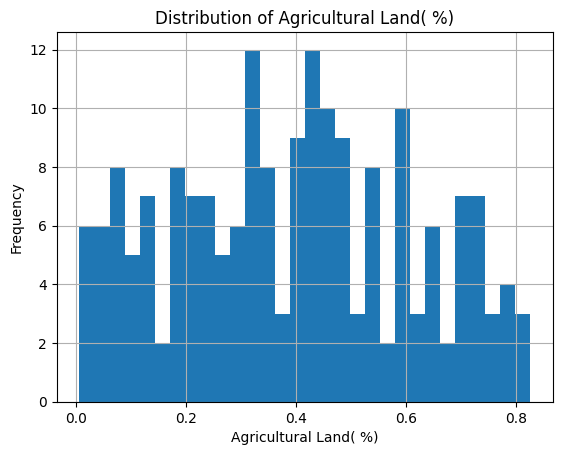

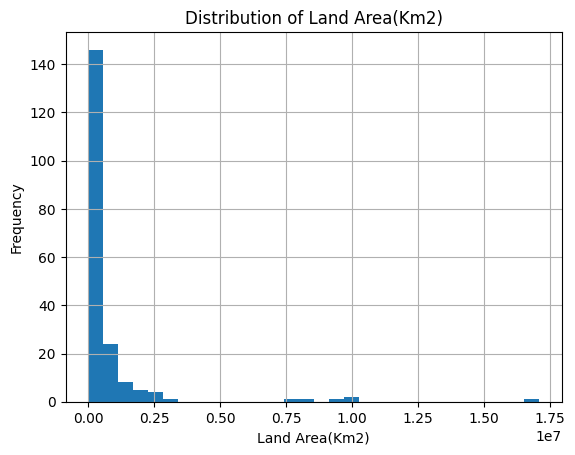

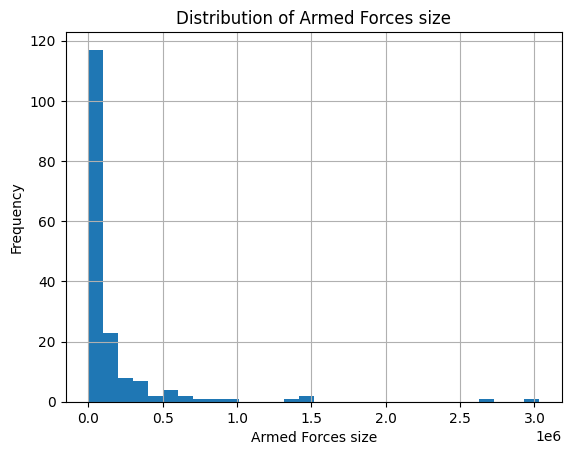

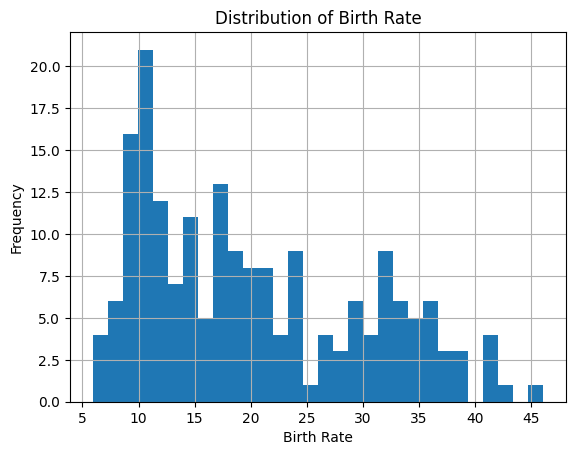

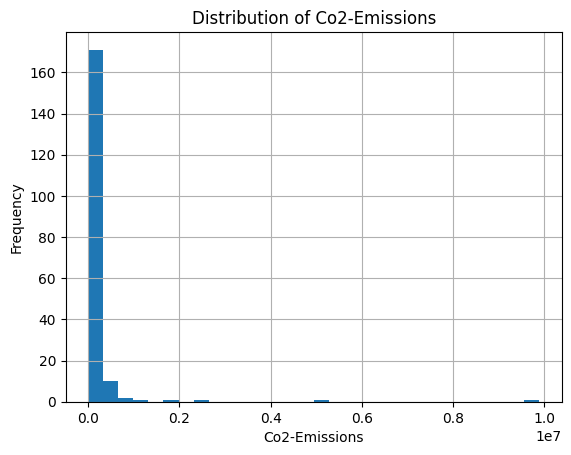

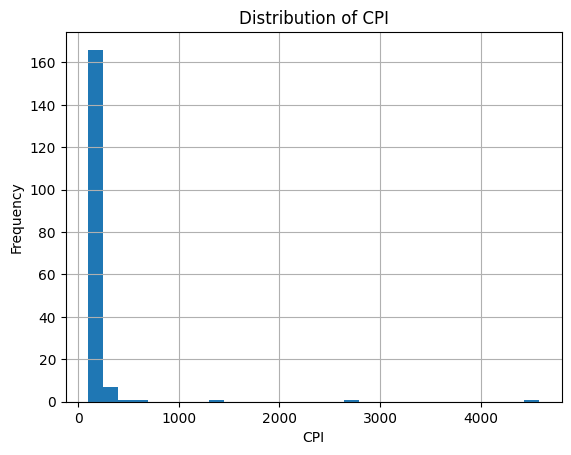

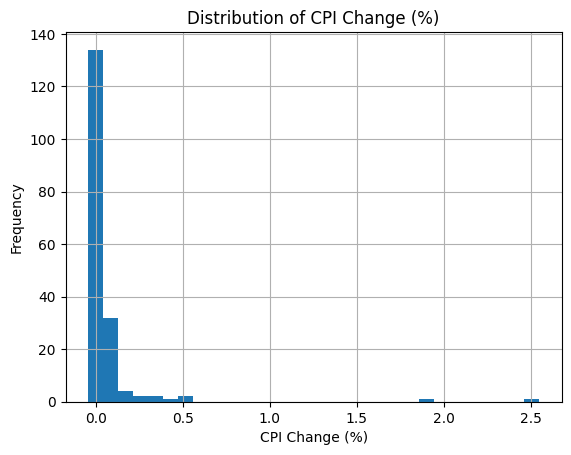

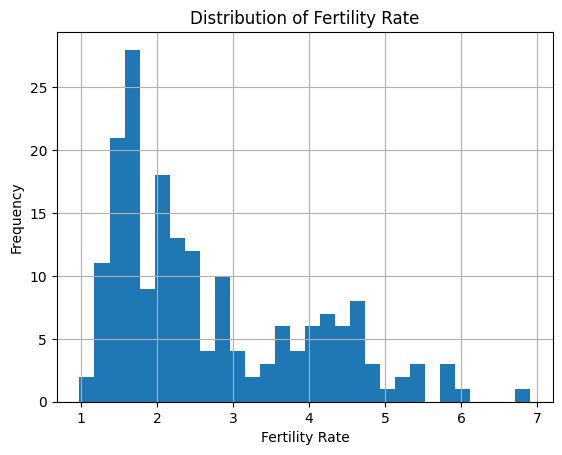

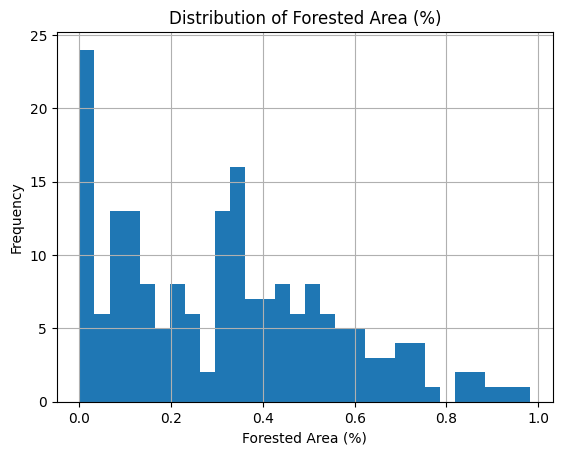

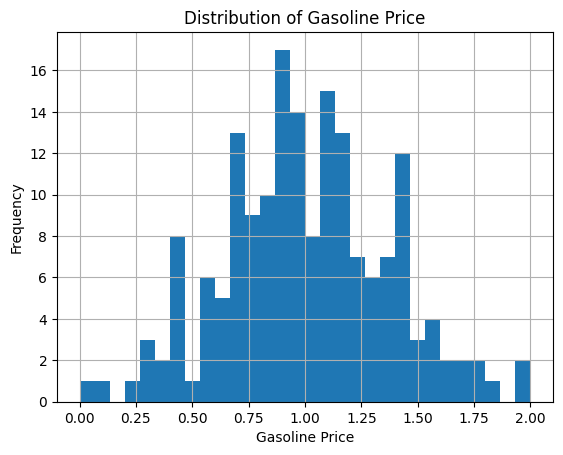

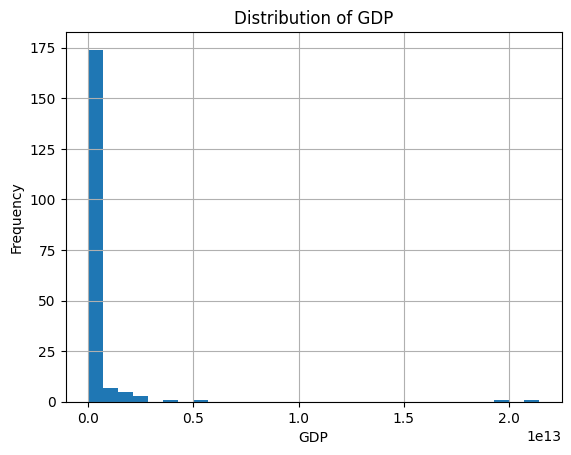

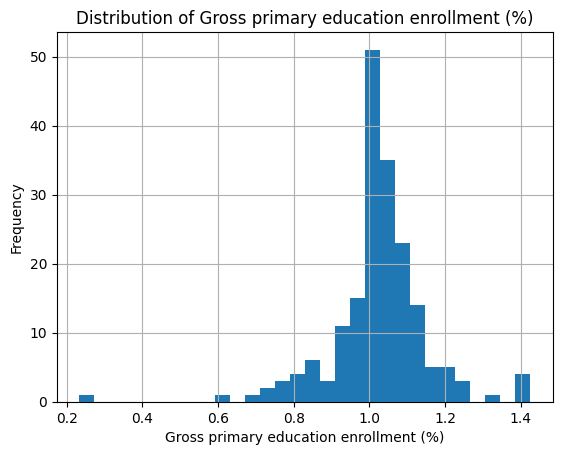

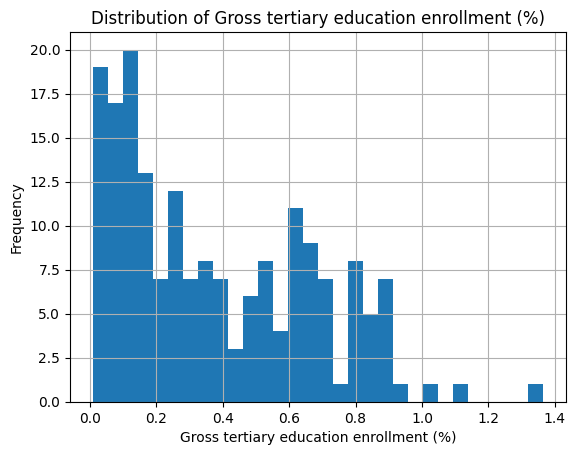

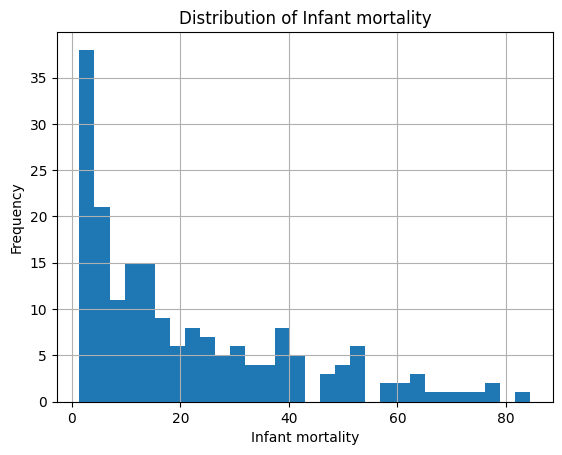

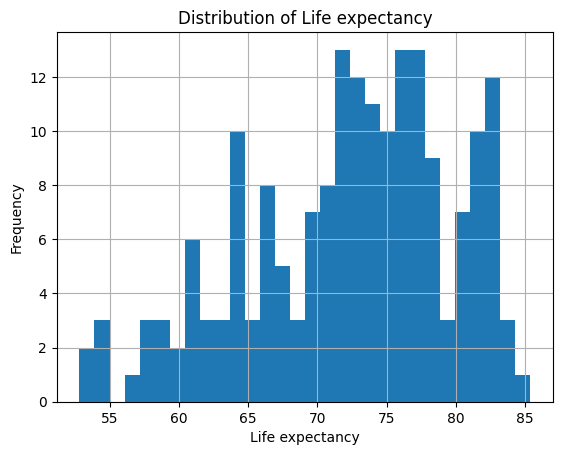

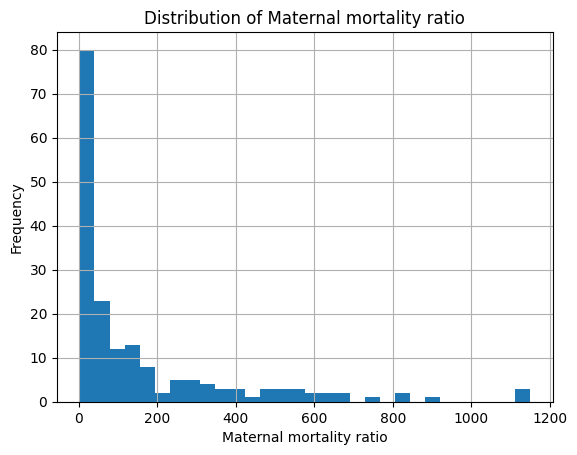

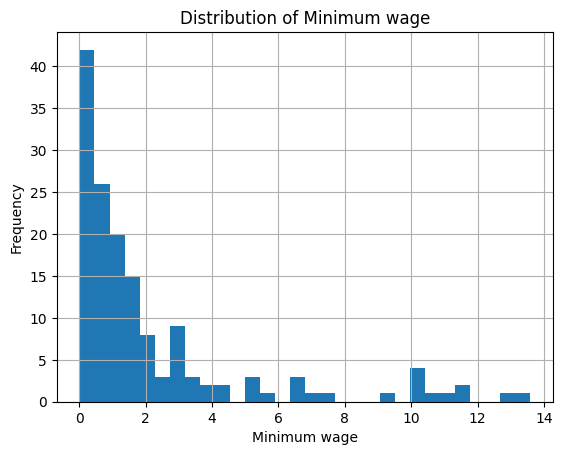

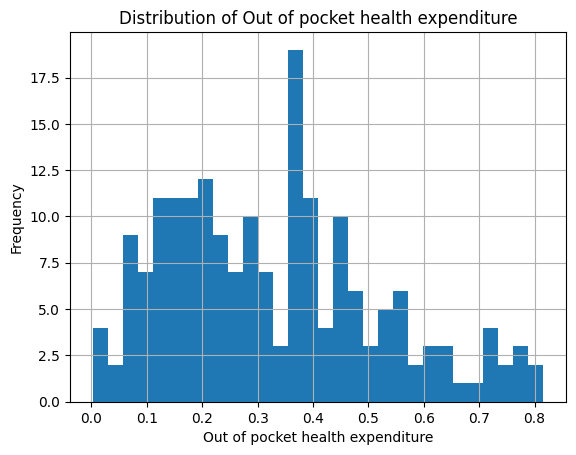

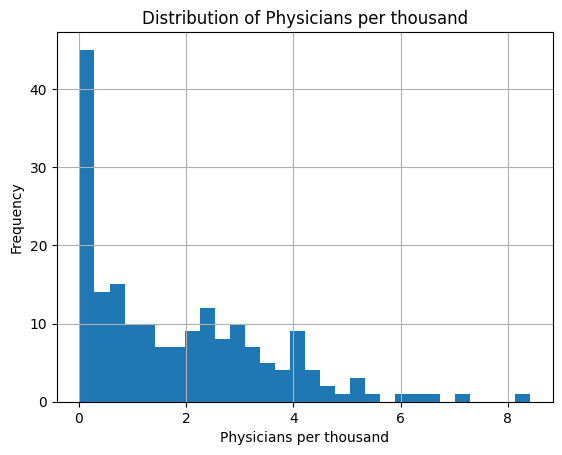

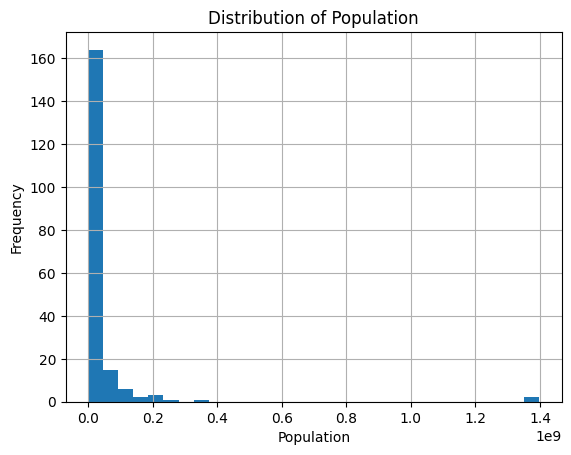

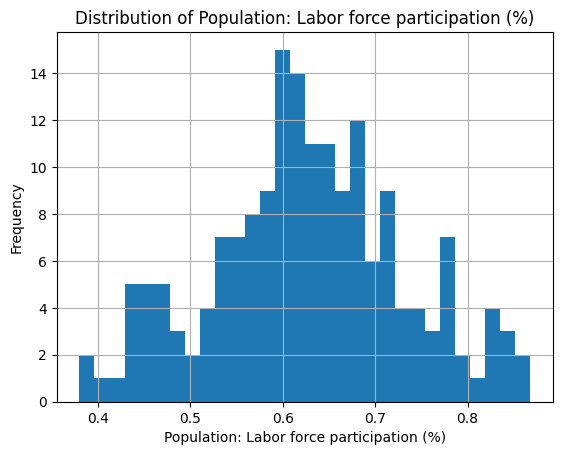

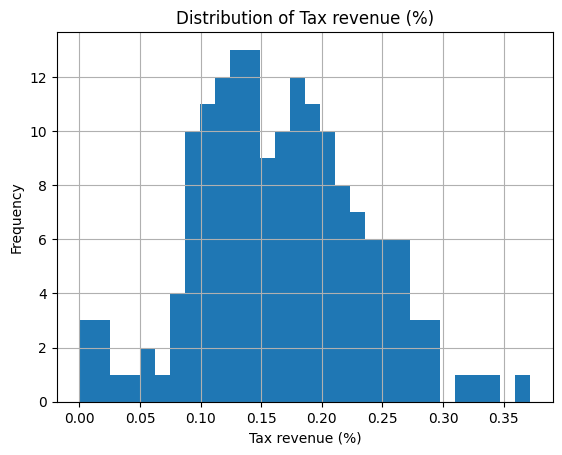

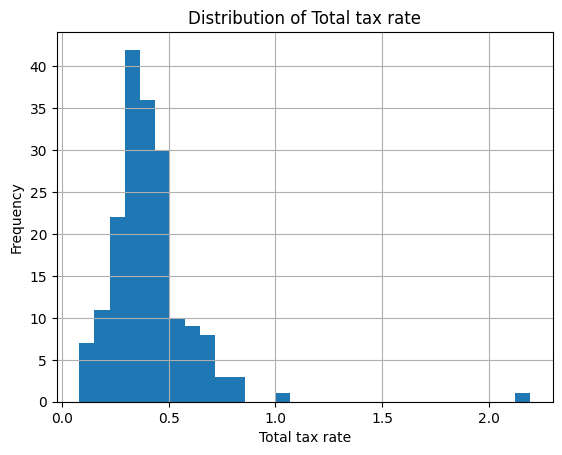

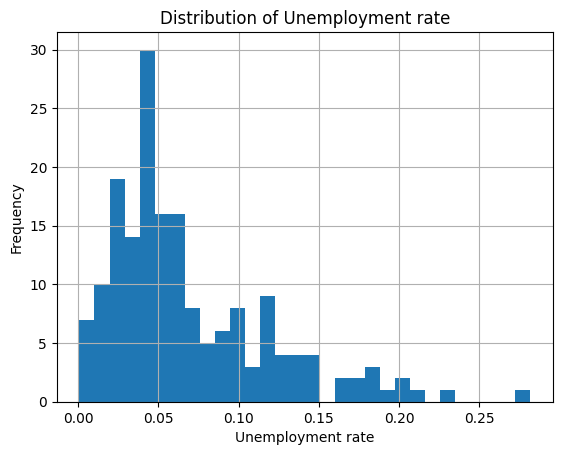

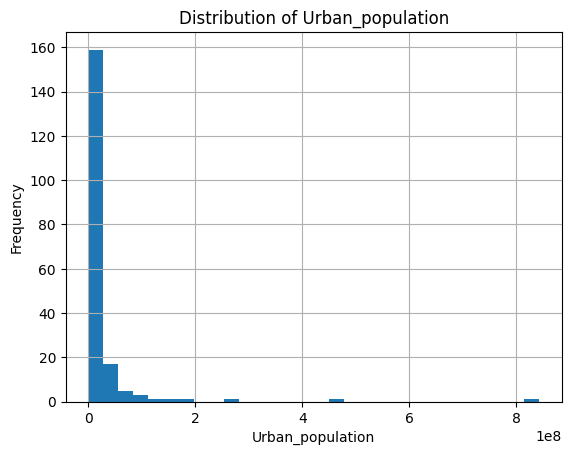

In [61]:
cols_with_nulls = dataset2.columns[dataset2.isnull().any()]

print("Columns with null values:", list(cols_with_nulls))

# 2. Mostrar distribución de cada columna
for col in cols_with_nulls:
    plt.figure()
    dataset2[col].dropna().hist(bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [62]:
cols_to_transform = [
    "Minimum wage",
    "Tax revenue (%)",
    "Armed Forces size",
    "Gasoline Price",
    "Population: Labor force participation (%)",
    "Unemployment rate",
    "CPI",
    "CPI Change (%)",
    "Maternal mortality ratio",
    "Gross tertiary education enrollment (%)",
    "Total tax rate",
    "Life expectancy",
    "Out of pocket health expenditure",
    "Physicians per thousand",
    "Gross primary education enrollment (%)",
    "Co2-Emissions",
    "Agricultural Land( %)",
    "Forested Area (%)",
    "Fertility Rate",
    "Birth Rate",
    "Infant mortality",
    "Urban_population",
    "GDP",
    "Land Area(Km2)",
    "Population"
]

In [63]:
def find_best_q(series, q_min=2, q_max=20, min_per_bin=15):
    s_valid = series.dropna()

    if len(s_valid) == 0:
        return None
    if s_valid.nunique() < 2:
        return 1

    best_q = None
    max_q_possible = min(q_max, len(s_valid))

    for q in range(q_min, max_q_possible + 1):
        try:
            bins = pd.qcut(s_valid, q=q, duplicates="drop")
            counts = bins.value_counts()
            real_q = len(counts)

            if real_q >= 2 and counts.min() >= min_per_bin:
                best_q = real_q
        except Exception:
            pass

    return best_q if best_q is not None else 1


for col in cols_to_transform:

    s = dataset2[col]
    temp_col = f"{col}__temp"

    # 0 para missing
    dataset2[temp_col] = 0

    mask = s.notna()
    best_q = find_best_q(s, q_min=2, q_max=20, min_per_bin=15)

    if best_q == 1:
        dataset2.loc[mask, temp_col] = 1
    else:
        dataset2.loc[mask, temp_col] = (
            pd.qcut(
                s[mask],
                q=best_q,
                labels=False,
                duplicates="drop"
            ) + 1
        ).astype(int)

    # Borrar original y dejar la nueva con el mismo nombre
    dataset2.drop(columns=[col], inplace=True)
    dataset2.rename(columns={temp_col: col}, inplace=True)

# NORMALIZACION

In [64]:
min_vals = dataset2.min()
max_vals = dataset2.max()

dataset2_minmax = (dataset2 - min_vals) / (max_vals - min_vals)

Step 4 - Data Preparation

In [65]:
def initialize_weights(
  map_size,
  num_features):

  # Random weight initialization
  weight_matrix = np.random.rand(map_size[0], map_size[1], num_features)

  # Output neuron grid indices
  weight_index = np.indices((map_size[0], map_size[1]))

  return weight_matrix, weight_index

Step 5 - BMU calculation


In [66]:
def calculate_bmu(
    input_pattern,
    weight_matrix,
    map_size):
    """
    Finds the BMU (Best Matching Unit) for an input pattern on a Kohonen map.

    Parameters:
    input_pattern (numpy array): Input pattern to be compared with the weight vectors.
    weight_matrix (numpy array): Matrix of weight vectors representing the Kohonen map.
    map_size (tuple): Size of the Kohonen map (width, height).

    Returns:
    tuple: A tuple containing the BMU (Best Matching Unit) weight vector and its coordinates.
    """

    # Calculate Euclidean distances between input pattern and all weight vectors
    distances = np.sqrt(((weight_matrix - input_pattern) ** 2).sum(axis=2))

    # Find index of the neuron with the smallest distance (BMU)
    bmu_flat_idx = np.argmin(distances)
    bmu_idx = np.unravel_index(bmu_flat_idx, (map_size[0], map_size[1]))

    # Retrieve the BMU weight vector
    bmu = weight_matrix[bmu_idx]

    return (bmu, bmu_idx)

Step 6 - Learning rate decay

In [67]:
# Function to calculate the descent of the learning coefficient (alpha)

def learning_rate_variation(
    lr,
    i,
    epochs):
    """
    Calculate the learning rate (alpha) for the i-th iteration.

    Parameters:
    lr (float): Initial learning rate.
    i (int): Current iteration.
    epochs (int): Total number of iterations.

    Returns:
    float: Learning rate for the i-th iteration.
    """

    # Calculate the learning rate for the i-th iteration

    return lr * np.exp(-i / epochs)

Step 7 - Neighborhood calculation

In [68]:
# Función para calcular el descenso del vecindario (v)

def neighborhood_variation(
    neighborhood,
    i,
    epochs):
    """
    Calculate the neighborhood (v) for the i-th iteration.

    Parameters:
    neighborhood (float): Initial neighborhood value.
    i (int): Current iteration.
    epochs (int): Total number of iterations.

    Returns:
    float: Neighborhood value for the i-th iteration.
    """

    # Calculate the neighborhood for the i-th iteration

    return (neighborhood * np.exp(-i / epochs)) + 1

Step 8 - BMU influence based on the neighborhood

In [69]:
def calculate_bmu_influence(
    distance_to_bmu,
    current_neighborhood):
    """
    Calculate the distribution of the learning rate based on the distance in the map between a neuron and the BMU.

    Parameters:
    distance_to_bmu (float): Distance between a neuron and the BMU.
    current_neighborhood (float): Current neighborhood value.

    Returns:
    float: Damping factor for the iteration (Radius).
    """
    return np.exp(-distance_to_bmu ** 2 / (2 * (current_neighborhood ** 2)))

Step 9 - Print map

In [70]:
def paint_map(
    value_matrix,
    epochs,
    map_size):
    """
    Function to visualize a matrix of values as RGB colors.

    Parameters:
    value_matrix (numpy array): Matrix of RGB values to be visualized.
    epochs (int): Number of epochs (iterations) completed.

    Returns:
    None
    """

    fig = plt.figure()

    # Set axes
    ax = fig.add_subplot(111, aspect='equal')
    ax.set_xlim((0, value_matrix.shape[0]+1))
    ax.set_ylim((0, value_matrix.shape[1]+1))
    ax.set_title('Self-Organizing Map after %d iterations' % epochs)

    for x in range(1, map_size[0] + 1):
      for y in range(1, map_size[1] + 1):
        ax.add_patch(
            patches.Rectangle((x-0.5, y-0.5), 1, 1,
            facecolor = value_matrix[x-1,y-1,:],
            edgecolor = 'none'))

    plt.show()

Step 9 - Training algorithm

In [71]:
def train(
    training_data,
    weight_matrix,
    output_index,
    lr,
    neighborhood,
    map_size,
    epochs,
    print = False):

    #paint_map(weight_matrix, 1)

    # Training loop
    for epoch in range(1, epochs + 1):

        # Select a random pattern from the dataset and reshape
        # it (this is very important) to match the format of the weight matrix.
        input_sample = training_data[np.random.randint(0, len(training_data))]

        # Calculate/Update the parameters corresponding
        # to this iteration (a -> Learning rate and v --> neighboordhood).
        learning_rate = learning_rate_variation(lr, epoch, epochs)
        neighborhood = neighborhood_variation(neighborhood, epoch, epochs)

        # Find the Best Matching Unit (BMU) for the input pattern
        bmu, bmu_idx = calculate_bmu(
            input_sample,
            weight_matrix,
            map_size)

        x, y = output_index

        # Calculate the 2-D Euclidean distance of each neuron with respect to the BMU.
        distance_to_bmu = np.sqrt((x - bmu_idx[0]) ** 2 + (y - bmu_idx[1]) ** 2)

        # Compute the influence (damping) of the bmu neuron to others.
        bmu_influence = calculate_bmu_influence(distance_to_bmu, neighborhood)

        # Update the weight vector.
        weight_matrix += learning_rate * bmu_influence[..., np.newaxis] * (input_sample - weight_matrix)

        if print:
          if epoch % 500 == 0:
            paint_map(weight_matrix, epoch, map_size)

    return weight_matrix

Step 10 - Evaluation metrics

In [72]:
def quantization_error(model, input_data, map_size):
    """
    Computes the Quantization Error (QE) of a SOM.
    QE = average Euclidean distance between each input vector
    and the weight vector of its Best Matching Unit (BMU).
    """
    errors = []

    for x in input_data:
        bmu_w, _ = calculate_bmu(x, model, map_size)
        errors.append(np.linalg.norm(x - bmu_w))

    return np.mean(errors)

def calculate_first_second_bmu(
    model,
    input_vector):
    """
    Calculate the quantization error for a given model and dataset.

    The quantization error measures the average Euclidean distance between each
    input data point and its Best Matching Unit (BMU). It serves as a metric
    for how well the SOM grid represents the input space.

    Parameters:
    - model (np.ndarray): The trained SOM weight matrix or model used for BMU identification.
    - input_data (array-like): The dataset (e.g., list or NumPy array) containing
      the input patterns to be evaluated.

    Returns:
    - float: The Mean Quantization Error (MQE) across all data points in the input set.
    """

    distances = np.linalg.norm(model - input_vector, axis=1)

    first_bmu_index = np.argmin(distances)
    bmu_idx = np.unravel_index(first_bmu_index, distances.shape)
    first_bmu_distance = distances[bmu_idx]
    first_bmu_weights = model[bmu_idx]

    distances[bmu_idx] = np.inf

    second_bmu_index = np.argmin(distances)
    bmu_idx2 = np.unravel_index(second_bmu_index, distances.shape)
    second_bmu_distance = distances[bmu_idx2]
    second_bmu_weights = model[bmu_idx2]

    return first_bmu_index, first_bmu_distance, first_bmu_weights, second_bmu_index, second_bmu_distance, second_bmu_weights


def topographic_error(
    model,
    input_data,
    threshold = 1.001):

    """
    Compute the topographic error for a given input and weight matrix.

    Parameters:
    - input_matrix (numpy.ndarray): The dataset where each row is an input vector.
    - weight_matrix (numpy.ndarray): The weight matrix representing the model.
    - threshold (float): Distance threshold to determine topographic error (default: 0.2).

    Returns:
    - float: The topographic error, i.e., the fraction of input vectors for which
      the first and second best-matching units (BMUs) are not adjacent.
    """

    grid_shape = model.shape[:2]

    count = sum(
        max(abs(np.unravel_index(idx1, grid_shape)[0] - np.unravel_index(idx2, grid_shape)[0]),
            abs(np.unravel_index(idx1, grid_shape)[1] - np.unravel_index(idx2, grid_shape)[1])) > 1
        for input_vector in input_data
        for idx1, _, _, idx2, _, _ in [calculate_first_second_bmu(model, input_vector)]
    )

    return count / len(input_data)

In [73]:
def train_all_soms(configs, dataset):
    """
    Trains one SOM per configuration and evaluates each model
    using Quantization Error (QE) and Topographic Error (TE).
    Returns a DataFrame with the results and a dictionary
    with the trained SOM models including metadata.
    """
    results = []
    models = {}

    input_data = dataset.values

    for cfg in configs:
        size = cfg["size"]
        lr = cfg["lr"]
        epochs = cfg["epochs"]
        neighborhood = cfg.get("neighborhood", max(size) / 2)
        topology = cfg.get("topology", "unknown")
        model_name = cfg.get("name", f"{size[0]}x{size[1]}")

        print(f"Training {model_name} — SOM {size[0]}x{size[1]} | lr={lr} | epochs={epochs} | neighborhood={neighborhood}")

        # Initialize SOM
        som, output_idx = initialize_weights(size, input_data.shape[1])

        # Train SOM
        model = train(
            input_data,
            som,
            output_idx,
            lr=lr,
            neighborhood=neighborhood,
            map_size=size,
            epochs=epochs
        )

        # Quantization Error
        qe = quantization_error(model, input_data, size)

        # Topographic Error
        te_count = 0
        for x in input_data:
            dists = np.sqrt(((model - x) ** 2).sum(axis=2))
            flat_sorted = np.argsort(dists.flatten())
            bmu1 = np.unravel_index(flat_sorted[0], size)
            bmu2 = np.unravel_index(flat_sorted[1], size)
            if abs(bmu1[0] - bmu2[0]) > 1 or abs(bmu1[1] - bmu2[1]) > 1:
                te_count += 1
        te = te_count / len(input_data)

        results.append({
            "name": model_name,
            "topology": topology,
            "map_size": f"{size[0]}x{size[1]}",
            "learning_rate": lr,
            "epochs": epochs,
            "neighborhood": neighborhood,
            "quantization_error": qe,
            "topographic_error": te
        })

        models[model_name] = {
            "weight_matrix": model,
            "size": size,
            "lr": lr,
            "epochs": epochs,
            "qe": qe,
            "te": te
        }

    return pd.DataFrame(results), models

# ENTRENAR MODELOS

In [74]:
configs = [
    {"name": "Model 1", "size": [14,14], "lr": 0.1, "epochs": 200000, "topology": "square",      "neighborhood": 7},
    {"name": "Model 2", "size": [17,17], "lr": 0.1, "epochs": 200000, "topology": "square",      "neighborhood": 9},
    {"name": "Model 3", "size": [20,20], "lr": 0.1, "epochs": 200000, "topology": "square",      "neighborhood": 10},

    {"name": "Model 4", "size": [20,10], "lr": 0.1, "epochs": 200000, "topology": "rectangular", "neighborhood": 10},
    {"name": "Model 5", "size": [24,10], "lr": 0.1, "epochs": 200000, "topology": "rectangular", "neighborhood": 12},
    {"name": "Model 6", "size": [28,14], "lr": 0.1, "epochs": 200000, "topology": "rectangular", "neighborhood": 14},
    {"name": "Model 7", "size": [40,10], "lr": 0.1, "epochs": 200000, "topology": "rectangular", "neighborhood": 20},
]

configs2 = [
    {"name": "Model 1", "size": [14,14], "lr": 0.1,  "epochs": 200000, "topology": "square",      "neighborhood": 7},
    {"name": "Model 2", "size": [17,17], "lr": 0.1,  "epochs": 200000, "topology": "square",      "neighborhood": 8},
    {"name": "Model 3", "size": [20,20], "lr": 0.1,  "epochs": 200000, "topology": "square",      "neighborhood": 10},

    {"name": "Model 4", "size": [20,10], "lr": 0.1,  "epochs": 200000, "topology": "rectangular", "neighborhood": 10},
    {"name": "Model 5", "size": [24,10], "lr": 0.1,  "epochs": 200000, "topology": "rectangular", "neighborhood": 12},
    {"name": "Model 6", "size": [28,14], "lr": 0.1,  "epochs": 200000, "topology": "rectangular", "neighborhood": 14},
    {"name": "Model 7", "size": [40,10], "lr": 0.1,  "epochs": 200000, "topology": "rectangular", "neighborhood": 20},

    {"name": "Model 8", "size": [20,20], "lr": 0.05, "epochs": 600000, "topology": "square",      "neighborhood": 10},
    {"name": "Model 9", "size": [40,10], "lr": 0.05, "epochs": 600000, "topology": "rectangular", "neighborhood": 20},
]

maps_config, trained_maps = train_all_soms(configs, dataset_minmax)
maps_config2, trained_maps2 = train_all_soms(configs2, dataset2_minmax)


Training Model 1 — SOM 14x14 | lr=0.1 | epochs=200000 | neighborhood=7
Training Model 2 — SOM 17x17 | lr=0.1 | epochs=200000 | neighborhood=9
Training Model 3 — SOM 20x20 | lr=0.1 | epochs=200000 | neighborhood=10
Training Model 4 — SOM 20x10 | lr=0.1 | epochs=200000 | neighborhood=10
Training Model 5 — SOM 24x10 | lr=0.1 | epochs=200000 | neighborhood=12
Training Model 6 — SOM 28x14 | lr=0.1 | epochs=200000 | neighborhood=14
Training Model 7 — SOM 40x10 | lr=0.1 | epochs=200000 | neighborhood=20
Training Model 1 — SOM 14x14 | lr=0.1 | epochs=200000 | neighborhood=7
Training Model 2 — SOM 17x17 | lr=0.1 | epochs=200000 | neighborhood=8
Training Model 3 — SOM 20x20 | lr=0.1 | epochs=200000 | neighborhood=10
Training Model 4 — SOM 20x10 | lr=0.1 | epochs=200000 | neighborhood=10
Training Model 5 — SOM 24x10 | lr=0.1 | epochs=200000 | neighborhood=12
Training Model 6 — SOM 28x14 | lr=0.1 | epochs=200000 | neighborhood=14
Training Model 7 — SOM 40x10 | lr=0.1 | epochs=200000 | neighborhood

# COMPARAR MODELOS

In [75]:
def compare_models(trained_maps):
    results = []
    for name, v in trained_maps.items():
        topology = "square" if v['size'][0] == v['size'][1] else "rectangular"
        results.append({
            "Model": name,
            "Size": f"{v['size'][0]}x{v['size'][1]}",
            "Topology": topology,
            "LR": v['lr'],
            "Epochs": v['epochs'],
            "QE": round(v['qe'], 4),
            "TE": round(v['te'], 4)
        })

    results_df = pd.DataFrame(results).sort_values("QE")
    print(results_df.to_string(index=False))

    best_square_name  = results_df[results_df['Topology'] == 'square'].iloc[0]['Model']
    best_rect_name    = results_df[results_df['Topology'] == 'rectangular'].iloc[0]['Model']
    best_overall_name = results_df.iloc[0]['Model']

    print(f"\nBest square model:      {best_square_name}  ({results_df[results_df['Model']==best_square_name].iloc[0]['Size']})")
    print(f"Best rectangular model: {best_rect_name}  ({results_df[results_df['Model']==best_rect_name].iloc[0]['Size']})")
    print(f"Best overall model:     {best_overall_name}  ({results_df[results_df['Model']==best_overall_name].iloc[0]['Size']})")

    return results_df, best_square_name, best_rect_name, best_overall_name

In [76]:
def build_classification_map(dataset_minmax, best_model, best_size):
    country_names = dataset_minmax.index.tolist()
    data = dataset_minmax.values

    neuron_countries = {}
    country_bmu = {}

    for i, country in enumerate(country_names):
        _, bmu_idx = calculate_bmu(data[i], best_model, best_size)
        key = (bmu_idx[0], bmu_idx[1])
        neuron_countries.setdefault(key, []).append(country)
        country_bmu[country] = key

    print(f"Classification Map ({best_size[0]}x{best_size[1]}):")
    print(f"Active neurons: {len(neuron_countries)} / {best_size[0]*best_size[1]}")
    print()
    for (x, y), countries in sorted(neuron_countries.items()):
        print(f"  Neuron ({x:2d},{y:2d}): {', '.join(countries)}")

    return neuron_countries, country_bmu

In [77]:
# U-Matrix computation
def compute_umatrix(weights, map_size):
    umatrix = np.zeros((map_size[0], map_size[1]))
    for i in range(map_size[0]):
        for j in range(map_size[1]):
            neighbors = []
            for di in [-1, 0, 1]:
                for dj in [-1, 0, 1]:
                    if di == 0 and dj == 0:
                        continue
                    ni, nj = i + di, j + dj
                    if 0 <= ni < map_size[0] and 0 <= nj < map_size[1]:
                        neighbors.append(np.linalg.norm(weights[i,j] - weights[ni,nj]))
            umatrix[i,j] = np.mean(neighbors)
    return umatrix

In [78]:
def som_kmeans_clustering(best_model, best_size, country_bmu, umatrix, k_optimal=5, dataset_label=""):
    from sklearn.cluster import KMeans

    weights_2d = best_model.reshape(-1, best_model.shape[2])

    inertias = []
    K_range = range(2, 25)
    for k in K_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        km.fit(weights_2d)
        inertias.append(km.inertia_)

    K_arr      = np.array(list(K_range))
    iner_arr   = np.array(inertias)
    x_norm     = (K_arr   - K_arr.min())   / (K_arr.max()   - K_arr.min())
    y_norm     = (iner_arr - iner_arr.min()) / (iner_arr.max() - iner_arr.min())
    x1, y1, x2, y2 = x_norm[0], y_norm[0], x_norm[-1], y_norm[-1]
    distances  = np.abs((y2-y1)*x_norm - (x2-x1)*y_norm + x2*y1 - y2*x1) \
                 / np.sqrt((y2-y1)**2 + (x2-x1)**2)
    k_needle   = int(K_arr[np.argmax(distances)])

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(K_range, inertias, 'bo-')
    ax.axvline(x=k_needle, color='red', linestyle='--', label=f'Kneedle K={k_needle}')
    ax.set_xlabel('Number of Clusters (K)')
    ax.set_ylabel('Inertia')
    ax.set_title(f'Elbow Method for Optimal K {dataset_label}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    k_optimal = k_needle
    print(f"Selected K = {k_optimal}")

    km_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
    neuron_labels = km_final.fit_predict(weights_2d).reshape(best_size[0], best_size[1])

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    ax1 = axes[0]
    im1 = ax1.imshow(neuron_labels.T, cmap='tab10', origin='lower', aspect='auto')
    ax1.set_title(f'SOM Cluster Map (K={k_optimal}) {dataset_label}')
    plt.colorbar(im1, ax=ax1, label='Cluster ID')
    for country, (bx, by) in country_bmu.items():
        ax1.text(bx, by, country[:3], ha='center', va='center', fontsize=4, alpha=0.7)

    ax2 = axes[1]
    im2 = ax2.imshow(umatrix.T, cmap='bone_r', origin='lower', aspect='auto')
    ax2.set_title(f'U-Matrix with Cluster Boundaries {dataset_label}')
    plt.colorbar(im2, ax=ax2, label='Distance')
    for i in range(best_size[0]):
        for j in range(best_size[1]):
            for di, dj in [(1,0), (0,1)]:
                ni, nj = i+di, j+dj
                if 0 <= ni < best_size[0] and 0 <= nj < best_size[1]:
                    if neuron_labels[i,j] != neuron_labels[ni,nj]:
                        if di == 1:
                            ax2.plot([i+0.5, i+0.5], [j-0.5, j+0.5], 'r-', linewidth=1.5)
                        else:
                            ax2.plot([i-0.5, i+0.5], [j+0.5, j+0.5], 'r-', linewidth=1.5)

    plt.tight_layout()
    plt.show()

    country_clusters = {}
    for country, (bx, by) in country_bmu.items():
        country_clusters[country] = int(neuron_labels[bx, by])
    print(f"\n{'='*60}")
    print(f"Number of groups: {k_optimal}")
    print(f"{'='*60}")
    for cluster_id in range(k_optimal):
        members = [c for c, cl in country_clusters.items() if cl == cluster_id]
        print(f"\nCluster {cluster_id} ({len(members)} countries):")
        print(f"  {', '.join(sorted(members))}")

    return country_clusters, neuron_labels, k_optimal

In [79]:
def plot_cluster_map(country_clusters, k_optimal, dataset_label=""):
    """
    Dibuja un mapa choropleth con los clusters SOM por país.

    Parámetros
    ----------
    country_clusters : dict  — {country: cluster_id}
    k_optimal        : int   — número de clusters (para ordenar la leyenda)
    dataset_label    : str   — etiqueta para el título (ej. "Dataset 1")
    """
    title = f"SOM Country Clusters - World Map"
    if dataset_label:
        title += f" — {dataset_label}"


    CUSTOM_COLORS = [
        "#1B9E77",
        "#D95F02",
        "#7570B3",
        "#E7298A",
        "#66A61E",
        "#E6AB02",
        "#A6761D",
        "#1F78B4",
        "#B2182B",
        "#4DAC26",
        "#8B4513",
        "#2C7BB6",
        "#762A83",
        "#F46D43",
    ]

    map_data = pd.DataFrame({
        'Country': list(country_clusters.keys()),
        'Cluster': list(country_clusters.values())
    })
    map_data['Cluster'] = map_data['Cluster'].astype(str)

    fig = px.choropleth(
        map_data,
        locations='Country',
        locationmode='country names',
        color='Cluster',
        title=title,
        color_discrete_sequence=CUSTOM_COLORS,
        category_orders={'Cluster': [str(i) for i in range(k_optimal)]}
    )
    fig.update_layout(
        geo=dict(
            showframe=False,
            showcoastlines=True,
            coastlinecolor='#AAAAAA',
            projection_type='natural earth',
            bgcolor='white',
            showocean=True,
            oceancolor='#D6EAF8',
            lakecolor='#D6EAF8',
            showland=True,
            landcolor='#F5F5F5',
            showcountries=True,
            countrycolor='#CCCCCC',
        ),
        paper_bgcolor='white',
        plot_bgcolor='white',
        font=dict(color='#222222'),
        width=1100,
        height=600
    )
    fig.show()

Comparación de modelos para dataset

In [80]:
results_df, best_square_name, best_rect_name, best_overall_name = compare_models(trained_maps)

best_model = trained_maps[best_overall_name]["weight_matrix"]
best_size  = trained_maps[best_overall_name]["size"]

  Model  Size    Topology  LR  Epochs     QE     TE
Model 7 40x10 rectangular 0.1  200000 0.5091 0.0000
Model 3 20x20      square 0.1  200000 0.5124 0.0000
Model 6 28x14 rectangular 0.1  200000 0.5165 0.0000
Model 2 17x17      square 0.1  200000 0.5626 0.0000
Model 5 24x10 rectangular 0.1  200000 0.5863 0.0051
Model 4 20x10 rectangular 0.1  200000 0.6099 0.0051
Model 1 14x14      square 0.1  200000 0.6116 0.0000

Best square model:      Model 3  (20x20)
Best rectangular model: Model 7  (40x10)
Best overall model:     Model 7  (40x10)


In [81]:
neuron_countries, country_bmu = build_classification_map(dataset_minmax, best_model, best_size)

Classification Map (40x10):
Active neurons: 140 / 400

  Neuron ( 0, 0): Fiji, Marshall Islands, Papua New Guinea, East Timor
  Neuron ( 0, 2): Bhutan
  Neuron ( 0, 3): Laos
  Neuron ( 0, 4): Nepal
  Neuron ( 0, 5): Indonesia
  Neuron ( 0, 7): India
  Neuron ( 0, 9): China, United States
  Neuron ( 1, 3): Vietnam
  Neuron ( 1, 5): Myanmar
  Neuron ( 1, 9): Russia
  Neuron ( 2, 2): Malaysia, Thailand
  Neuron ( 3, 0): Samoa
  Neuron ( 3, 2): Sri Lanka
  Neuron ( 3, 6): Afghanistan, Pakistan
  Neuron ( 3, 9): Iran
  Neuron ( 4, 0): Cape Verde, Jamaica
  Neuron ( 4, 2): Mexico
  Neuron ( 4, 4): Bangladesh
  Neuron ( 4, 5): Turkmenistan
  Neuron ( 4, 7): Tajikistan
  Neuron ( 4, 8): Iraq
  Neuron ( 4, 9): Jordan, Libya
  Neuron ( 5, 4): Azerbaijan, Uzbekistan
  Neuron ( 5, 6): Kyrgyzstan
  Neuron ( 5, 9): Algeria
  Neuron ( 6, 0): Bosnia and Herzegovina, Turkey
  Neuron ( 6, 9): Tunisia
  Neuron ( 7, 0): Montenegro
  Neuron ( 7, 1): Albania
  Neuron ( 7, 3): Armenia
  Neuron ( 7, 5): Kazak

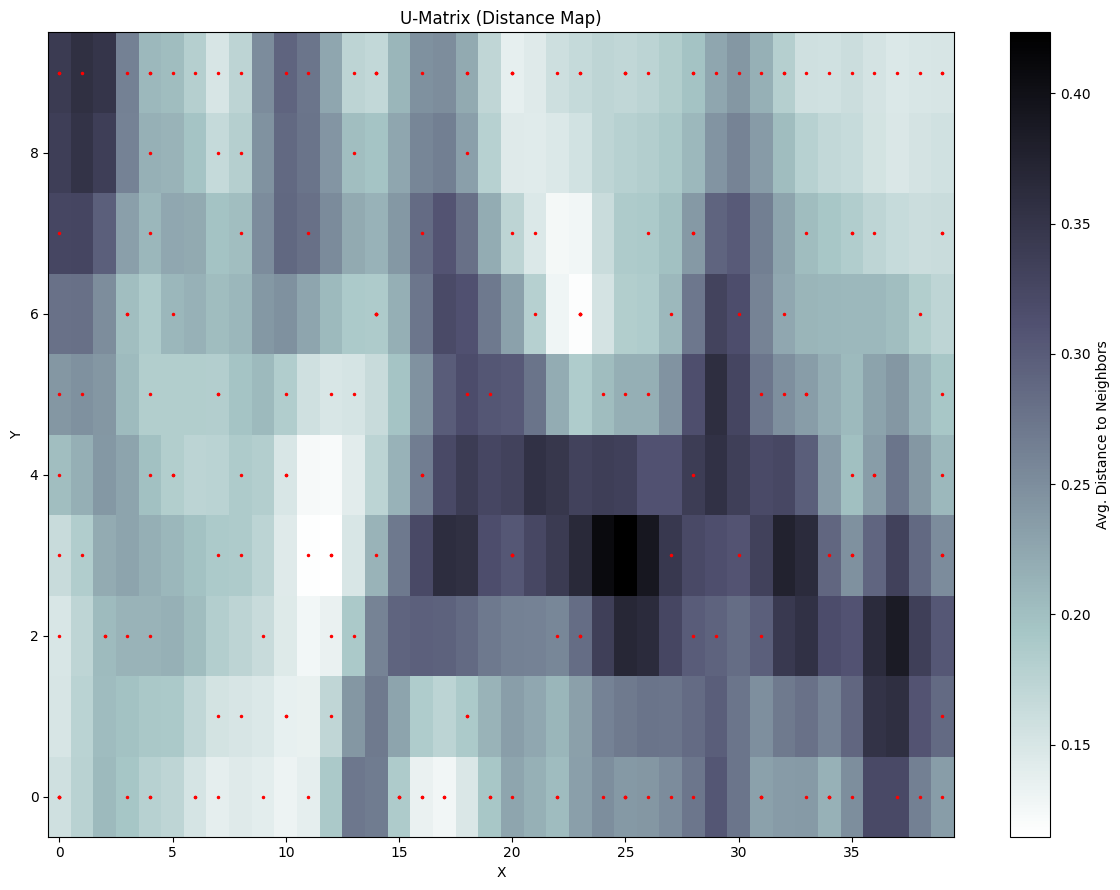

In [82]:
umatrix = compute_umatrix(best_model, best_size)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(umatrix.T, cmap='bone_r', origin='lower', aspect='auto')
ax.set_title('U-Matrix (Distance Map)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.colorbar(im, ax=ax, label='Avg. Distance to Neighbors')

for country, (bx, by) in country_bmu.items():
    ax.plot(bx, by, 'r.', markersize=3)

plt.tight_layout()
plt.show()

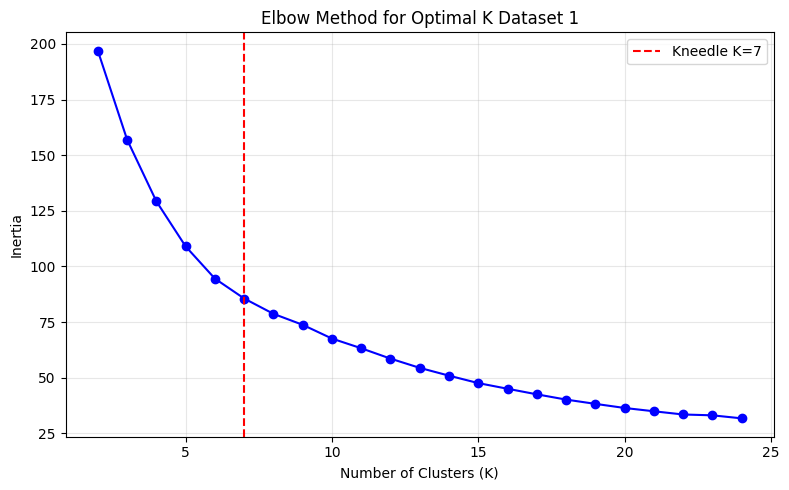

Selected K = 7


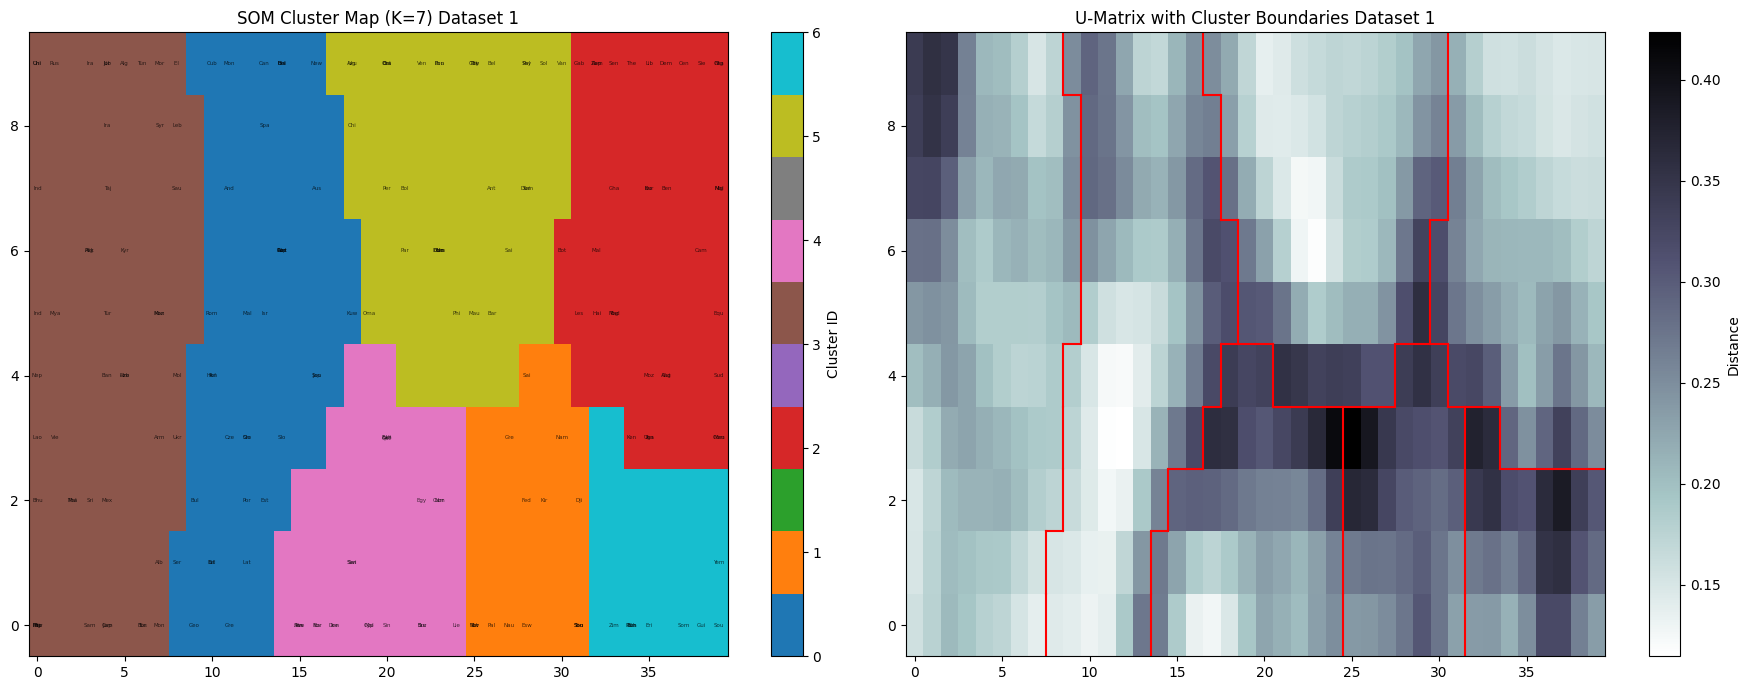


Number of groups: 7

Cluster 0 (35 countries):
  Andorra, Australia, Belarus, Belgium, Bulgaria, Canada, Croatia, Cuba, Czech Republic, Estonia, France, Georgia, Germany, Greece, Hungary, Israel, Japan, Kuwait, Latvia, Lithuania, Luxembourg, Malta, Monaco, Netherlands, New Zealand, Poland, Portugal, Republic of Ireland, Romania, Serbia, Slovakia, Slovenia, South Korea, Spain, United Kingdom

Cluster 1 (15 countries):
  Djibouti, Eswatini, Federated States of Micronesia, Grenada, Kiribati, Namibia, Nauru, North Macedonia, Palestinian National Authority, Saint Lucia, Sao Tome & Principe, South Africa, Tonga, Tuvalu, Vatican City

Cluster 2 (34 countries):
  Angola, Benin, Botswana, Burkina Faso, Cameroon, Central African Republic, Chad, Comoros, Democratic Republic of the Congo, Equatorial Guinea, Gabon, Ghana, Guinea-Bissau, Haiti, Ivory Coast, Kenya, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Mozambique, Niger, Nigeria, Republic of the Congo, Senegal, Sierra Leone, Sudan,

In [83]:
country_clusters1, km1, neuron_labels1 = som_kmeans_clustering(
    best_model, best_size, country_bmu, umatrix,
    k_optimal=5, dataset_label="Dataset 1"
)

In [84]:
import plotly.express as px
plot_cluster_map(country_clusters1, k_optimal=5, dataset_label="Dataset 1")

Comparación de modelos para dataset

In [85]:
results_df2, best_square_name2, best_rect_name2, best_overall_name2 = compare_models(trained_maps2)

best_model2 = trained_maps2[best_overall_name2]["weight_matrix"]
best_size2  = trained_maps2[best_overall_name2]["size"]

  Model  Size    Topology   LR  Epochs     QE  TE
Model 7 40x10 rectangular 0.10  200000 0.7150 0.0
Model 9 40x10 rectangular 0.05  600000 0.7177 0.0
Model 8 20x20      square 0.05  600000 0.7236 0.0
Model 3 20x20      square 0.10  200000 0.7250 0.0
Model 6 28x14 rectangular 0.10  200000 0.7315 0.0
Model 2 17x17      square 0.10  200000 0.7896 0.0
Model 5 24x10 rectangular 0.10  200000 0.8169 0.0
Model 4 20x10 rectangular 0.10  200000 0.8437 0.0
Model 1 14x14      square 0.10  200000 0.8490 0.0

Best square model:      Model 8  (20x20)
Best rectangular model: Model 7  (40x10)
Best overall model:     Model 7  (40x10)


In [86]:
neuron_countries2, country_bmu2 = build_classification_map(dataset2_minmax, best_model2, best_size2)

Classification Map (40x10):
Active neurons: 150 / 400

  Neuron ( 0, 0): Chad, Eritrea, Mali, Niger
  Neuron ( 0, 3): Comoros
  Neuron ( 0, 4): Equatorial Guinea
  Neuron ( 0, 5): Guyana
  Neuron ( 0, 6): Gabon
  Neuron ( 0, 7): Papua New Guinea
  Neuron ( 0, 8): Bhutan
  Neuron ( 0, 9): Solomon Islands, East Timor, Vanuatu
  Neuron ( 1, 8): Suriname
  Neuron ( 2, 0): Burkina Faso, Somalia
  Neuron ( 2, 2): Senegal
  Neuron ( 2, 3): Mauritania
  Neuron ( 2, 9): Tonga
  Neuron ( 3, 1): Ivory Coast
  Neuron ( 3, 4): Djibouti
  Neuron ( 3, 5): The Gambia
  Neuron ( 3, 8): Sao Tome & Principe
  Neuron ( 4, 0): Zimbabwe
  Neuron ( 4, 6): Haiti, Sierra Leone
  Neuron ( 4, 9): Lesotho, Namibia
  Neuron ( 5, 0): Benin, Guinea-Bissau, Togo
  Neuron ( 5, 4): Guinea
  Neuron ( 5, 7): Malawi
  Neuron ( 5, 9): Botswana
  Neuron ( 6, 0): Burundi
  Neuron ( 6, 3): Republic of the Congo
  Neuron ( 6, 4): Central African Republic
  Neuron ( 6, 5): Liberia
  Neuron ( 6, 6): Zambia
  Neuron ( 7, 0): Rwan

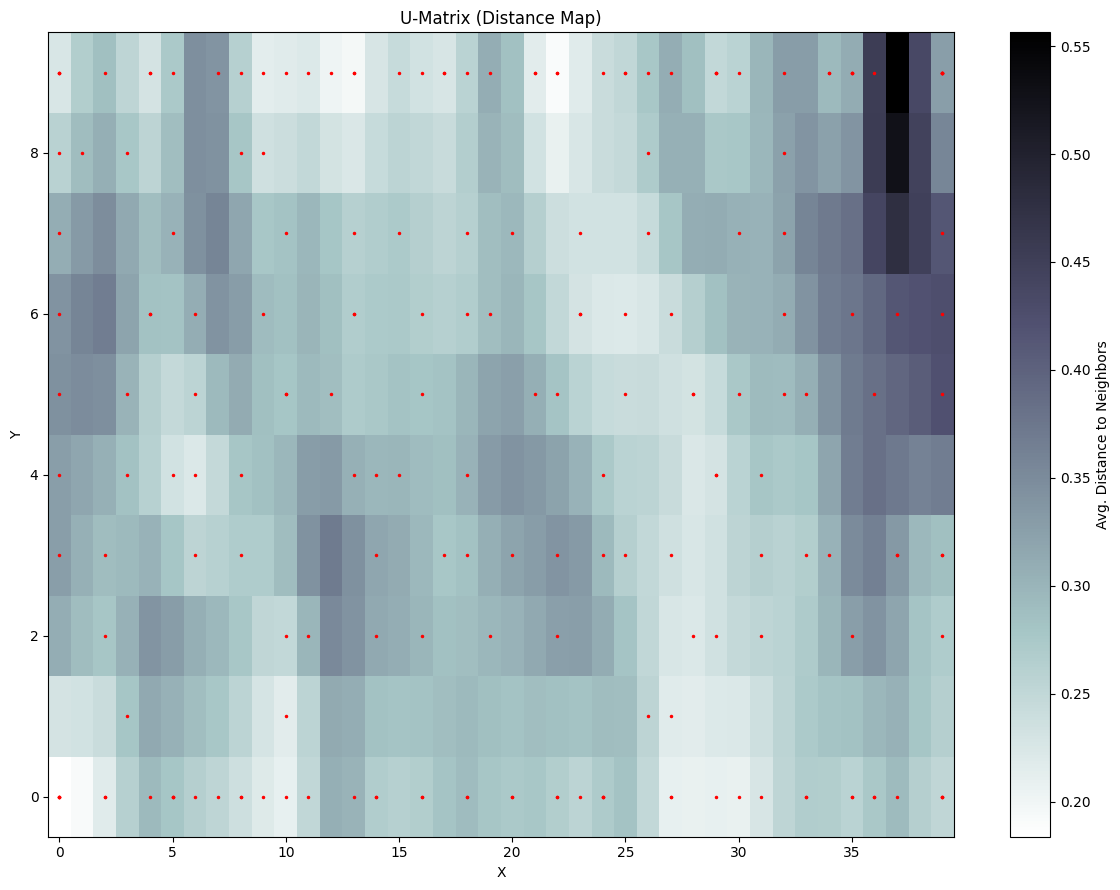

In [87]:
umatrix2 = compute_umatrix(best_model2, best_size2)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(umatrix2.T, cmap='bone_r', origin='lower', aspect='auto')
ax.set_title('U-Matrix (Distance Map)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.colorbar(im, ax=ax, label='Avg. Distance to Neighbors')

for country, (bx, by) in country_bmu2.items():
    ax.plot(bx, by, 'r.', markersize=3)

plt.tight_layout()
plt.show()

In [88]:
dataset2_minmax.info()

<class 'pandas.core.frame.DataFrame'>
Index: 195 entries, Afghanistan to Zimbabwe
Data columns (total 26 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Density
(P/Km2)                            195 non-null    float64
 1   Minimum wage                               195 non-null    float64
 2   Tax revenue (%)                            195 non-null    float64
 3   Armed Forces size                          195 non-null    float64
 4   Gasoline Price                             195 non-null    float64
 5   Population: Labor force participation (%)  195 non-null    float64
 6   Unemployment rate                          195 non-null    float64
 7   CPI                                        195 non-null    float64
 8   CPI Change (%)                             195 non-null    float64
 9   Maternal mortality ratio                   195 non-null    float64
 10  Gross tertiary e

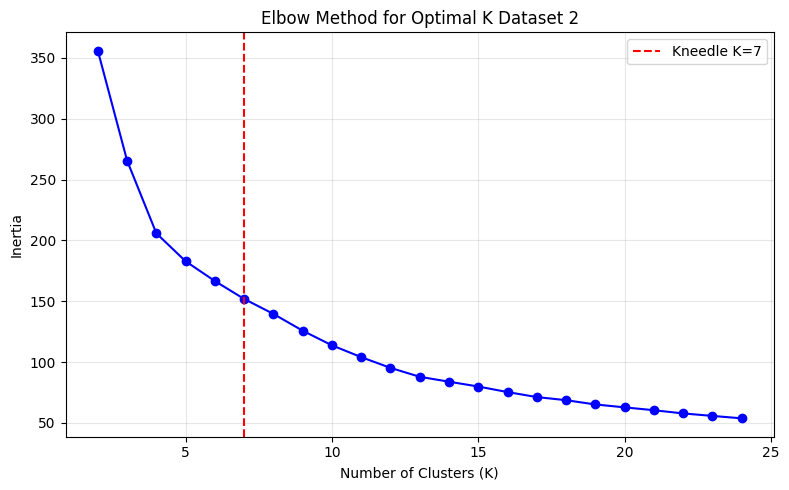

Selected K = 7


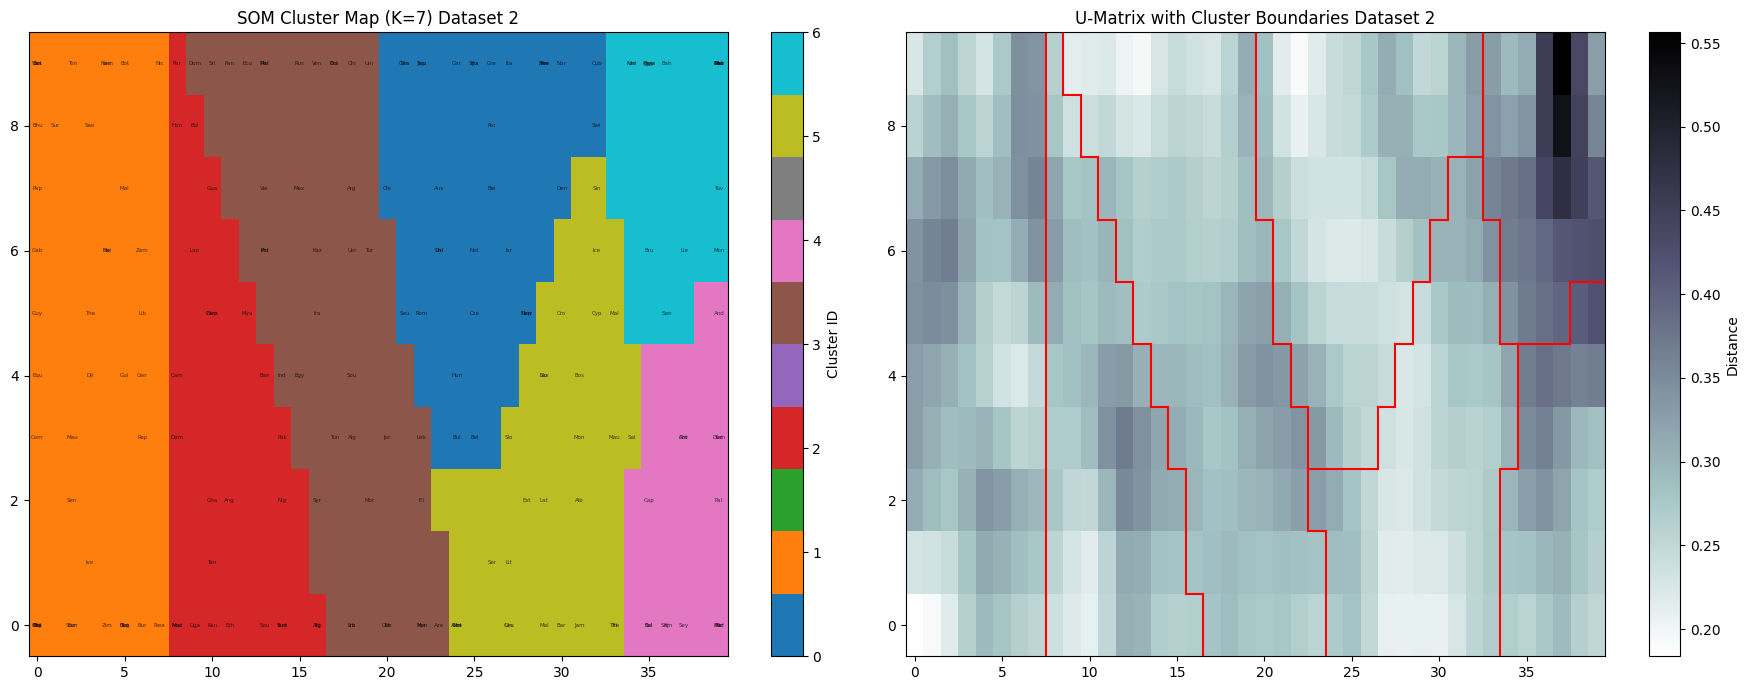


Number of groups: 7

Cluster 0 (32 countries):
  Australia, Austria, Belarus, Belgium, Bulgaria, Canada, Chile, Cuba, Czech Republic, Denmark, Finland, France, Germany, Greece, Hungary, Israel, Italy, Japan, Netherlands, New Zealand, Norway, Poland, Portugal, Republic of Ireland, Romania, Saudi Arabia, South Korea, Spain, Sweden, Switzerland, Thailand, United Kingdom

Cluster 1 (41 countries):
  Benin, Bhutan, Botswana, Burkina Faso, Burundi, Central African Republic, Chad, Comoros, Djibouti, East Timor, Equatorial Guinea, Eritrea, Gabon, Guinea, Guinea-Bissau, Guyana, Haiti, Ivory Coast, Lesotho, Liberia, Malawi, Mali, Mauritania, Namibia, Nicaragua, Niger, Papua New Guinea, Republic of the Congo, Rwanda, Sao Tome & Principe, Senegal, Sierra Leone, Solomon Islands, Somalia, Suriname, The Gambia, Togo, Tonga, Vanuatu, Zambia, Zimbabwe

Cluster 2 (26 countries):
  Afghanistan, Angola, Bangladesh, Bolivia, Cambodia, Cameroon, Democratic Republic of the Congo, Ethiopia, Ghana, Guatemala,

In [89]:
country_clusters2, km2, neuron_labels2 = som_kmeans_clustering(
    best_model2, best_size2, country_bmu2, umatrix2,
    k_optimal=5, dataset_label="Dataset 2"
)

In [90]:
plot_cluster_map(country_clusters2, k_optimal=6, dataset_label="Dataset 2")

# Creation of Dataset 3 —  **Economic** dataset

In [91]:
economic_cols = [
    "GDP",
    "Minimum wage",
    "Tax revenue (%)",
    "Total tax rate",
    "Gasoline Price",
    "CPI",
    "CPI Change (%)",
    "Unemployment rate",
    "Population: Labor force participation (%)",
    "Armed Forces size",
]

dataset3_minmax = dataset2_minmax[economic_cols].copy()
print(f"Shape dataset3_minmax: {dataset3_minmax.shape}")
print(f"NaNs: {dataset3_minmax.isna().sum().sum()}  should be 0")

Shape dataset3_minmax: (195, 10)
NaNs: 0  should be 0


In [92]:
dataset3_minmax

,GDP,Minimum wage,Tax revenue (%),Total tax rate,Gasoline Price,CPI,CPI Change (%),Unemployment rate,Population: Labor force participation (%),Armed Forces size
Country,,,,,,,,,,
Afghanistan,0.416667,0.333333,0.2,1.000000,0.222222,0.727273,0.555556,0.818182,0.181818,0.888889
Albania,0.416667,0.555556,0.7,0.545455,0.888889,0.454545,0.333333,0.909091,0.272727,0.222222
Algeria,0.750000,0.555556,1.0,1.000000,0.111111,0.727273,0.444444,0.909091,0.090909,0.888889
Andorra,0.166667,1.000000,0.0,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Angola,0.750000,0.444444,0.2,0.818182,0.555556,1.000000,1.000000,0.727273,0.909091,0.777778
...,...,...,...,...,...,...,...,...,...,...
Venezuela,0.916667,0.111111,0.0,1.000000,0.111111,1.000000,1.000000,0.727273,0.454545,1.000000
Vietnam,0.833333,0.444444,0.7,0.545455,0.333333,0.818182,0.666667,0.181818,0.909091,1.000000
Yemen,0.500000,0.000000,0.0,0.181818,0.444444,0.818182,0.888889,0.909091,0.090909,0.555556


Training of dataset 3

In [93]:
configs3 = [
    {"name": "Model 1", "size": [20,20], "lr": 0.1,  "epochs": 200000, "topology": "square",      "neighborhood": 10},
    {"name": "Model 2", "size": [40,10], "lr": 0.1,  "epochs": 200000, "topology": "rectangular", "neighborhood": 20},

    {"name": "Model 3", "size": [20,20], "lr": 0.05, "epochs": 600000, "topology": "square",      "neighborhood": 10},
    {"name": "Model 4", "size": [40,10], "lr": 0.05, "epochs": 600000, "topology": "rectangular", "neighborhood": 20},
]
maps_config3, trained_maps3 = train_all_soms(configs3, dataset3_minmax)

Training Model 1 — SOM 20x20 | lr=0.1 | epochs=200000 | neighborhood=10
Training Model 2 — SOM 40x10 | lr=0.1 | epochs=200000 | neighborhood=20
Training Model 3 — SOM 20x20 | lr=0.05 | epochs=600000 | neighborhood=10
Training Model 4 — SOM 40x10 | lr=0.05 | epochs=600000 | neighborhood=20


Comparation of models

In [94]:
results_df3, best_square_name3, best_rect_name3, best_overall_name3 = compare_models(trained_maps3)

best_model3 = trained_maps3[best_overall_name3]["weight_matrix"]
best_size3  = trained_maps3[best_overall_name3]["size"]

  Model  Size    Topology   LR  Epochs     QE     TE
Model 2 40x10 rectangular 0.10  200000 0.4217 0.0051
Model 4 40x10 rectangular 0.05  600000 0.4256 0.0000
Model 1 20x20      square 0.10  200000 0.4273 0.0000
Model 3 20x20      square 0.05  600000 0.4291 0.0000

Best square model:      Model 1  (20x20)
Best rectangular model: Model 2  (40x10)
Best overall model:     Model 2  (40x10)


In [95]:

print("="*60)
print(f"Mejor modelo: {best_overall_name3}")
print(f"Tamaño: {best_size3[0]}x{best_size3[1]}")
print("="*60)

initial_data3 = dataset3_minmax.values


qe_errors3 = []
for dp in initial_data3:
    bmu_w, _ = calculate_bmu(dp, best_model3, best_size3)
    qe_errors3.append(np.linalg.norm(dp - bmu_w))

qe3 = np.mean(qe_errors3)
print(f"\nQuantization Error (QE): {qe3:.4f}")
print(f"  → Distancia media país-BMU en el espacio normalizado [0,1]")


te_count3 = 0
for dp in initial_data3:
    dists = np.sqrt(((best_model3 - dp) ** 2).sum(axis=2))
    flat_sorted = np.argsort(dists.flatten())
    bmu1 = np.unravel_index(flat_sorted[0], best_size3)
    bmu2 = np.unravel_index(flat_sorted[1], best_size3)
    if abs(bmu1[0]-bmu2[0]) > 1 or abs(bmu1[1]-bmu2[1]) > 1:
        te_count3 += 1

te3 = te_count3 / len(initial_data3)
print(f"\nTopographic Error (TE): {te3:.4f}")
print(f"  → {te_count3}/{len(initial_data3)} países con discontinuidad topológica")


print(f"\n{'─'*60}")
print(f"{'Dataset':<20} {'QE':>8} {'TE':>8}")
print(f"{'─'*60}")
print(f"{'Dataset 1':<20} {trained_maps[best_overall_name]['qe']:>8.4f} {trained_maps[best_overall_name]['te']:>8.4f}")
print(f"{'Dataset 2':<20} {trained_maps2[best_overall_name2]['qe']:>8.4f} {trained_maps2[best_overall_name2]['te']:>8.4f}")
print(f"{'Dataset 3 Económico':<20} {qe3:>8.4f} {te3:>8.4f}")
print(f"{'─'*60}")
print(f"\nNota: QE más alto en Dataset 3 es esperable — con solo 11 features")
print(f"el espacio es más disperso que con el dataset completo.")

Mejor modelo: Model 2
Tamaño: 40x10

Quantization Error (QE): 0.4217
  → Distancia media país-BMU en el espacio normalizado [0,1]

Topographic Error (TE): 0.0051
  → 1/195 países con discontinuidad topológica

────────────────────────────────────────────────────────────
Dataset                    QE       TE
────────────────────────────────────────────────────────────
Dataset 1              0.5091   0.0000
Dataset 2              0.7150   0.0000
Dataset 3 Económico    0.4217   0.0051
────────────────────────────────────────────────────────────

Nota: QE más alto en Dataset 3 es esperable — con solo 11 features
el espacio es más disperso que con el dataset completo.


In [96]:
neuron_countries3, country_bmu3 = build_classification_map(dataset3_minmax, best_model3, best_size3)

Classification Map (40x10):
Active neurons: 152 / 400

  Neuron ( 0, 0): Georgia, Namibia, South Africa
  Neuron ( 0, 1): Botswana
  Neuron ( 0, 2): Lesotho
  Neuron ( 0, 4): Suriname
  Neuron ( 0, 5): Zambia
  Neuron ( 0, 6): Malawi
  Neuron ( 0, 9): The Gambia, Guinea, Haiti
  Neuron ( 1, 3): Sao Tome & Principe
  Neuron ( 1, 6): Sierra Leone
  Neuron ( 1, 9): Central African Republic
  Neuron ( 2, 0): Armenia
  Neuron ( 2, 1): Kyrgyzstan
  Neuron ( 2, 2): Mongolia
  Neuron ( 2, 4): Moldova
  Neuron ( 2, 6): Papua New Guinea
  Neuron ( 2, 9): Liberia
  Neuron ( 3, 8): Bhutan
  Neuron ( 4, 0): Guyana, Libya
  Neuron ( 4, 4): Honduras, Nicaragua
  Neuron ( 4, 5): Ghana
  Neuron ( 5, 0): Gabon, Montenegro
  Neuron ( 5, 3): Republic of the Congo
  Neuron ( 5, 6): Cameroon
  Neuron ( 5, 9): Burundi, Madagascar, Rwanda
  Neuron ( 6, 1): Djibouti
  Neuron ( 6, 4): Paraguay
  Neuron ( 6, 7): Mozambique
  Neuron ( 7, 0): Mauritania
  Neuron ( 7, 3): Democratic Republic of the Congo, Dominican

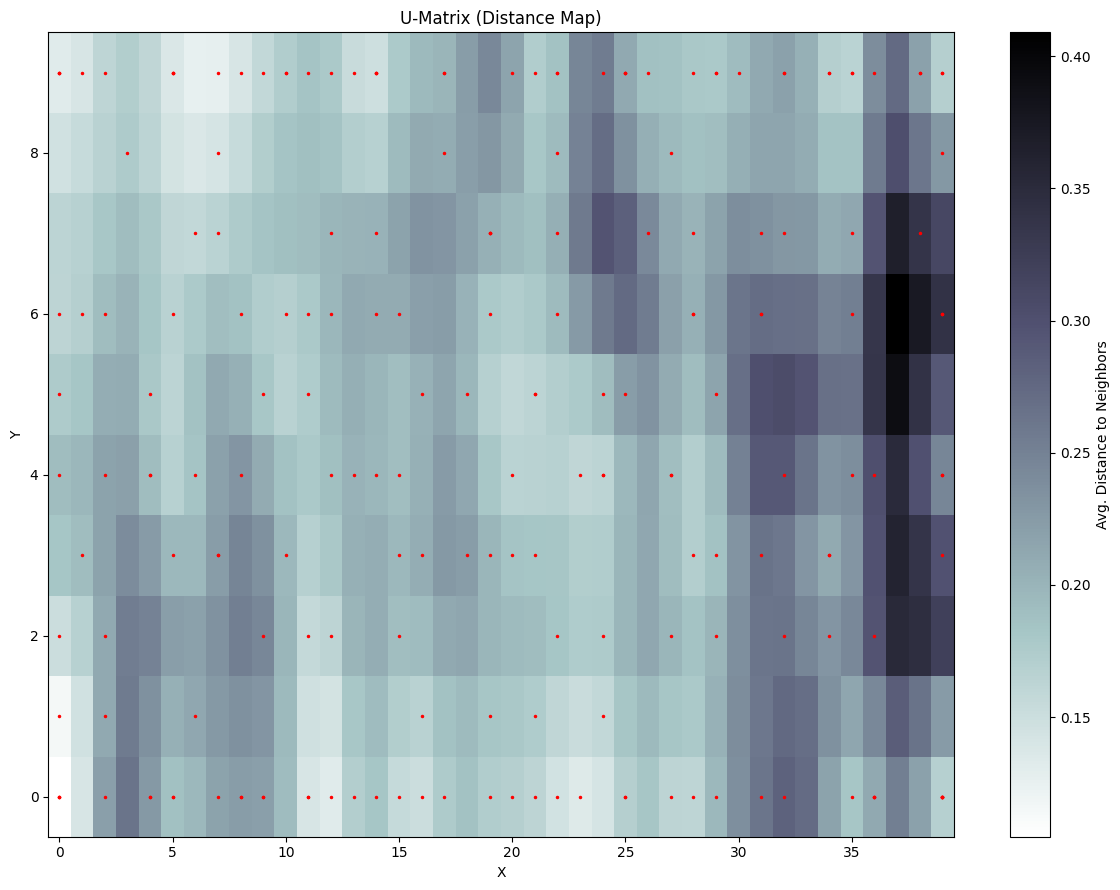

In [97]:
umatrix3 = compute_umatrix(best_model3, best_size3)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(umatrix3.T, cmap='bone_r', origin='lower', aspect='auto')
ax.set_title('U-Matrix (Distance Map)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.colorbar(im, ax=ax, label='Avg. Distance to Neighbors')

for country, (bx, by) in country_bmu3.items():
    ax.plot(bx, by, 'r.', markersize=3)

plt.tight_layout()
plt.show()

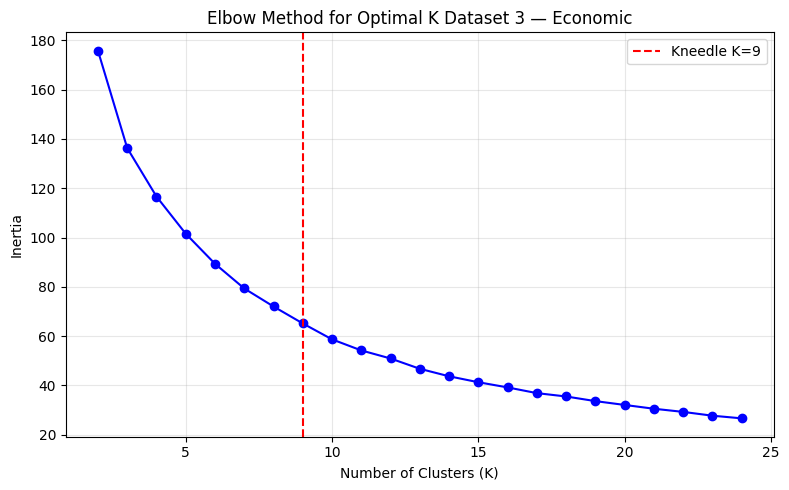

Selected K = 9


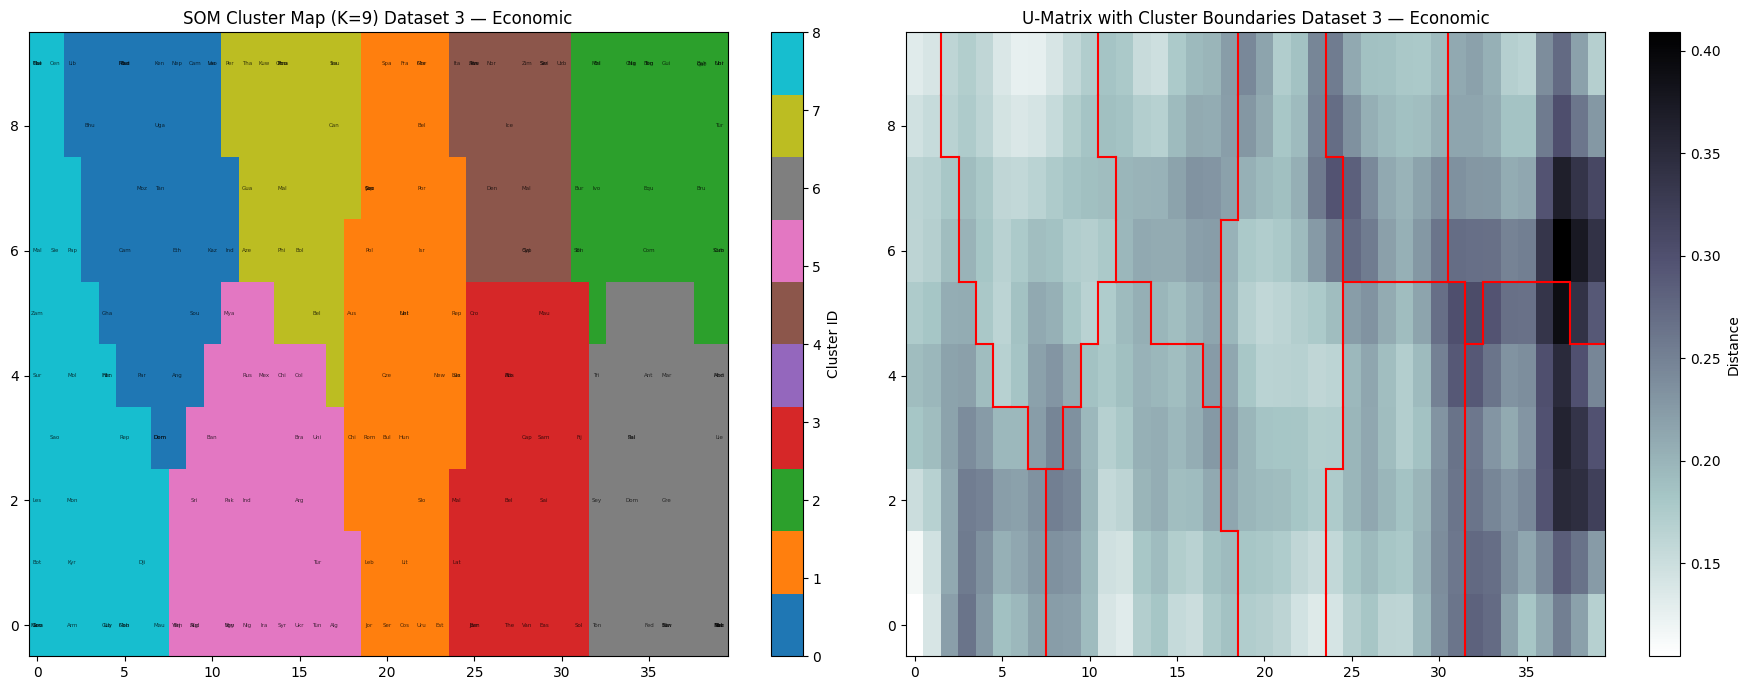


Number of groups: 9

Cluster 0 (23 countries):
  Angola, Bhutan, Burundi, Cambodia, Cameroon, Democratic Republic of the Congo, Dominican Republic, Ethiopia, Ghana, Indonesia, Kazakhstan, Kenya, Laos, Liberia, Madagascar, Mozambique, Nepal, Paraguay, Rwanda, South Sudan, Tanzania, Uganda, Vietnam

Cluster 1 (31 countries):
  Australia, Belgium, Bulgaria, Chile, Costa Rica, Czech Republic, Estonia, France, Germany, Greece, Hungary, Israel, Japan, Jordan, Lebanon, Lithuania, Luxembourg, Morocco, Netherlands, New Zealand, Poland, Portugal, Republic of Ireland, Romania, Serbia, Slovakia, Slovenia, South Korea, Spain, United Kingdom, Uruguay

Cluster 2 (21 countries):
  Bahrain, Benin, Brunei, Burkina Faso, Chad, Comoros, Cuba, El Salvador, Equatorial Guinea, Eritrea, Guinea-Bissau, Ivory Coast, Mali, Niger, North Korea, Qatar, Senegal, Somalia, Togo, Turkmenistan, United Arab Emirates

Cluster 3 (17 countries):
  Albania, Barbados, Belize, Bosnia and Herzegovina, Cape Verde, Croatia, East

In [98]:
country_clusters3, km3, neuron_labels3 = som_kmeans_clustering(
    best_model3, best_size3, country_bmu3, umatrix3,
    k_optimal=5, dataset_label="Dataset 3 — Economic"
)

In [99]:
plot_cluster_map(country_clusters3, k_optimal=5, dataset_label="Dataset 3 — Económico")

# Creation pf Dataset 4 — Demographic dataset

In [100]:
demographic_cols = [
    "Population",
    "Birth Rate",
    "Fertility Rate",
    "Infant mortality",
    "Life expectancy",
    "Maternal mortality ratio",
    "Physicians per thousand",
    "Out of pocket health expenditure",
    "Gross primary education enrollment (%)",
    "Gross tertiary education enrollment (%)",
    "Urban_population",
]

dataset4_minmax = dataset2_minmax[demographic_cols].copy()
print(f"Shape dataset4_minmax: {dataset4_minmax.shape}")
print(f"NaNs: {dataset4_minmax.isna().sum().sum()}  should be 0")

Shape dataset4_minmax: (195, 11)
NaNs: 0  should be 0


In [101]:
dataset4_minmax

,Population,Birth Rate,Fertility Rate,Infant mortality,Life expectancy,Maternal mortality ratio,Physicians per thousand,Out of pocket health expenditure,Gross primary education enrollment (%),Gross tertiary education enrollment (%),Urban_population
Country,,,,,,,,,,,
Afghanistan,0.833333,0.916667,0.909091,0.909091,0.2,1.000000,0.272727,1.000000,0.636364,0.250000,0.750000
Albania,0.333333,0.333333,0.272727,0.363636,0.8,0.333333,0.545455,0.909091,0.727273,0.750000,0.333333
Algeria,0.833333,0.750000,0.727273,0.636364,0.7,0.666667,0.636364,0.545455,0.818182,0.666667,0.916667
Andorra,0.083333,0.083333,0.090909,0.090909,0.0,0.000000,0.818182,0.636364,0.727273,0.000000,0.166667
Angola,0.833333,1.000000,1.000000,1.000000,0.1,0.777778,0.272727,0.545455,0.909091,0.250000,0.833333
...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,0.750000,0.500000,0.545455,0.636364,0.5,0.666667,0.636364,0.818182,0.272727,0.916667,0.833333
Vietnam,1.000000,0.500000,0.454545,0.545455,0.7,0.555556,0.454545,0.727273,0.909091,0.500000,0.916667
Yemen,0.833333,0.833333,0.818182,0.909091,0.3,0.777778,0.272727,1.000000,0.181818,0.250000,0.750000


Training dataset 4

In [102]:
configs4 = [
    {"name": "Model 1", "size": [20,20], "lr": 0.1,  "epochs": 200000, "topology": "square",      "neighborhood": 10},
    {"name": "Model 2", "size": [40,10], "lr": 0.1,  "epochs": 200000, "topology": "rectangular", "neighborhood": 20},

    {"name": "Model 3", "size": [20,20], "lr": 0.05, "epochs": 600000, "topology": "square",      "neighborhood": 10},
    {"name": "Model 4", "size": [40,10], "lr": 0.05, "epochs": 600000, "topology": "rectangular", "neighborhood": 20},
]

maps_config4, trained_maps4 = train_all_soms(configs4, dataset4_minmax)

Training Model 1 — SOM 20x20 | lr=0.1 | epochs=200000 | neighborhood=10
Training Model 2 — SOM 40x10 | lr=0.1 | epochs=200000 | neighborhood=20
Training Model 3 — SOM 20x20 | lr=0.05 | epochs=600000 | neighborhood=10
Training Model 4 — SOM 40x10 | lr=0.05 | epochs=600000 | neighborhood=20


Comparation

In [103]:
results_df4, best_square_name4, best_rect_name4, best_overall_name4 = compare_models(trained_maps4)

best_model4 = trained_maps4[best_overall_name4]["weight_matrix"]
best_size4  = trained_maps4[best_overall_name4]["size"]

  Model  Size    Topology   LR  Epochs     QE  TE
Model 1 20x20      square 0.10  200000 0.3051 0.0
Model 4 40x10 rectangular 0.05  600000 0.3058 0.0
Model 2 40x10 rectangular 0.10  200000 0.3061 0.0
Model 3 20x20      square 0.05  600000 0.3070 0.0

Best square model:      Model 1  (20x20)
Best rectangular model: Model 4  (40x10)
Best overall model:     Model 1  (20x20)


In [104]:
neuron_countries4, country_bmu4 = build_classification_map(dataset4_minmax, best_model4, best_size4)

Classification Map (20x20):
Active neurons: 152 / 400

  Neuron ( 0, 0): Angola, Madagascar, Mozambique
  Neuron ( 0, 2): Benin
  Neuron ( 0, 3): Togo
  Neuron ( 0, 4): Republic of the Congo
  Neuron ( 0, 7): Guinea, South Sudan
  Neuron ( 0, 8): Chad, Niger
  Neuron ( 0, 9): Mali
  Neuron ( 0,10): Burkina Faso
  Neuron ( 0,12): Somalia, Tanzania
  Neuron ( 0,14): Ethiopia, Uganda
  Neuron ( 0,15): Democratic Republic of the Congo
  Neuron ( 0,16): Afghanistan, Cameroon
  Neuron ( 0,18): Cambodia
  Neuron ( 0,19): Nepal
  Neuron ( 1, 1): Zimbabwe
  Neuron ( 1, 2): Haiti
  Neuron ( 1, 3): Sierra Leone
  Neuron ( 1,12): Zambia
  Neuron ( 1,13): Ivory Coast
  Neuron ( 1,19): Myanmar
  Neuron ( 2, 0): Burundi, Malawi
  Neuron ( 2, 3): Guinea-Bissau
  Neuron ( 2, 5): Central African Republic
  Neuron ( 2, 6): Mauritania
  Neuron ( 2, 9): Senegal
  Neuron ( 2,10): Nigeria
  Neuron ( 2,14): Kenya
  Neuron ( 2,15): Ghana
  Neuron ( 2,17): Iraq
  Neuron ( 3, 0): Rwanda
  Neuron ( 3, 7): Equator

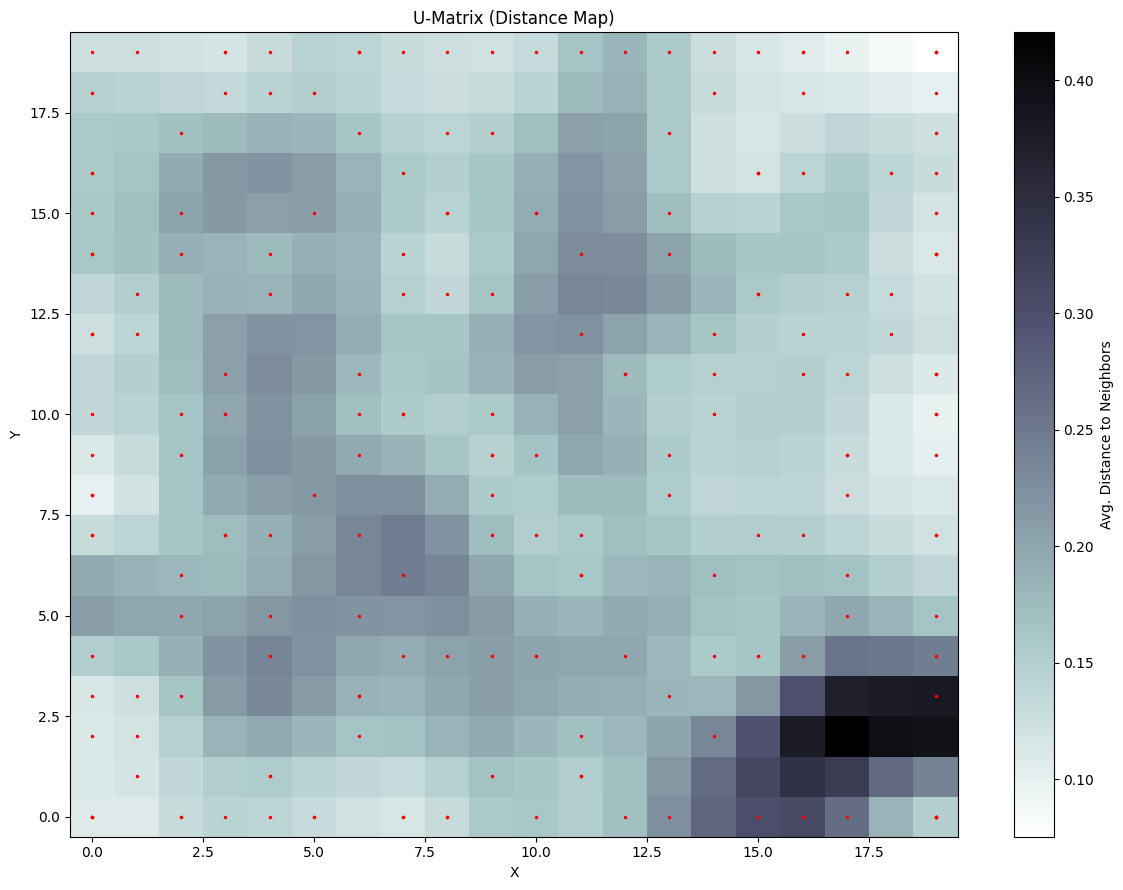

In [105]:
umatrix4 = compute_umatrix(best_model4, best_size4)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(umatrix4.T, cmap='bone_r', origin='lower', aspect='auto')
ax.set_title('U-Matrix (Distance Map)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.colorbar(im, ax=ax, label='Avg. Distance to Neighbors')
for country, (bx, by) in country_bmu4.items():
    ax.plot(bx, by, 'r.', markersize=3)
plt.tight_layout()
plt.show()

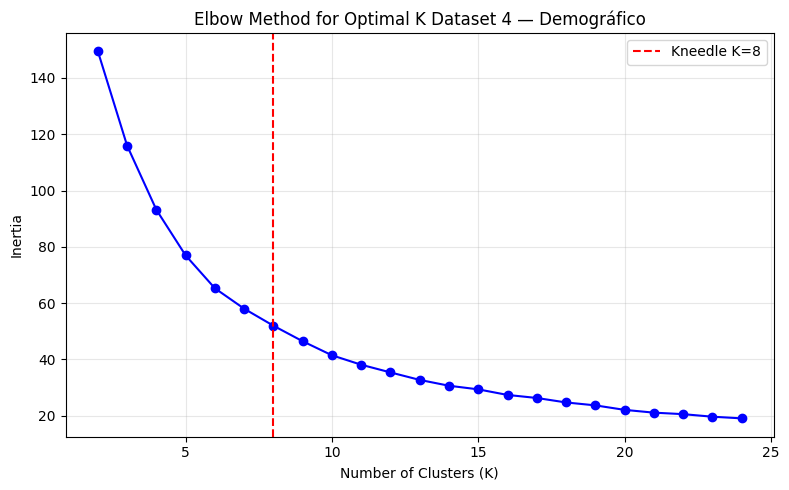

Selected K = 8


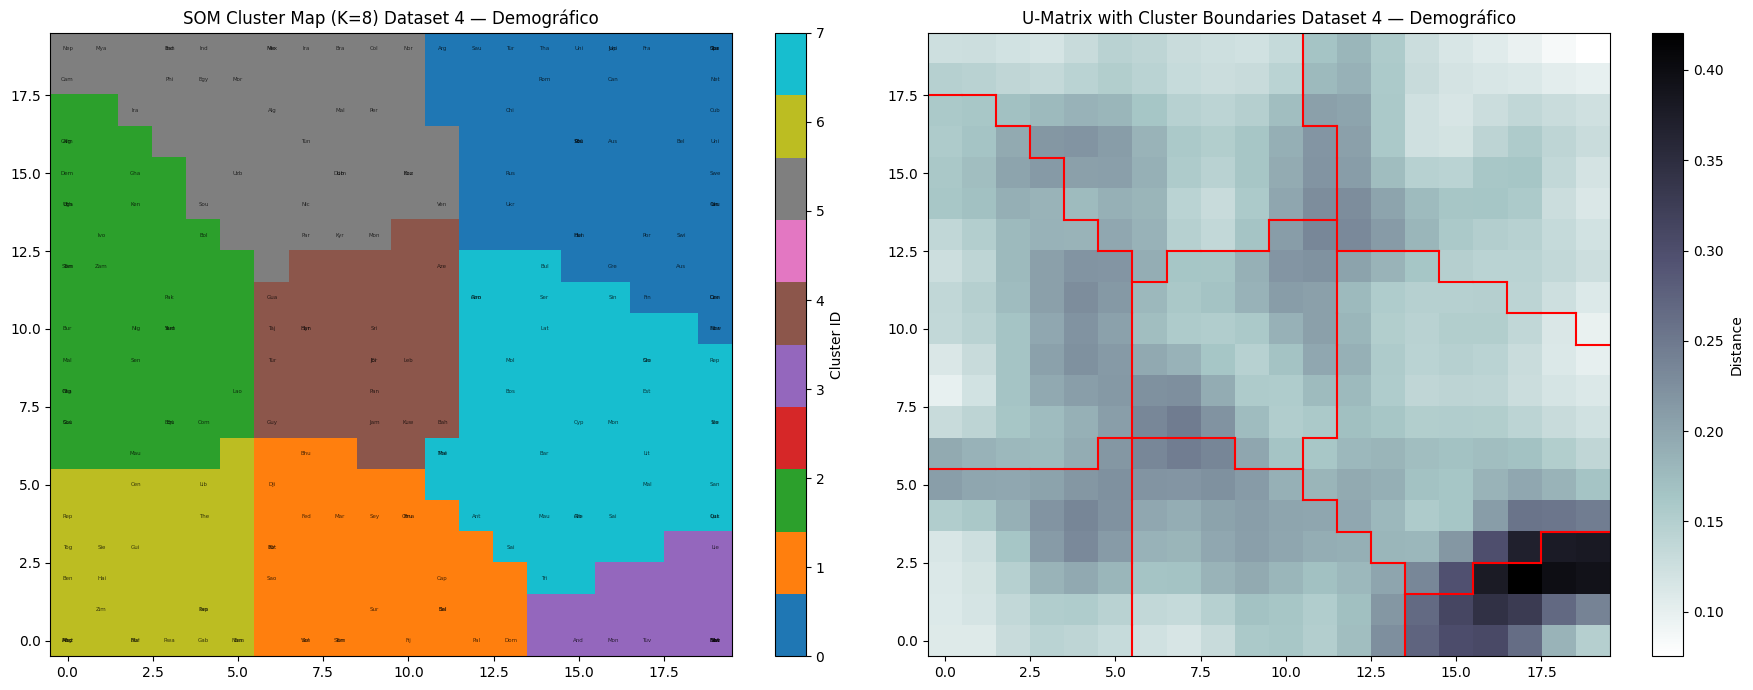


Number of groups: 8

Cluster 0 (39 countries):
  Argentina, Australia, Austria, Belarus, Belgium, Canada, Chile, China, Costa Rica, Cuba, Czech Republic, Denmark, Finland, France, Germany, Greece, Hungary, Israel, Italy, Japan, Netherlands, New Zealand, Norway, Poland, Portugal, Romania, Russia, Saudi Arabia, South Korea, Spain, Sweden, Switzerland, Thailand, Turkey, Ukraine, United Arab Emirates, United Kingdom, United States, Uruguay

Cluster 1 (21 countries):
  Belize, Bhutan, Botswana, Brunei, Cape Verde, Djibouti, Dominica, Federated States of Micronesia, Fiji, Kiribati, Marshall Islands, Oman, Palau, Saint Vincent and the Grenadines, Samoa, Sao Tome & Principe, Seychelles, Solomon Islands, Suriname, Tonga, Vanuatu

Cluster 2 (28 countries):
  Afghanistan, Bolivia, Burkina Faso, Cameroon, Chad, Comoros, Democratic Republic of the Congo, Equatorial Guinea, Eritrea, Ethiopia, Ghana, Guinea, Ivory Coast, Kenya, Laos, Mali, Mauritania, Niger, Nigeria, Pakistan, Senegal, Somalia, Sout

In [106]:
country_clusters4, km4, neuron_labels4 = som_kmeans_clustering(
    best_model4, best_size4, country_bmu4, umatrix4,
    k_optimal=5, dataset_label="Dataset 4 — Demográfico"
)

In [107]:
plot_cluster_map(country_clusters4, k_optimal=5, dataset_label="Dataset 4 — Demográfico")

Pregunta una es el activation map de arriba del dataset 2 creo q hay q añadir solo alguna cosa para marcar los grupos

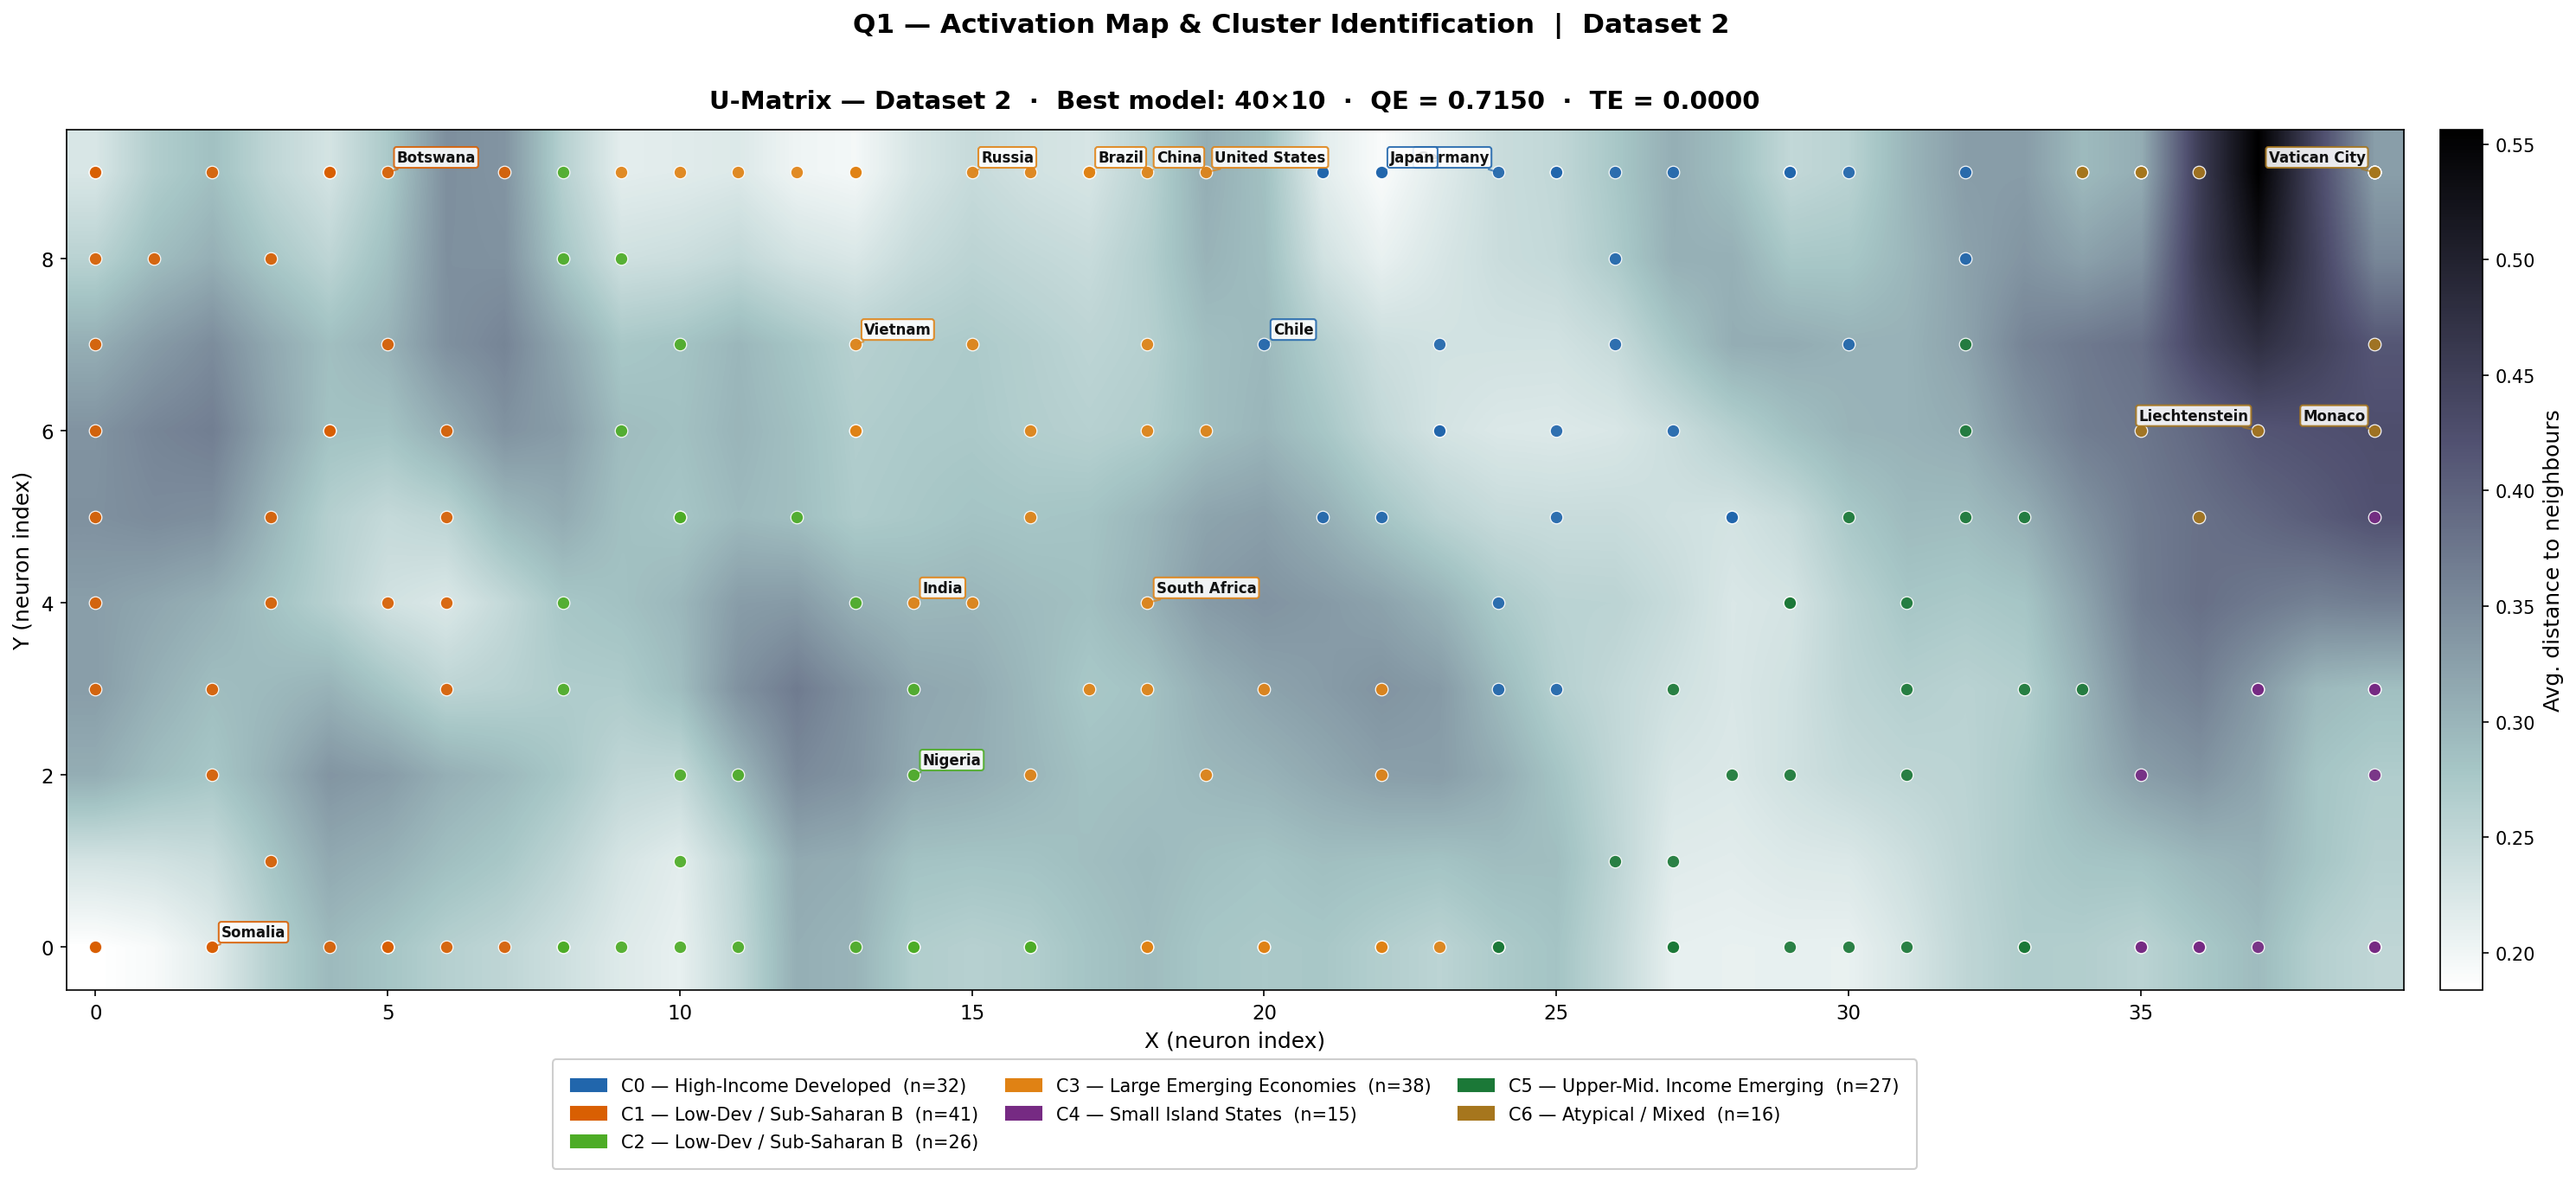


K = 7 clusters  |  QE = 0.7150

C0 — High-Income Developed (n=32):
  Australia, Austria, Belarus, Belgium, Bulgaria, Canada, Chile, Cuba, Czech Republic, Denmark, Finland, France, Germany, Greece, Hungary, Israel, Italy, Japan, Netherlands, New Zealand, Norway, Poland, Portugal, Republic of Ireland, Romania, Saudi Arabia, South Korea, Spain, Sweden, Switzerland, Thailand, United Kingdom

C1 — Low-Dev / Sub-Saharan B (n=41):
  Benin, Bhutan, Botswana, Burkina Faso, Burundi, Central African Republic, Chad, Comoros, Djibouti, East Timor, Equatorial Guinea, Eritrea, Gabon, Guinea, Guinea-Bissau, Guyana, Haiti, Ivory Coast, Lesotho, Liberia, Malawi, Mali, Mauritania, Namibia, Nicaragua, Niger, Papua New Guinea, Republic of the Congo, Rwanda, Sao Tome & Principe, Senegal, Sierra Leone, Solomon Islands, Somalia, Suriname, The Gambia, Togo, Tonga, Vanuatu, Zambia, Zimbabwe

C2 — Low-Dev / Sub-Saharan B (n=26):
  Afghanistan, Angola, Bangladesh, Bolivia, Cambodia, Cameroon, Democratic Republic

In [108]:

import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

k2 = len(set(country_clusters2.values()))

cluster_names2 = {}
for cid in range(k2):
    members = [c for c, cl in country_clusters2.items()
               if cl == cid and c in dataset2_minmax.index]
    sub = dataset2_minmax.loc[members]
    le  = sub['Life expectancy'].mean()
    im  = sub['Infant mortality'].mean()
    gdp = sub['GDP'].mean()
    n   = len(members)
    if   le > 0.75 and im < 0.25:   cluster_names2[cid] = "High-Income Developed"
    elif im > 0.80:                  cluster_names2[cid] = "Low-Dev / Sub-Saharan B"
    elif im > 0.60:                  cluster_names2[cid] = "Low-Dev / Sub-Saharan A"
    elif gdp > 0.65:                 cluster_names2[cid] = "Large Emerging Economies"
    elif gdp < 0.20 and n < 20:      cluster_names2[cid] = "Small Island States"
    elif le > 0.65 and im < 0.40:    cluster_names2[cid] = "Upper-Mid. Income Emerging"
    else:                            cluster_names2[cid]   = "Atypical / Mixed"

PALETTE = ["#2166AC","#D95F02","#4DAC26","#E08214","#762A83","#1B7837",
           "#A6761D","#666666","#E7298A","#66C2A5"]
CUSTOM_COLORS = PALETTE[:k2]

fig, ax1 = plt.subplots(figsize=(20, 9), dpi=150)
fig.patch.set_facecolor('white')

im_plot = ax1.imshow(umatrix2.T, cmap='bone_r', origin='lower',
                     aspect='auto', interpolation='bilinear')
cbar = plt.colorbar(im_plot, ax=ax1, pad=0.015, fraction=0.02)
cbar.set_label('Avg. distance to neighbours', fontsize=12)
cbar.ax.tick_params(labelsize=10)

for country, (bx, by) in country_bmu2.items():
    cid = country_clusters2.get(country, 0)
    col = CUSTOM_COLORS[cid % len(CUSTOM_COLORS)]
    ax1.plot(bx, by, 'o', color=col,
             markersize=7, markeredgecolor='white',
             markeredgewidth=0.6, alpha=0.92, zorder=3)

label_these = ['United States', 'China', 'India', 'Germany', 'Brazil',
               'Liechtenstein', 'Vietnam', 'Chile', 'Botswana',
               'Monaco', 'Vatican City', 'Somalia', 'South Africa',
               'Russia', 'Japan', 'Nigeria']
for country in label_these:
    if country not in country_bmu2:
        continue
    bx, by = country_bmu2[country]
    cid = country_clusters2.get(country, 0)
    col = CUSTOM_COLORS[cid % len(CUSTOM_COLORS)]
    ox = 5 if bx < best_size2[0] * 0.6 else -5
    ha = 'left' if ox > 0 else 'right'
    ax1.annotate(
        country, xy=(bx, by), xytext=(ox, 4),
        textcoords='offset points',
        fontsize=8, fontweight='bold',
        color='#111111', ha=ha, va='bottom', zorder=5,
        arrowprops=dict(arrowstyle='-', color=col, lw=1.0, alpha=0.7),
        bbox=dict(boxstyle='round,pad=0.18', fc='white', ec=col, lw=1.0, alpha=0.88)
    )

patches_legend = [mpatches.Patch(
    color=CUSTOM_COLORS[i],
    label=f'C{i} — {cluster_names2[i]}  (n={sum(1 for cl in country_clusters2.values() if cl==i)})')
    for i in range(k2)]
ax1.legend(handles=patches_legend, fontsize=10, loc='upper center',
           bbox_to_anchor=(0.5, -0.07), ncol=3, framealpha=0.95,
           edgecolor='#CCCCCC', borderpad=1.0, labelspacing=0.6, columnspacing=1.5)

ax1.set_title(
    f'U-Matrix — Dataset 2  ·  Best model: {best_size2[0]}×{best_size2[1]}  '
    f'·  QE = {trained_maps2[best_overall_name2]["qe"]:.4f}  '
    f'·  TE = {trained_maps2[best_overall_name2]["te"]:.4f}',
    fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel('X (neuron index)', fontsize=12)
ax1.set_ylabel('Y (neuron index)', fontsize=12)
ax1.tick_params(labelsize=11)

fig.suptitle('Q1 — Activation Map & Cluster Identification  |  Dataset 2',
             fontsize=15, fontweight='bold', y=1.01)

plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print(f"K = {k2} clusters  |  QE = {trained_maps2[best_overall_name2]['qe']:.4f}")
print(f"{'='*60}")
for cid in range(k2):
    members = [c for c, cl in country_clusters2.items() if cl == cid]
    print(f"\nC{cid} — {cluster_names2[cid]} (n={len(members)}):")
    print(f"  {', '.join(sorted(members))}")

Pregunta 2

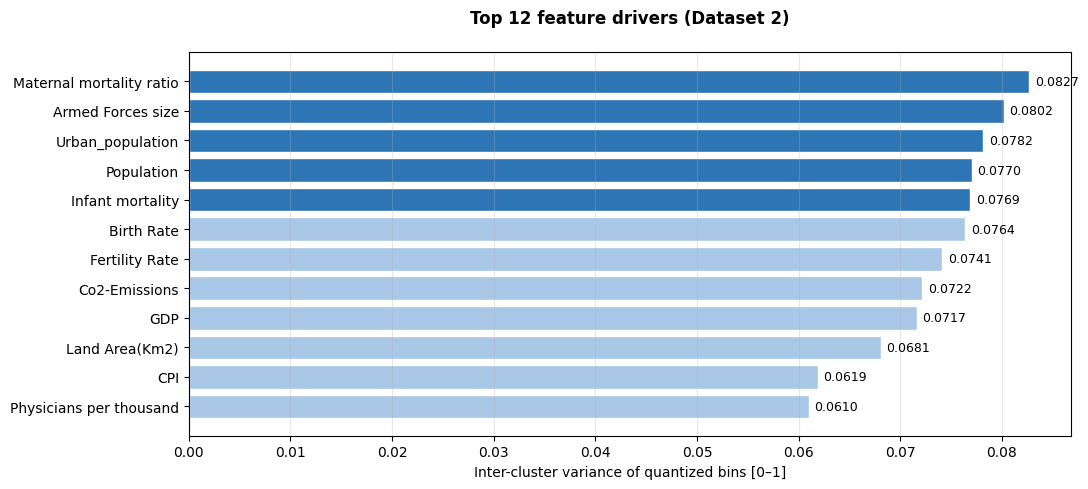

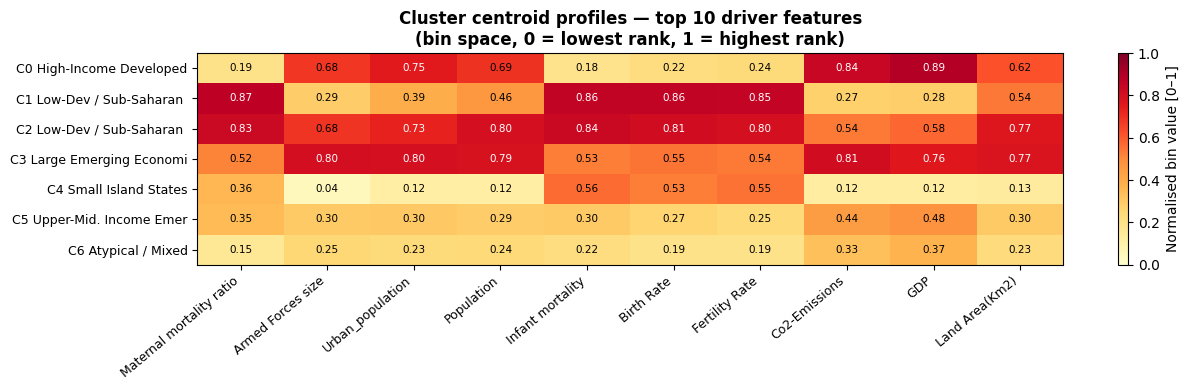


Q2 — Top 12 features by inter-cluster variance (Dataset 2)
  Feature                                             Variance
  ────────────────────────────────────────────────────────────
  Maternal mortality ratio                              0.0827
  Armed Forces size                                     0.0802
  Urban_population                                      0.0782
  Population                                            0.0770
  Infant mortality                                      0.0769
  Birth Rate                                            0.0764
  Fertility Rate                                        0.0741
  Co2-Emissions                                         0.0722
  GDP                                                   0.0717
  Land Area(Km2)                                        0.0681
  CPI                                                   0.0619
  Physicians per thousand                               0.0610


In [109]:

data_d2       = dataset2_minmax.copy()
data_d2['cluster'] = data_d2.index.map(country_clusters2)
feature_cols2 = [c for c in dataset2_minmax.columns]
centroids2    = data_d2.groupby('cluster')[feature_cols2].mean()
inter_var2    = centroids2.var(axis=0).sort_values(ascending=False)
top_n         = 12

fig, ax = plt.subplots(figsize=(11, 5))
colors_bar = ['#2E75B6' if i < 5 else '#A9C8E8' for i in range(top_n)]
bars = ax.barh(inter_var2.head(top_n).index[::-1],
               inter_var2.head(top_n).values[::-1],
               color=colors_bar[::-1], edgecolor='white')
ax.bar_label(bars, fmt='%.4f', padding=4, fontsize=9)
ax.set_xlabel('Inter-cluster variance of quantized bins [0–1]')
ax.set_title(f'Top {top_n} feature drivers (Dataset 2)\n',fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

top10        = inter_var2.head(10).index.tolist()
heatmap_data = centroids2[top10]

fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(top10)))
ax.set_xticklabels(top10, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(k2))
ax.set_yticklabels([f'C{i} {cluster_names2[i][:22]}' for i in range(k2)], fontsize=9)
plt.colorbar(im, ax=ax, label='Normalised bin value [0–1]')
for i in range(k2):
    for j in range(len(top10)):
        v = heatmap_data.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5,
                color='black' if v < 0.7 else 'white')
ax.set_title('Cluster centroid profiles — top 10 driver features\n'
             '(bin space, 0 = lowest rank, 1 = highest rank)', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n{'='*62}")
print(f"Q2 — Top {top_n} features by inter-cluster variance (Dataset 2)")
print(f"{'='*62}")
print(f"  {'Feature':<48}  {'Variance':>10}")
print(f"  {'─'*60}")
for feat, val in inter_var2.head(top_n).items():
    print(f"  {feat:<48}  {val:>10.4f}")

Pregunta 3

Q3 — Focus Country Classification (Dataset 2 — bin space)

────────────────────────────────────────────────────────────
  Liechtenstein → Cluster 6 (Atypical / Mixed) | BMU (37,6)
  Feature profile (bin space, top 6 drivers):
    Maternal mortality ratio                      0.00 (cluster mean 0.15)
    Armed Forces size                             0.00 (cluster mean 0.25)
    Urban_population                              0.08 (cluster mean 0.23)
    Population                                    0.08 (cluster mean 0.24)
    Infant mortality                              0.00 (cluster mean 0.22)
    Birth Rate                                    0.17 (cluster mean 0.19)
  dist_own=1.4953  mean_dist=1.4002  ratio=1.07  → FAR FROM CENTRE
  Nearest other clusters:
    C4 (Small Island States)  dist=1.7682
    C5 (Upper-Mid. Income Emerging)  dist=1.9679
    C0 (High-Income Developed)  dist=2.3221

────────────────────────────────────────────────────────────
  Vietnam → Cluster 3 (Large Emerg

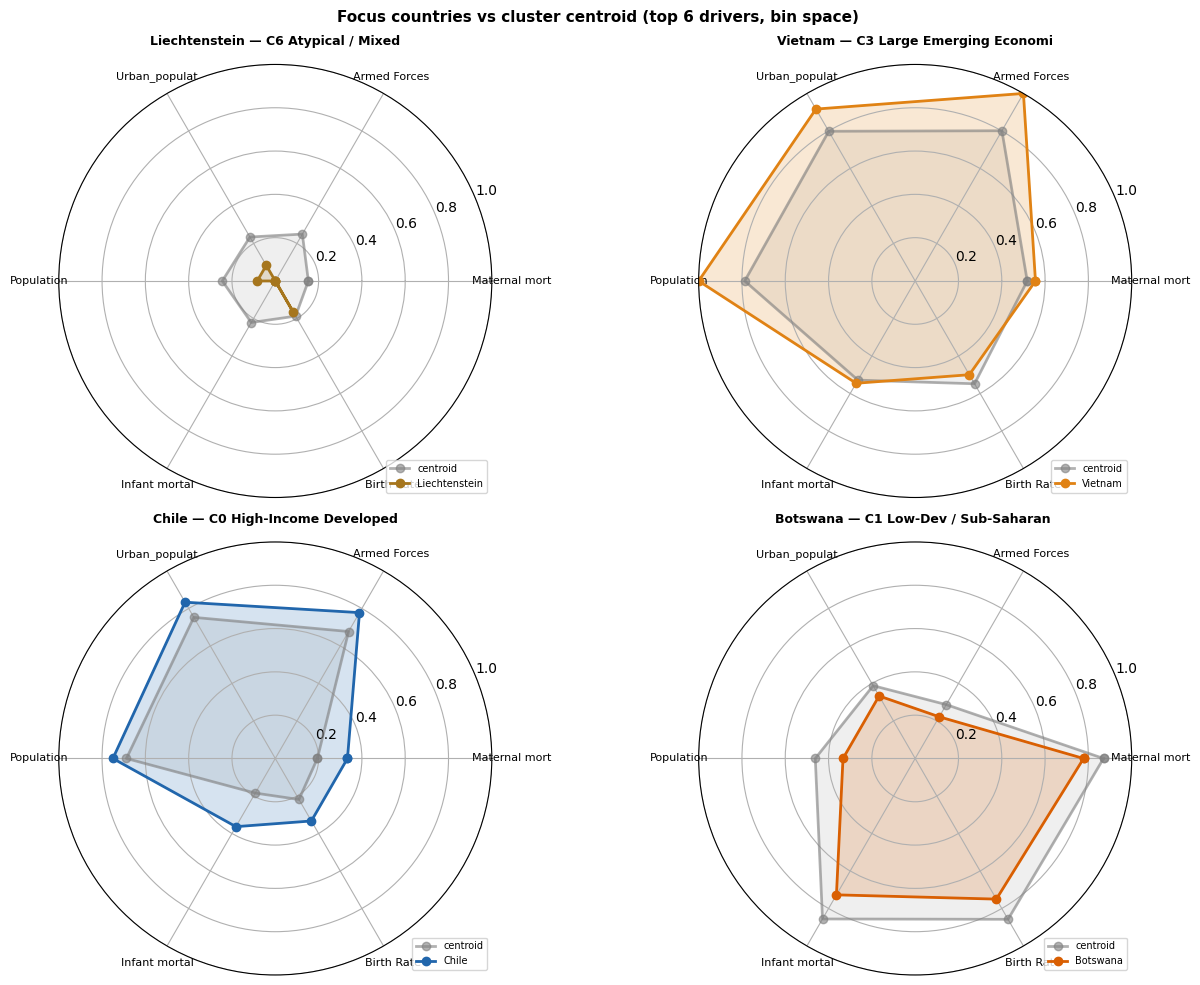

In [110]:


focus_countries = ['Liechtenstein', 'Vietnam', 'Chile', 'Botswana']
top6 = inter_var2.head(6).index.tolist()

print(f"{'='*65}")
print("Q3 — Focus Country Classification (Dataset 2 — bin space)")
print(f"{'='*65}")

for country in focus_countries:
    cid    = country_clusters2[country]
    vec    = dataset2_minmax.loc[country].values
    bx, by = country_bmu2[country]

    dist_own  = np.linalg.norm(vec - centroids2.loc[cid].values)
    peers     = [c for c, cl in country_clusters2.items()
                 if cl == cid and c in dataset2_minmax.index]
    mean_dist = np.mean([np.linalg.norm(dataset2_minmax.loc[c].values
                         - centroids2.loc[cid].values) for c in peers])
    ratio     = dist_own / mean_dist

    other_dists = sorted(
        [(oc, np.linalg.norm(vec - centroids2.loc[oc].values))
         for oc in range(k2) if oc != cid], key=lambda x: x[1])

    print(f"\n{'─'*60}")
    print(f"  {country} → Cluster {cid} ({cluster_names2[cid]}) | BMU ({bx},{by})")
    print(f"  Feature profile (bin space, top 6 drivers):")
    for feat in top6:
        print(f"    {feat:<45} {dataset2_minmax.loc[country, feat]:.2f} "
              f"(cluster mean {centroids2.loc[cid, feat]:.2f})")
    print(f"  dist_own={dist_own:.4f}  mean_dist={mean_dist:.4f}  "
          f"ratio={ratio:.2f}  → {'FAR FROM CENTRE' if ratio>1 else 'CLOSE TO CENTRE'}")
    print(f"  Nearest other clusters:")
    for oc, d in other_dists[:3]:
        print(f"    C{oc} ({cluster_names2[oc]})  dist={d:.4f}")

# Radar chart
angles = np.linspace(0, 2*np.pi, len(top6), endpoint=False).tolist() + \
         [np.linspace(0, 2*np.pi, len(top6), endpoint=False)[0]]

fig, axes = plt.subplots(2, 2, figsize=(13, 10), subplot_kw=dict(polar=True))
for ax, country in zip(axes.flatten(), focus_countries):
    cid    = country_clusters2[country]
    c_vals = centroids2.loc[cid, top6].tolist() + [centroids2.loc[cid, top6[0]]]
    p_vals = dataset2_minmax.loc[country, top6].tolist() + \
             [dataset2_minmax.loc[country, top6[0]]]
    ax.plot(angles, c_vals, 'o-', lw=2, color='grey', alpha=0.6, label='centroid')
    ax.fill(angles, c_vals, alpha=0.12, color='grey')
    ax.plot(angles, p_vals, 'o-', lw=2, color=CUSTOM_COLORS[cid], label=country)
    ax.fill(angles, p_vals, alpha=0.18, color=CUSTOM_COLORS[cid])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([f[:13] for f in top6], size=8)
    ax.set_ylim(0, 1)
    ax.set_title(f'{country} — C{cid} {cluster_names2[cid][:22]}',
                 fontweight='bold', size=9, pad=14)
    ax.legend(loc='lower right', fontsize=7)
plt.suptitle('Focus countries vs cluster centroid (top 6 drivers, bin space)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

Pregunta 5

Topologically isolated countries (alone in neuron): 116

Top 12 outliers by individual QE:
  Country                         Ind. QE  Cluster
  ───────────────────────────────────────────────────────
  Monaco                           1.4823  C6 Atypical / Mixed  ← isolated neuron
  South Africa                     1.2080  C3 Large Emerging Economies  ← isolated neuron
  Somalia                          1.1984  C1 Low-Dev / Sub-Saharan B
  Marshall Islands                 1.1354  C4 Small Island States
  San Marino                       1.1251  C6 Atypical / Mixed  ← isolated neuron
  Turkmenistan                     1.1096  C3 Large Emerging Economies
  Libya                            1.0616  C3 Large Emerging Economies
  North Korea                      1.0501  C6 Atypical / Mixed
  South Sudan                      1.0494  C2 Low-Dev / Sub-Saharan B  ← isolated neuron
  Kiribati                         1.0345  C4 Small Island States
  Saudi Arabia                     1.0323  C0 High

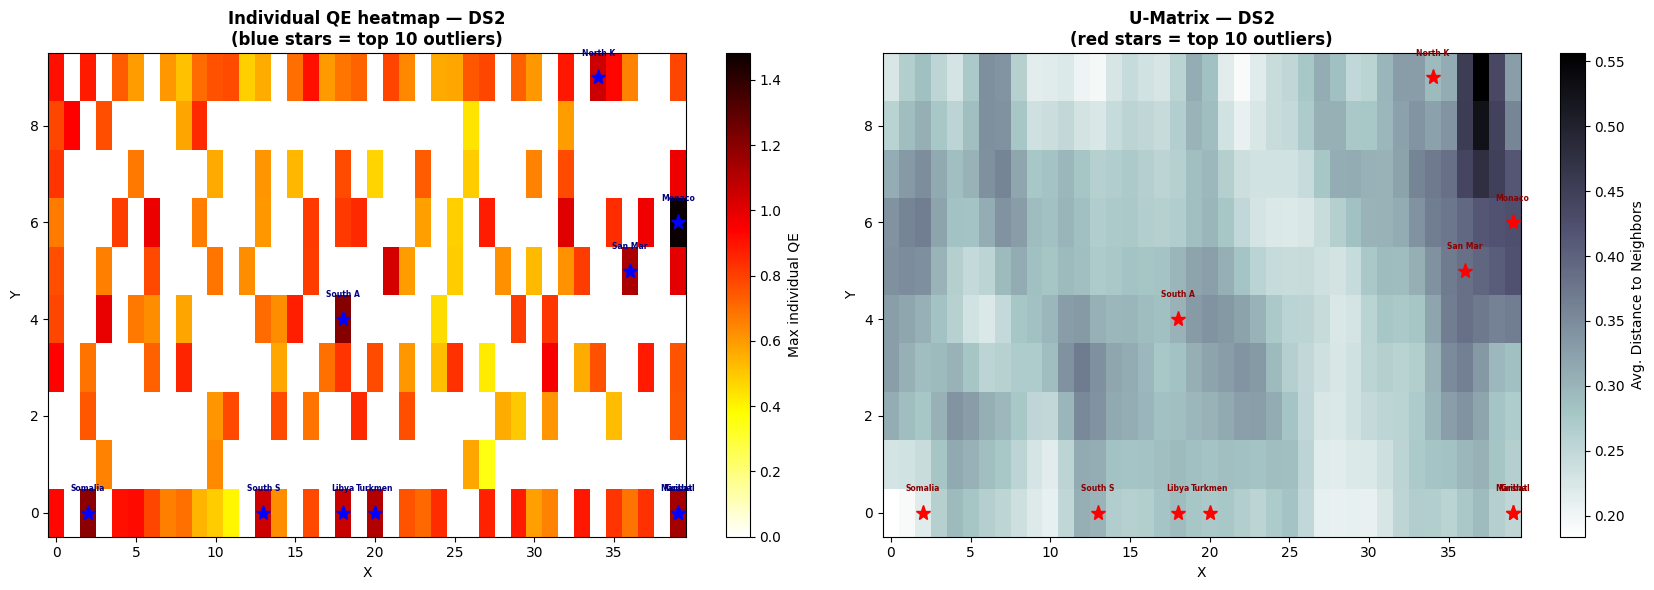

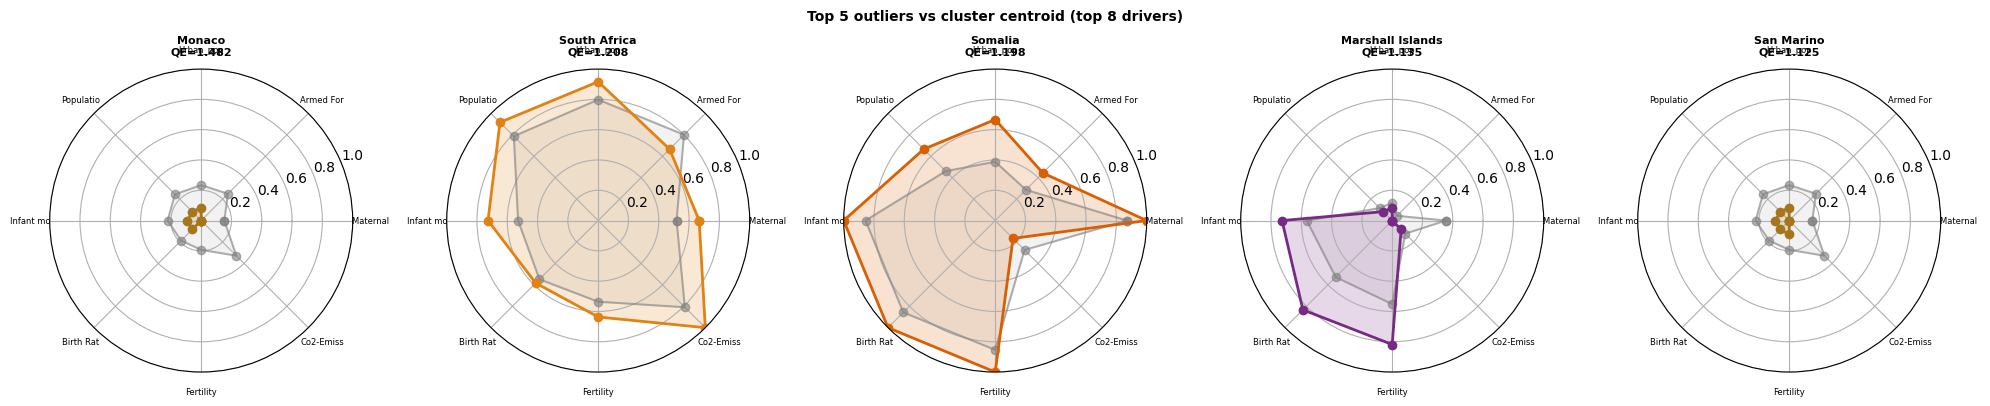

In [111]:


indiv_qe = {}
for country in dataset2_minmax.index:
    vec      = dataset2_minmax.loc[country].values
    bmu_w, _ = calculate_bmu(vec, best_model2, best_size2)
    indiv_qe[country] = np.linalg.norm(vec - bmu_w)

qe_series = pd.Series(indiv_qe).sort_values(ascending=False)
lonely    = [list(v)[0] for v in neuron_countries2.values() if len(v) == 1]

print(f"Topologically isolated countries (alone in neuron): {len(lonely)}")
print(f"\nTop 12 outliers by individual QE:")
print(f"  {'Country':<30} {'Ind. QE':>8}  Cluster")
print(f"  {'─'*55}")
for country, qe in qe_series.head(12).items():
    cid = country_clusters2.get(country, '?')
    lbl = cluster_names2.get(cid, '')[:25] if isinstance(cid, int) else ''
    iso = '  ← isolated neuron' if country in lonely else ''
    print(f"  {country:<30} {qe:>8.4f}  C{cid} {lbl}{iso}")


qe_map = np.zeros((best_size2[0], best_size2[1]))
for country, (bx, by) in country_bmu2.items():
    qe_map[bx, by] = max(qe_map[bx, by], indiv_qe[country])

top_out = qe_series.head(10).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

ax1 = axes[0]
im1 = ax1.imshow(qe_map.T, cmap='hot_r', origin='lower', aspect='auto')
plt.colorbar(im1, ax=ax1, label='Max individual QE')
for country in top_out:
    bx, by = country_bmu2[country]
    ax1.plot(bx, by, 'b*', markersize=11)
    ax1.text(bx, by + 0.45, country[:7], ha='center', fontsize=5.5,
             color='navy', fontweight='bold')
ax1.set_title('Individual QE heatmap — DS2\n(blue stars = top 10 outliers)',
              fontweight='bold')
ax1.set_xlabel('X'); ax1.set_ylabel('Y')

ax2 = axes[1]
im2 = ax2.imshow(umatrix2.T, cmap='bone_r', origin='lower', aspect='auto')
plt.colorbar(im2, ax=ax2, label='Avg. Distance to Neighbors')
for country in top_out:
    bx, by = country_bmu2[country]
    ax2.plot(bx, by, 'r*', markersize=11)
    ax2.text(bx, by + 0.45, country[:7], ha='center', fontsize=5.5,
             color='darkred', fontweight='bold')
ax2.set_title('U-Matrix — DS2\n(red stars = top 10 outliers)', fontweight='bold')
ax2.set_xlabel('X'); ax2.set_ylabel('Y')

plt.tight_layout()
plt.show()


top5_out = qe_series.head(5).index.tolist()
top8     = inter_var2.head(8).index.tolist()
ang      = np.linspace(0, 2*np.pi, len(top8), endpoint=False).tolist() + \
           [np.linspace(0, 2*np.pi, len(top8), endpoint=False)[0]]

fig, axes = plt.subplots(1, 5, figsize=(20, 4), subplot_kw=dict(polar=True))
for ax, country in zip(axes, top5_out):
    cid    = country_clusters2[country]
    c_vals = centroids2.loc[cid, top8].tolist() + [centroids2.loc[cid, top8[0]]]
    p_vals = dataset2_minmax.loc[country, top8].tolist() + \
             [dataset2_minmax.loc[country, top8[0]]]
    ax.plot(ang, c_vals, 'o-', lw=1.5, color='grey', alpha=0.6)
    ax.fill(ang, c_vals, alpha=0.10, color='grey')
    ax.plot(ang, p_vals, 'o-', lw=2, color=CUSTOM_COLORS[cid])
    ax.fill(ang, p_vals, alpha=0.18, color=CUSTOM_COLORS[cid])
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels([f[:9] for f in top8], size=6)
    ax.set_ylim(0, 1)
    ax.set_title(f'{country}\nQE={indiv_qe[country]:.3f}',
                 size=8, fontweight='bold', pad=10)
plt.suptitle('Top 5 outliers vs cluster centroid (top 8 drivers)',
             fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

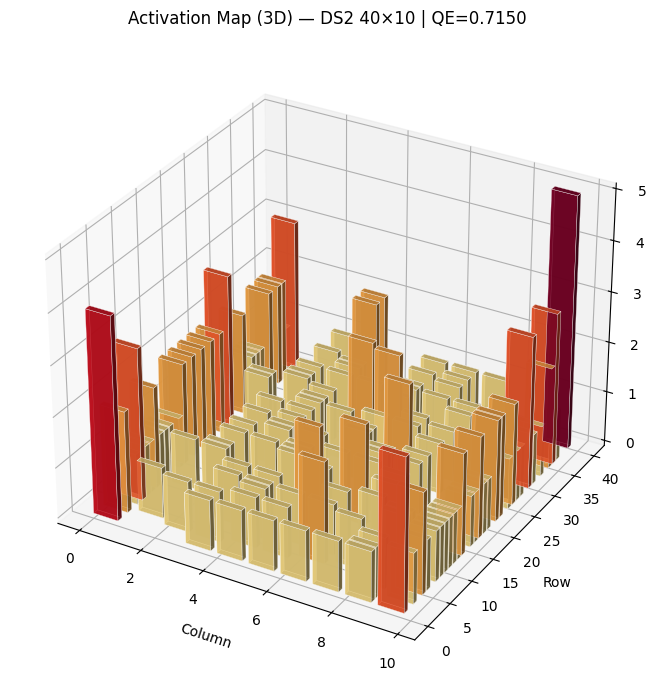

Active neurons: 150 / 400


In [112]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

weights    = trained_maps2[best_overall_name2]['weight_matrix']
rows, cols = trained_maps2[best_overall_name2]['size']
data2      = dataset2_minmax.values

def get_bmu(weights, x):
    dists = np.sqrt(((weights - x) ** 2).sum(axis=2))
    return np.unravel_index(np.argmin(dists), dists.shape)

activation_grid = np.zeros((rows, cols))
for i in range(len(data2)):
    r, c = get_bmu(weights, data2[i])
    activation_grid[r, c] += 1

xpos, ypos, zpos, dx, dy, dz = [], [], [], [], [], []
for r in range(rows):
    for c in range(cols):
        if activation_grid[r, c] > 0:
            xpos.append(c); ypos.append(r); zpos.append(0)
            dx.append(0.8); dy.append(0.8)
            dz.append(activation_grid[r, c])

fig = plt.figure(figsize=(14, 7))
ax  = fig.add_subplot(111, projection='3d')
colors = plt.cm.YlOrRd(np.array(dz) / max(dz))
ax.bar3d(xpos, ypos, zpos, dx, dy, dz,
         color=colors, alpha=0.85, edgecolor='white', linewidth=0.3)
ax.set_xlabel('Column', labelpad=8)
ax.set_ylabel('Row', labelpad=8)
ax.set_zlabel('Countries per neuron', labelpad=8)
ax.set_title(
    f'Activation Map (3D) — DS2 {rows}×{cols} '
    f'| QE={trained_maps2[best_overall_name2]["qe"]:.4f}', pad=15)
ax.view_init(elev=30, azim=-60)
plt.tight_layout()
plt.savefig('activation_map_3d.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Active neurons: {int(np.sum(activation_grid > 0))} / {rows*cols}")

In [113]:


import pandas as pd

rows_data = []
for name, res in sorted(trained_maps2.items(), key=lambda x: x[1]['qe']):
    cfg = next(c for c in configs2 if c['name'] == name)
    rows_data.append({
        'Model': name,
        'Size': f"{cfg['size'][0]}×{cfg['size'][1]}",
        'Topology': cfg['topology'].capitalize(),
        'LR': cfg['lr'],
        'Epochs': f"{cfg['epochs']//1000}k",
        'QE': f"{res['qe']:.4f}",
        'TE': f"{res['te']:.4f}",
        'Best': '✓' if name == best_overall_name2 else ''
    })

df = pd.DataFrame(rows_data)
print(df.to_string(index=False))

  Model  Size    Topology   LR Epochs     QE     TE Best
Model 7 40×10 Rectangular 0.10   200k 0.7150 0.0000    ✓
Model 9 40×10 Rectangular 0.05   600k 0.7177 0.0000     
Model 8 20×20      Square 0.05   600k 0.7236 0.0000     
Model 3 20×20      Square 0.10   200k 0.7250 0.0000     
Model 6 28×14 Rectangular 0.10   200k 0.7315 0.0000     
Model 2 17×17      Square 0.10   200k 0.7896 0.0000     
Model 5 24×10 Rectangular 0.10   200k 0.8169 0.0000     
Model 4 20×10 Rectangular 0.10   200k 0.8437 0.0000     
Model 1 14×14      Square 0.10   200k 0.8490 0.0000     


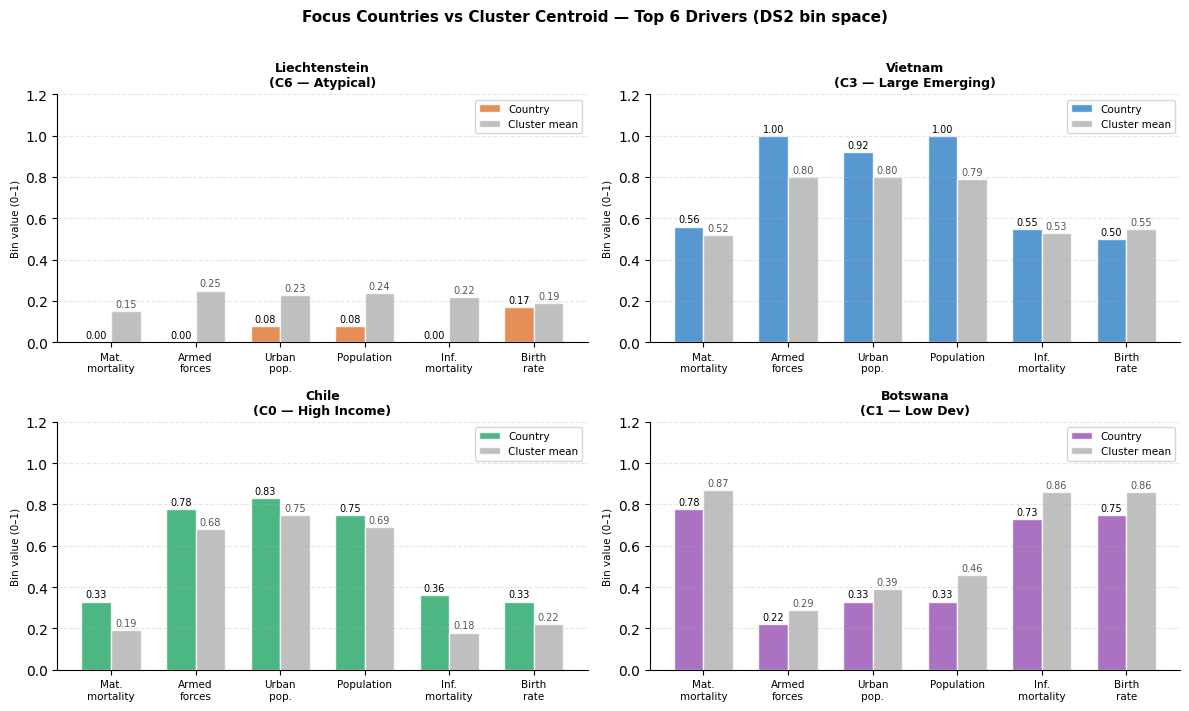

In [114]:


import matplotlib.pyplot as plt
import numpy as np


drivers = ['Mat.\nmortality', 'Armed\nforces', 'Urban\npop.', 'Population', 'Inf.\nmortality', 'Birth\nrate']

countries_data = {
    'Liechtenstein\n(C6 — Atypical)': {
        'country': [0.00, 0.00, 0.08, 0.08, 0.00, 0.17],
        'cluster':  [0.15, 0.25, 0.23, 0.24, 0.22, 0.19],
        'color': '#e07b39'
    },
    'Vietnam\n(C3 — Large Emerging)': {
        'country': [0.56, 1.00, 0.92, 1.00, 0.55, 0.50],
        'cluster':  [0.52, 0.80, 0.80, 0.79, 0.53, 0.55],
        'color': '#3a86c8'
    },
    'Chile\n(C0 — High Income)': {
        'country': [0.33, 0.78, 0.83, 0.75, 0.36, 0.33],
        'cluster':  [0.19, 0.68, 0.75, 0.69, 0.18, 0.22],
        'color': '#2eab6f'
    },
    'Botswana\n(C1 — Low Dev)': {
        'country': [0.78, 0.22, 0.33, 0.33, 0.73, 0.75],
        'cluster':  [0.87, 0.29, 0.39, 0.46, 0.86, 0.86],
        'color': '#9b59b6'
    }
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

x = np.arange(len(drivers))
bar_w = 0.35

for ax, (title, vals) in zip(axes, countries_data.items()):
    b1 = ax.bar(x - bar_w/2, vals['country'], bar_w,
                label='Country', color=vals['color'], alpha=0.85, edgecolor='white')
    b2 = ax.bar(x + bar_w/2, vals['cluster'], bar_w,
                label='Cluster mean', color='#aaaaaa', alpha=0.75, edgecolor='white')

    # Valor encima de cada barra
    for bar in b1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=7)
    for bar in b2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=7,
                color='#555555')

    ax.set_title(title, fontsize=9, fontweight='bold', pad=6)
    ax.set_xticks(x)
    ax.set_xticklabels(drivers, fontsize=7.5)
    ax.set_ylim(0, 1.2)
    ax.set_ylabel('Bin value (0–1)', fontsize=7.5)
    ax.legend(fontsize=7.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

fig.suptitle('Focus Countries vs Cluster Centroid — Top 6 Drivers (DS2 bin space)',
             fontsize=11, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('q3_barchart_focus_countries.png', dpi=150, bbox_inches='tight')
plt.show()

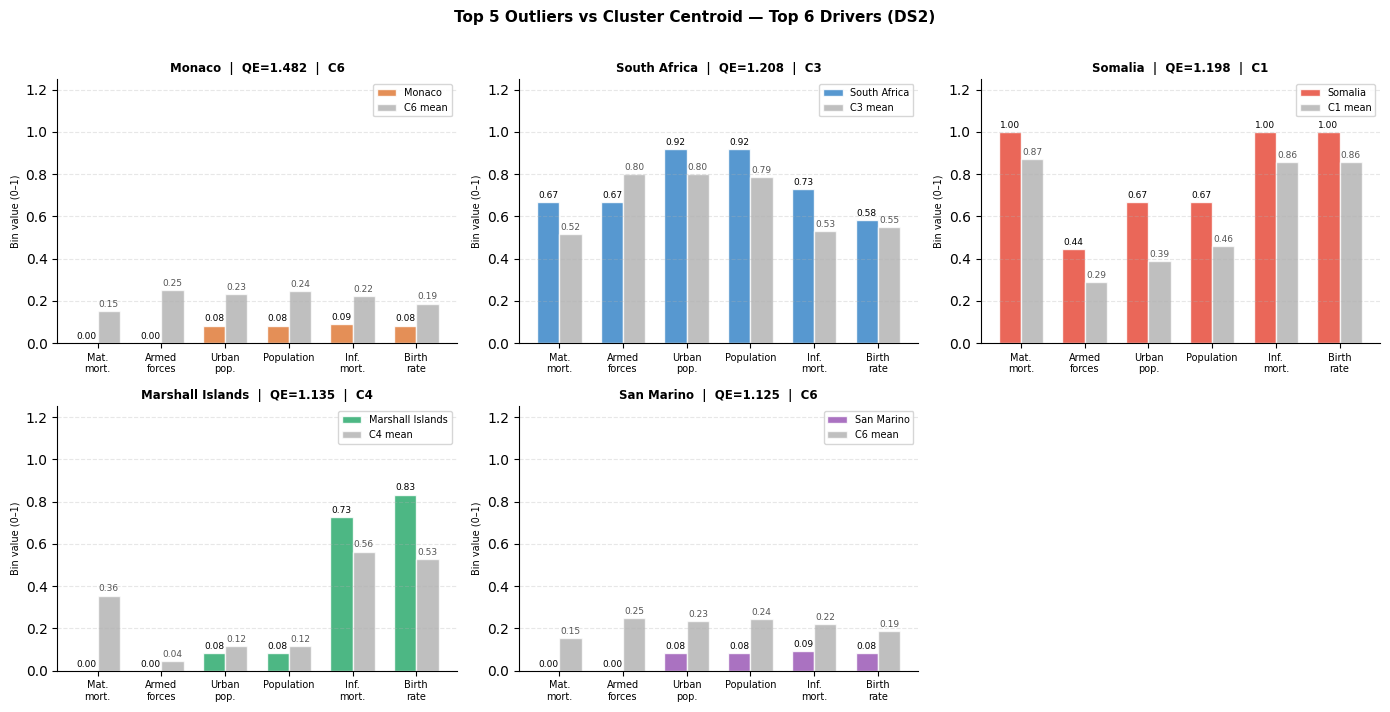

In [115]:


weights    = trained_maps2[best_overall_name2]['weight_matrix']
data2      = dataset2_minmax.values
countries2 = list(dataset2_minmax.index)

def get_bmu(weights, x):
    dists = np.sqrt(((weights - x) ** 2).sum(axis=2))
    return np.unravel_index(np.argmin(dists), dists.shape)

top5_outliers = ['Monaco', 'South Africa', 'Somalia', 'Marshall Islands', 'San Marino']
top5_qe       = [1.4823, 1.2080, 1.1984, 1.1354, 1.1251]
top5_clusters = [6, 3, 1, 4, 6]
top5_colors   = ['#e07b39', '#3a86c8', '#e74c3c', '#2eab6f', '#9b59b6']

driver_cols   = ['Maternal mortality ratio', 'Armed Forces size', 'Urban_population',
                 'Population', 'Infant mortality', 'Birth Rate']
driver_labels = ['Mat.\nmort.', 'Armed\nforces', 'Urban\npop.',
                 'Population', 'Inf.\nmort.', 'Birth\nrate']

cluster_means = {}
for cid in set(country_clusters2.values()):
    members = [c for c, cl in country_clusters2.items() if cl == cid]
    cluster_means[cid] = dataset2_minmax.loc[members, driver_cols].mean().values

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()
x, bar_w = np.arange(len(driver_cols)), 0.35

for i, (country, qe, cid, color) in enumerate(
        zip(top5_outliers, top5_qe, top5_clusters, top5_colors)):
    ax = axes[i]
    country_vals = dataset2_minmax.loc[country, driver_cols].values
    cluster_vals = cluster_means[cid]

    b1 = ax.bar(x - bar_w/2, country_vals, bar_w,
                label=country, color=color, alpha=0.85, edgecolor='white')
    b2 = ax.bar(x + bar_w/2, cluster_vals, bar_w,
                label=f'C{cid} mean', color='#aaaaaa', alpha=0.75, edgecolor='white')

    for bar in [*b1, *b2]:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom',
                fontsize=6.5, color='black' if bar in b1 else '#555')

    ax.set_title(f'{country}  |  QE={qe:.3f}  |  C{cid}',
                 fontsize=8.5, fontweight='bold', pad=5)
    ax.set_xticks(x)
    ax.set_xticklabels(driver_labels, fontsize=7)
    ax.set_ylim(0, 1.25)
    ax.set_ylabel('Bin value (0–1)', fontsize=7)
    ax.legend(fontsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

axes[5].set_visible(False)
fig.suptitle('Top 5 Outliers vs Cluster Centroid — Top 6 Drivers (DS2)',
             fontsize=11, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('q5_barchart_outliers.png', dpi=150, bbox_inches='tight')
plt.show()

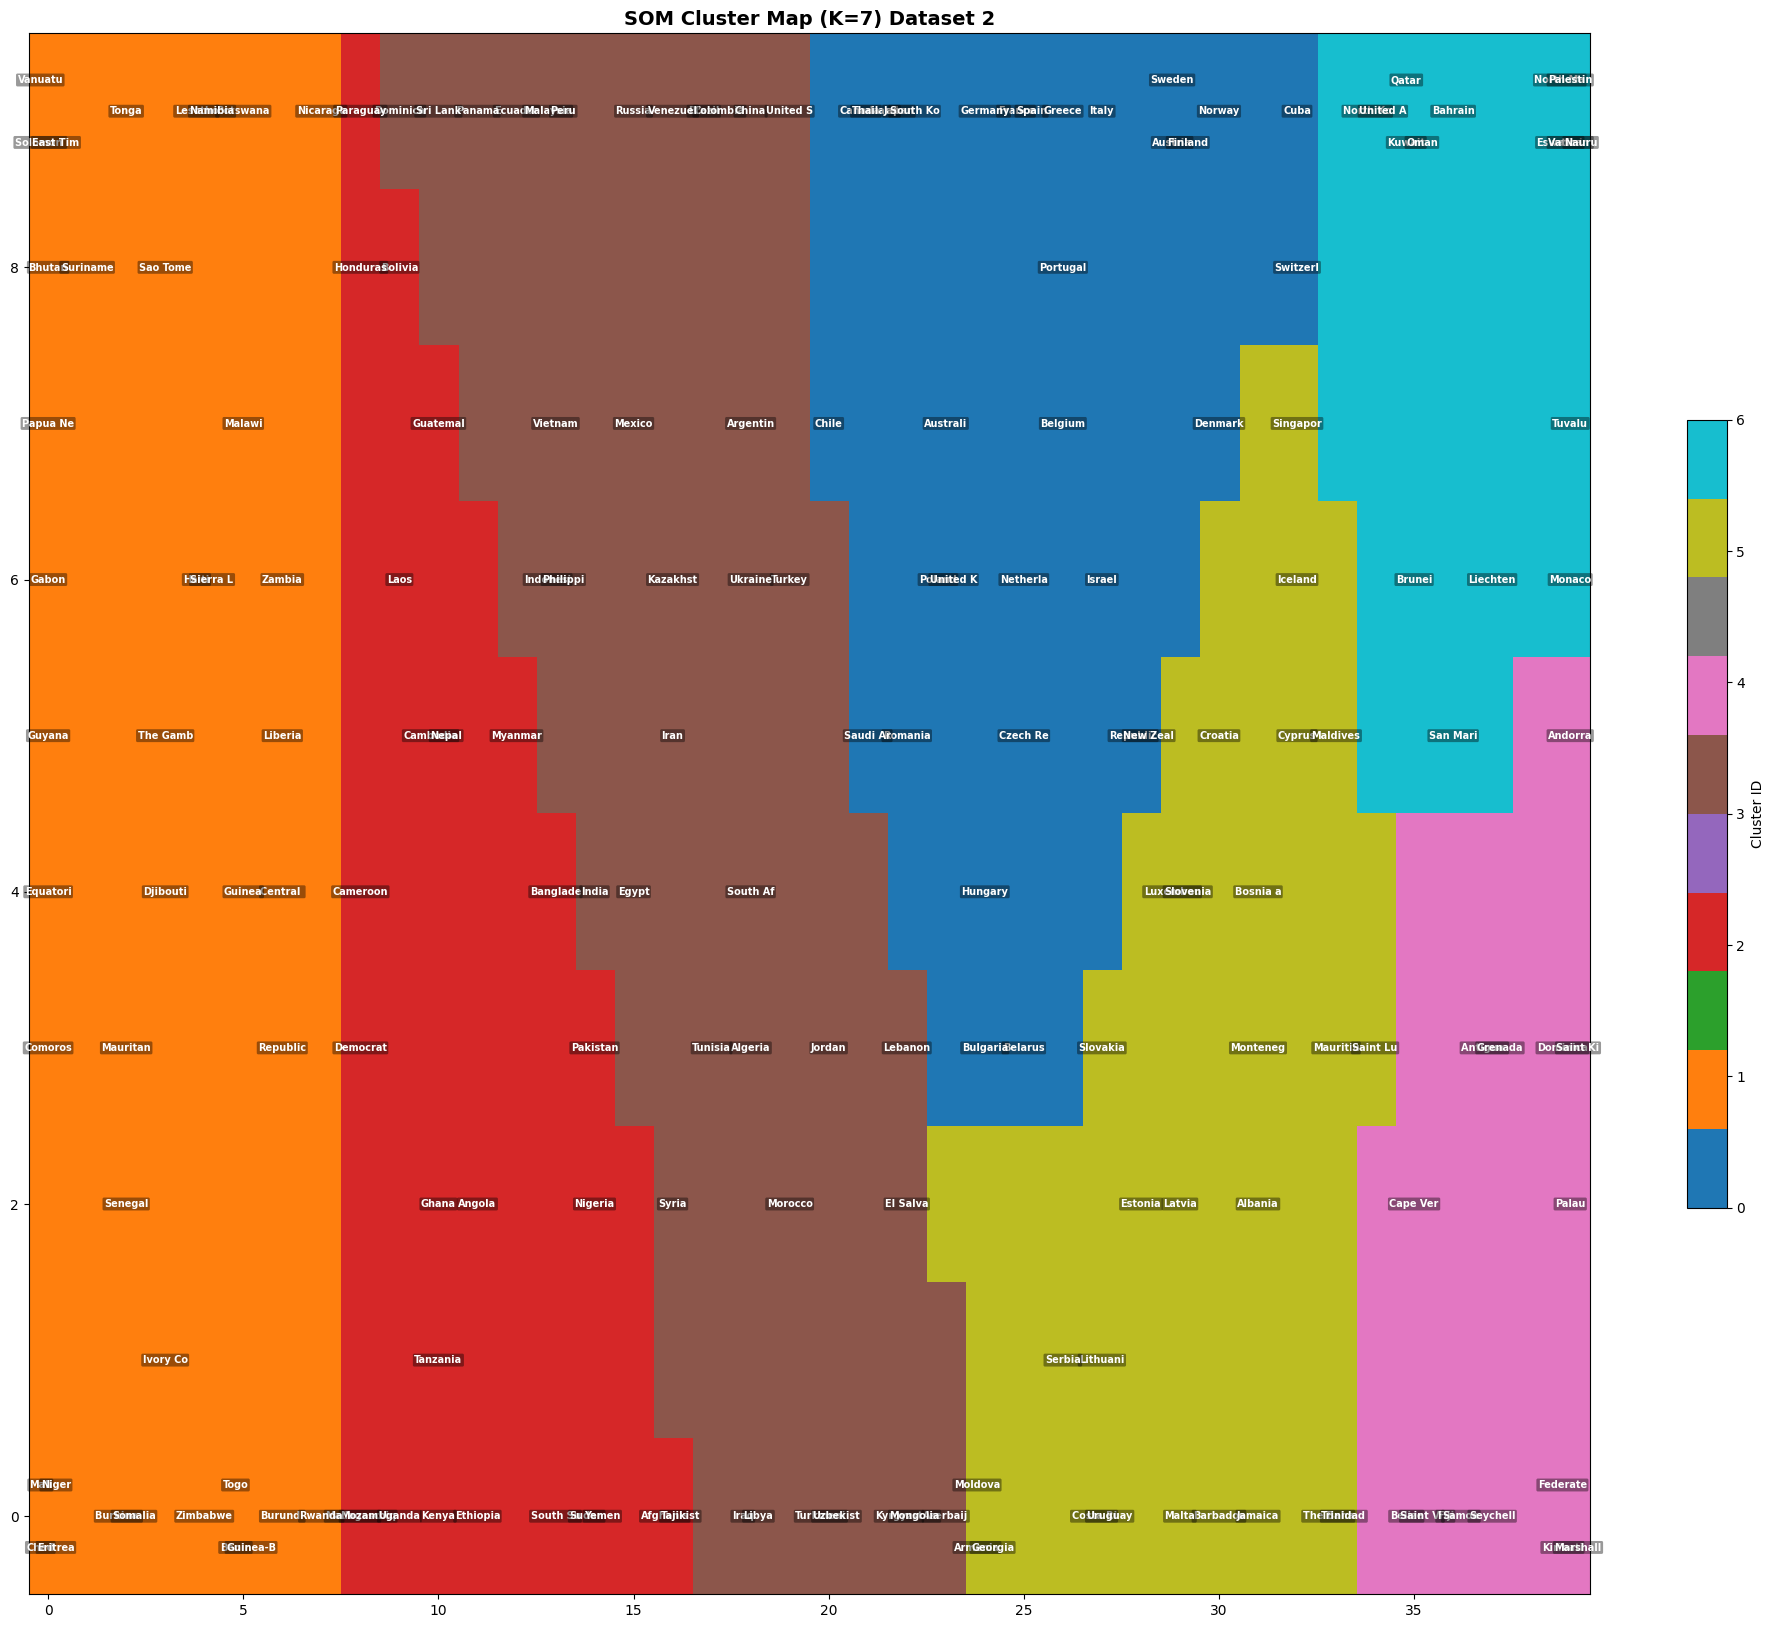

In [116]:
fig, ax = plt.subplots(figsize=(20, 20))
im = ax.imshow(km2.T, cmap='tab10', origin='lower', aspect=4, interpolation='nearest')
ax.set_title(f'SOM Cluster Map (K={neuron_labels2}) Dataset 2', fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax, label='Cluster ID', shrink=0.4)

from collections import defaultdict
neuron_groups = defaultdict(list)
for country, (bx, by) in country_bmu2.items():
    neuron_groups[(bx, by)].append(country)

for (bx, by), countries in neuron_groups.items():
    n    = len(countries)
    cols = int(np.ceil(np.sqrt(n)))
    rows = int(np.ceil(n / cols))
    for idx, country in enumerate(countries):
        row = idx // cols
        col = idx % cols
        x = bx - 0.4 + (col + 0.5) * (0.8 / cols)
        y = by - 0.4 + (row + 0.5) * (0.8 / rows)
        ax.text(x, y, country[:8], ha='center', va='center',
                fontsize=7, color='white', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.15', facecolor='black', alpha=0.4, linewidth=0))

plt.tight_layout()
plt.show()